# Sampling evaluation results

- Dependencies: Jupyter, pandas, NumPy, SciPy, Matplotlib
- Inputs: `evaluation.final.csv`, `evaluation.quality.csv`
- Combination: historical model × local model, within application and workload
- `corrected-<model>`: fixed historical model × build-specific correction factor learned by `<model>` from measurements on the target hardware

In [39]:
from io import BytesIO
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy.stats import t

In [40]:
RESULTS_DIR = Path("evaluation-results-3seeds-25steps")
HARDWARE = None  # Exact platform name or None for all platforms + average
EXPECTED_LAST_STEP = 25
EXPECTED_COLD_SEEDS = 3
TABLE_TOP_N = 10  # Maximum ranked combinations per table
PLOT_TOP_N = 5    # Maximum ranked combinations per plot
HW_COMPARISON_TOP_N = 5  # Average-ranked pairs to compare on every platform

## Snapshot and coverage

- Random baseline excluded from coverage, rankings, ranges and plots
- Completed sessions only: matching final row, full prediction trace, configured final step
- Completed combinations only: configured cold-start seed count; one historical run
- Snapshot coverage only; possible additional platforms, combinations and seeds
- Cross-hardware comparison: shared combinations with usable data on every observed platform

In [41]:
COMBO = ["application", "workload", "pretrained", "model"]
GROUP = ["platform", *COMBO]
RUN = [*GROUP, "seed"]
TIMINGS = ["prediction_seconds", "next_sample_seconds", "refit_seconds"]


def snapshot(name, columns):
    path = RESULTS_DIR / f"evaluation.{name}.csv"
    with path.open("rb") as file:
        data = file.read(path.stat().st_size)
    # Complete physical lines only; evaluation records use single-line fields
    return pd.read_csv(BytesIO(data[:data.rfind(b"\n") + 1]), usecols=columns,
                       keep_default_na=False, na_values=[""])


final = snapshot("final", [*RUN, "final_step", "prediction_count", "stable_final_build_round"])
quality = snapshot("quality", [
    *RUN, "step", "round", "recommended_measured_performance",
    "recommended_predicted_performance", "recommended_percent_of_best_observed",
    "recommended_percent_of_pool_best", *TIMINGS,
])
for frame in (final, quality):
    frame.drop(index=frame.index[frame["model"].eq("random")], inplace=True)
    frame["workload"] = frame["workload"].fillna("")

platforms = sorted(set(final["platform"]) | set(quality["platform"]))
if HARDWARE not in [None, *platforms]:
    raise ValueError(f"Unknown platform: {HARDWARE!r}. Available platforms: {platforms}")
if HARDWARE is not None:
    platforms = [HARDWARE]
    final = final.loc[final["platform"].eq(HARDWARE)].copy()
    quality = quality.loc[quality["platform"].eq(HARDWARE)].copy()

if final.duplicated(RUN).any() or quality.duplicated([*RUN, "step"]).any():
    raise ValueError("Duplicate session or prediction keys; use one evaluation campaign per directory.")

seen = pd.concat([quality[GROUP], final[GROUP]]).drop_duplicates()
trace = quality.groupby(RUN).agg(
    rows=("round", "size"), rounds=("round", "nunique"),
    first_round=("round", "min"), last_round=("round", "max"), last_step=("step", "max"),
)
final = final.merge(trace, on=RUN, how="inner", validate="one_to_one")
complete = (
    final["final_step"].eq(EXPECTED_LAST_STEP)
    & final["last_step"].eq(final["final_step"])
    & final["rows"].eq(final["prediction_count"])
    & final["rounds"].eq(final["prediction_count"])
    & (final["last_round"] - final["first_round"] + 1).eq(final["prediction_count"])
)
final = final.loc[complete].copy()
expected = np.where(final["pretrained"].eq("none"), EXPECTED_COLD_SEEDS, 1)
final = final.loc[final.groupby(GROUP)["seed"].transform("size").eq(expected)].copy()
quality = quality.merge(final[RUN], on=RUN, how="inner", validate="many_to_one")

coverage = pd.DataFrame(index=pd.Index(platforms, name="platform"))
coverage["Combinations seen"] = seen.groupby("platform").size()
coverage["Combinations ready"] = final[GROUP].drop_duplicates().groupby("platform").size()
coverage["Completed sessions in ready combinations"] = final.groupby("platform").size()
display(coverage.fillna(0).astype(int))

,Combinations seen,Combinations ready,Completed sessions in ready combinations
platform,,,
AMD Ryzen 7 5800X 8-Core Processor,420,420,460
AMD Ryzen 7 8845HS w/ Radeon 780M Graphics,420,420,460
AMD Ryzen 9 3900X 12-Core Processor,420,420,460
AMD Ryzen Threadripper 1950X 16-Core Processor + CUDA device,420,420,460
Cortex-X925 + CUDA device,420,420,460
Intel(R) Core(TM) i5-1038NG7 CPU @ 2.00GHz,380,380,420


## Metrics and ranking

- Accuracy (%): 100 × (1 − |predicted throughput − measured throughput| / measured throughput); negative above 100% relative error (e.g., predicted 250, measured 100 → −50%)
- Improvement (percentage points): last minus first prediction accuracy, paired within each session
- Recommendation quality (%): measured throughput of the recommended build ÷ best measured throughput in the full replay pool × 100
- Recommendation quality improvement (pp): last minus first recommendation quality within each session
- Local convergence (round): first round of the uninterrupted run of the final recommendation
- Timing (ms): mean per recorded round, then mean of session means; zero refit for no-op refits
- Missing throughput or timing: no imputation; unavailable metrics excluded from rankings
- Hardware means: equal session weights; 95% Student t intervals across seeds
- Cross-hardware means: equal hardware weights; 95% Student t intervals across hardware means
- Intervals: pointwise, exploratory; no interval with one replicate; no adjustment for selection
- Companion values: mean [95% CI], where available
- Hardware breakdown: select pairs by the cross-hardware ranking and keep that order on every platform. The tables report hardware mean minus cross-hardware mean in the metric’s units. Within each breakdown the plots share a horizontal scale.
- Ranges: min–max of eligible combination means, before applying the table or plot limit
- Ties: identical unrounded means; higher final recommendation quality (% of replay pool best), then higher final prediction accuracy, then alphabetical historical model, local model, application, workload. A missing tie-break metric sorts last.

In [42]:
quality = quality.sort_values([*RUN, "round"])
measured = quality["recommended_measured_performance"]
predicted = quality["recommended_predicted_performance"]
quality["accuracy"] = (100 * (1 - (predicted - measured).abs() / measured.where(measured.gt(0))))
quality["accuracy"] = quality["accuracy"].where(np.isfinite(quality["accuracy"]))

pool_share = quality["recommended_percent_of_pool_best"]
quality["pool_share"] = pool_share.where(np.isfinite(pool_share))
first_rows = quality.drop_duplicates(RUN).set_index(RUN)
last_rows = quality.drop_duplicates(RUN, keep="last").set_index(RUN)
last = last_rows["accuracy"]
final_quality = last_rows["recommended_percent_of_best_observed"]
final_quality = final_quality.where(np.isfinite(final_quality))
metrics = {
    "accuracy": last,
    "improvement": last - first_rows["accuracy"],
    "pool_share": last_rows["pool_share"],
    "pool_improvement": last_rows["pool_share"] - first_rows["pool_share"],
    "convergence": final.set_index(RUN)["stable_final_build_round"],
}
for field in TIMINGS:
    seconds = quality[field].where(np.isfinite(quality[field]) & quality[field].ge(0))
    final_seconds = last_rows[field]
    metrics[f"final_{field}"] = 1000 * final_seconds.where(
        np.isfinite(final_seconds) & final_seconds.ge(0)
    )
    per_run = seconds.groupby([quality[key] for key in RUN])
    metrics[field] = 1000 * per_run.mean().where(per_run.count().eq(per_run.size()))


def estimate(grouped):
    summary = grouped.agg(mean="mean", sd="std", n="count")
    margin = t.ppf(0.975, summary["n"] - 1) * summary["sd"] / np.sqrt(summary["n"])
    return summary.assign(low=summary["mean"] - margin, high=summary["mean"] + margin)


def summarize(frame, by=()):
    grouped = frame.groupby([*GROUP, *by], sort=False)["value"]
    local = estimate(grouped)
    if not by:
        local = local.loc[local["n"].eq(grouped.size())]
    local = local.loc[local["n"].gt(0)].reset_index()
    pooled = estimate(local.groupby([*COMBO, *by], sort=False)["mean"]).reset_index()
    pooled = pooled.loc[pooled["n"].eq(len(platforms))]
    return local, pooled


def name(row):
    return f"{row.pretrained} → {row.model}"


def scope_tables(local, pooled):
    for platform in platforms:
        yield platform, local.loc[local["platform"].eq(platform)]
    if HARDWARE is None:
        yield "Average across observed hardware", pooled


def estimate_text(mean, low, high):
    if pd.isna(mean):
        return "—"
    if pd.isna(low):
        return f"{mean:.6g}"
    return f"{mean:.6g} [{low:.6g}, {high:.6g}]"


def rankings(metric, unit, ascending=False, companions=None, companion_intervals=True):
    local, pooled = summarize(metrics[metric].rename("value").reset_index())
    companion_tables = {}
    for field, label in (companions or {}).items():
        field_local, field_pooled = summarize(metrics[field].rename("value").reset_index())
        companion_tables[label] = dict(scope_tables(field_local, field_pooled))

    tie_break_tables = {}
    for field in ("pool_share", "accuracy"):
        if field != metric:
            field_local, field_pooled = summarize(metrics[field].rename("value").reset_index())
            tie_break_tables[field] = dict(scope_tables(field_local, field_pooled))

    final_quality_by_scope = {}
    if metric == "convergence":
        quality_local, quality_pooled = summarize(final_quality.rename("value").reset_index())
        final_quality_by_scope = dict(scope_tables(quality_local, quality_pooled))

    result = {}
    for scope, estimates in scope_tables(local, pooled):
        display(Markdown(f"#### {scope}"))
        population = (final if "platform" not in estimates else final.loc[final["platform"].eq(scope)])
        if "platform" not in estimates:
            ready_count = int(population.groupby(COMBO)["platform"].nunique().eq(len(platforms)).sum())
        else:
            ready_count = len(population[COMBO].drop_duplicates())
        if estimates.empty:
            print(f"Eligible combinations: 0/{ready_count} ready · No ranking")
            result[scope] = estimates
            continue
        ordered = estimates
        for field, tables in tie_break_tables.items():
            values = tables[scope][[*COMBO, "mean"]].rename(columns={"mean": field})
            ordered = ordered.merge(values, on=COMBO, how="left", validate="one_to_one")
        alphabetical = ["pretrained", "model", "application", "workload"]
        order = ["mean", *tie_break_tables, *alphabetical]
        ordered = ordered.sort_values(
            order, ascending=[ascending, *([False] * len(tie_break_tables)), *([True] * len(alphabetical))]
        )
        ordered = ordered.reset_index(drop=True)
        if metric == "convergence":
            columns = {"mean": "quality_mean", "low": "quality_low", "high": "quality_high"}
            observed = final_quality_by_scope[scope][[*COMBO, *columns]].rename(columns=columns)
            ordered = ordered.merge(observed, on=COMBO, how="left", validate="one_to_one")
            eligible_quality = ordered["quality_mean"].dropna()
            if not eligible_quality.empty:
                print(f"Final quality range: {eligible_quality.min():.4g}% to "
                      f"{eligible_quality.max():.4g}% of best sampled")
        result[scope] = ordered
        print(f"Eligible combinations: {len(ordered)}/{ready_count} ready"
              f" · Range: {ordered['mean'].min():.8g} to {ordered['mean'].max():.8g} {unit}")
        if "platform" not in estimates:
            print(f"Range of all eligible per-hardware means: "
                  f"{local['mean'].min():.8g} to {local['mean'].max():.8g} {unit}")
        table_top = ordered.head(TABLE_TOP_N)
        if 0 < TABLE_TOP_N < len(ordered):
            cutoff_mean = table_top.iloc[-1]["mean"]
            tied = ordered["mean"].eq(cutoff_mean)
            cutoff = ordered.iloc[TABLE_TOP_N]["mean"] == cutoff_mean
            outcome = f"{tied.sum()} tied at table cutoff" if cutoff else "no tie at table cutoff"
            labels = {"pool_share": "final recommendation quality", "accuracy": "final prediction accuracy"}
            tie_breakers = " → ".join([*(labels[field] for field in tie_break_tables),
                                       "historical → local → application → workload (alphabetical)"])
            print(f"Tie-breaker: {tie_breakers}; {outcome}")
        view = table_top[[*COMBO, "mean", "low", "high", "n"]].copy()
        view.columns = ["Application", "Workload", "Historical", "Local", f"Mean ({unit})",
                        "95% CI lower", "95% CI upper",
                        "Seeds" if "platform" in estimates else "Platforms"]
        if metric == "convergence":
            for field, label in [
                ("quality_mean", "Final % of best sampled"),
                ("quality_low", "Final % CI lower"),
                ("quality_high", "Final % CI upper"),
            ]:
                view[label] = table_top[field]
        for label, tables in companion_tables.items():
            values = table_top[COMBO].merge(tables[scope][[*COMBO, "mean", "low", "high"]],
                                     on=COMBO, how="left", validate="one_to_one")
            if companion_intervals:
                view[label] = [estimate_text(row.mean, row.low, row.high)
                               for row in values.itertuples(index=False)]
            else:
                view[label] = values["mean"].to_numpy()
        if companions and not companion_intervals:
            columns = list(view.columns)
            view = view[[*columns[:4], *companions.values(), *columns[4:8]]]
        view.index += 1
        display(view.style.format(precision=8, na_rep="—"))
    return result

In [43]:
def plot_progress(ranked, metric="accuracy", label="Prediction accuracy (%)"):
    points = quality[[*RUN, "step", metric]].rename(columns={metric: "value"})
    local, pooled = summarize(points, by=["step"])
    for scope, estimates in scope_tables(local, pooled):
        top = ranked[scope].head(PLOT_TOP_N)
        if top.empty:
            continue
        fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
        steps = np.arange(quality["step"].min(), EXPECTED_LAST_STEP + 1)
        for rank, row in enumerate(top.itertuples(index=False), 1):
            match = estimates.merge(pd.DataFrame([{key: getattr(row, key) for key in COMBO}]),
                                    on=COMBO)
            values = match.set_index("step").reindex(steps)
            line, = ax.plot(steps, values["mean"], marker=".", label=f"{rank}. {name(row)}")
            ax.fill_between(steps, values["low"], values["high"], alpha=0.14, color=line.get_color())
        ax.set(title=scope, xlabel="Benchmark step", ylabel=label)
        ax.set_xticks(steps[::max(1, len(steps) // 12)])
        ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
        ax.grid(axis="y", alpha=0.25)
        plt.show()
        plt.close(fig)


def draw_bars(ax, y, mean, low, high, label, color):
    ax.barh(y, mean, color=color, alpha=0.8)
    has_ci = low.notna()
    if has_ci.any():
        center = mean[has_ci]
        errors = [center - low[has_ci], high[has_ci] - center]
        ax.errorbar(center.to_numpy(), y[has_ci], xerr=np.asarray(errors), fmt="none", color="black", capsize=3)
    ax.set_xlabel(label)
    ax.grid(axis="x", alpha=0.25)


def plot_bars(ranked, label, show_final_quality=False, top_n=None, xlim=None):
    if top_n is None:
        top_n = PLOT_TOP_N
    for scope, rows in ranked.items():
        top = rows.head(top_n)
        if top.empty:
            continue
        panels = 2 if show_final_quality else 1
        fig, axes = plt.subplots(1, panels, figsize=(11 if show_final_quality else 9, 3.5),
                                 layout="constrained", sharey=True, squeeze=False)
        ax = axes[0, 0]
        y = np.arange(len(top))
        draw_bars(ax, y, top["mean"], top["low"], top["high"], label, "tab:blue")
        ax.set_yticks(y, [f"{i}. {name(row)}" for i, row in enumerate(top.itertuples(), 1)])
        ax.invert_yaxis()
        if xlim is not None:
            ax.set_xlim(xlim)
        fig.suptitle(scope)
        if show_final_quality:
            quality_ax = axes[0, 1]
            draw_bars(quality_ax, y, top["quality_mean"], top["quality_low"], top["quality_high"],
                      "Final recommendation (% of best sampled)", "tab:green")
            quality_ax.axvline(100, color="0.4", linestyle="--", linewidth=1)
            for row, value in enumerate(top["quality_mean"]):
                if np.isfinite(value):
                    quality_ax.annotate(f"{value:.1f}%", (value, row), xytext=(-4, -9),
                                        textcoords="offset points", ha="right", fontsize=8)
        plt.show()
        plt.close(fig)

def compare_hardware(ranked, metric, unit, plot_label):
    if HARDWARE is not None:
        print("Set HARDWARE = None to compare across all platforms.")
        return
    average_scope = "Average across observed hardware"
    average = ranked[average_scope].head(HW_COMPARISON_TOP_N)
    if average.empty:
        print("No combinations available for this cross-hardware comparison.")
        return

    selected = average[[*COMBO, "mean"]].rename(columns={"mean": "average_mean"})
    local, _ = summarize(metrics[metric].rename("value").reset_index())
    comparison = {average_scope: average}
    for platform in platforms:
        estimates = local.loc[local["platform"].eq(platform), [*COMBO, "mean", "low", "high", "n"]]
        comparison[platform] = selected.merge(estimates, on=COMBO, validate="one_to_one")

    for scope, rows in comparison.items():
        display(Markdown(f"**{scope}**"))
        view = rows[[*COMBO, "mean", "low", "high", "n"]].copy()
        is_average = scope == average_scope
        view.columns = ["Application", "Workload", "Historical", "Local", f"Mean ({unit})",
                        "95% CI lower", "95% CI upper", "Platforms" if is_average else "Seeds"]
        if not is_average:
            view[f"Difference from average ({unit})"] = rows["mean"] - rows["average_mean"]
        view.index = pd.RangeIndex(1, len(view) + 1, name="Average rank")
        display(view.style.format(precision=8, na_rep="—"))

    values = pd.concat([rows[["mean", "low", "high"]] for rows in comparison.values()])
    left = min(0, values.min().min())
    right = max(0, values.max().max())
    padding = 0.05 * (right - left or 1)
    plot_bars(comparison, plot_label, top_n=HW_COMPARISON_TOP_N,
              xlim=(left - padding if left < 0 else 0, right + padding))


## 1. Final prediction accuracy

In [44]:
final_top = rankings("accuracy", "%", companions={"pool_share": "Final % of pool best"})

#### AMD Ryzen 7 5800X 8-Core Processor

Eligible combinations: 420/420 ready · Range: -2.2088901 to 99.999999 %
Tie-breaker: final recommendation quality → historical → local → application → workload (alphabetical); no tie at table cutoff


,Application,Workload,Historical,Local,Mean (%),95% CI lower,95% CI upper,Seeds,Final % of pool best
1,llama.cpp,"[[0, 128], [512, 0]]",catboost,corrected-gaussian-process,99.99999889,—,—,1,98.6799
2,llama.cpp,"[[0, 128], [512, 0]]",catboost,corrected-no-hardware-gaussian-process,99.99999889,—,—,1,98.6799
3,llama.cpp,"[[0, 128], [512, 0]]",bayes-pairs,corrected-gaussian-process,99.99999854,—,—,1,98.6799
4,llama.cpp,"[[0, 128], [512, 0]]",bayes-pairs,corrected-no-hardware-gaussian-process,99.99999854,—,—,1,98.6799
5,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-catboost,corrected-gaussian-process,99.99999827,—,—,1,98.6799
6,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-catboost,corrected-no-hardware-gaussian-process,99.99999827,—,—,1,98.6799
7,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-gaussian-process,99.99999801,—,—,1,99.5167
8,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-gaussian-process,99.99999801,—,—,1,99.5167
9,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-random-forest,corrected-gaussian-process,99.99999788,—,—,1,98.3316
10,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-random-forest,corrected-no-hardware-gaussian-process,99.99999788,—,—,1,98.3316


#### AMD Ryzen 7 8845HS w/ Radeon 780M Graphics

Eligible combinations: 420/420 ready · Range: -95.805031 to 100 %
Tie-breaker: final recommendation quality → historical → local → application → workload (alphabetical); no tie at table cutoff


,Application,Workload,Historical,Local,Mean (%),95% CI lower,95% CI upper,Seeds,Final % of pool best
1,llama.cpp,"[[0, 128], [512, 0]]",bayes-pairs,corrected-gaussian-process,99.99999952,—,—,1,91.7794
2,llama.cpp,"[[0, 128], [512, 0]]",bayes-pairs,corrected-no-hardware-gaussian-process,99.99999952,—,—,1,91.7794
3,llama.cpp,"[[0, 128], [512, 0]]",hardware-three-way,corrected-hardware-interactions,99.99999626,—,—,1,91.7794
4,llama.cpp,"[[0, 128], [512, 0]]",hardware-three-way,corrected-hardware-three-way,99.99999626,—,—,1,91.7794
5,llama.cpp,"[[0, 128], [512, 0]]",hardware-three-way,corrected-no-hardware-interactions,99.99999626,—,—,1,91.7794
6,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-random-forest,corrected-bayes-pairs,99.99997905,—,—,1,100
7,llama.cpp,"[[0, 128], [512, 0]]",bayes-pairs,corrected-bayes-pairs,99.99997732,—,—,1,91.7794
8,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-random-forest,corrected-gaussian-process,99.99997724,—,—,1,100
9,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-random-forest,corrected-no-hardware-gaussian-process,99.99997724,—,—,1,100
10,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-bayes-pairs,99.99997378,—,—,1,100


... (11 outputs left out)

,Application,Workload,Historical,Local,Mean (%),95% CI lower,95% CI upper,Seeds,Final % of pool best
1,llama.cpp,"[[0, 128], [512, 0]]",catboost,corrected-bayes-pairs,99.99999781,—,—,1,87.51
2,llama.cpp,"[[0, 128], [512, 0]]",catboost,corrected-gaussian-process,99.99999382,—,—,1,87.51
3,llama.cpp,"[[0, 128], [512, 0]]",catboost,corrected-no-hardware-gaussian-process,99.99999382,—,—,1,87.51
4,llama.cpp,"[[0, 128], [512, 0]]",smac-forest,corrected-gaussian-process,99.99996753,—,—,1,91.2511
5,llama.cpp,"[[0, 128], [512, 0]]",smac-forest,corrected-no-hardware-gaussian-process,99.99996753,—,—,1,91.2511
6,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-gaussian-process,99.99996606,—,—,1,100
7,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-no-hardware-gaussian-process,99.99996606,—,—,1,100
8,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-interactions,corrected-gaussian-process,99.99996225,—,—,1,100
9,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-interactions,corrected-no-hardware-gaussian-process,99.99996225,—,—,1,100
10,llama.cpp,"[[0, 128], [512, 0]]",sparse-bayes,corrected-gaussian-process,99.99996160,—,—,1,100


#### Average across observed hardware

Eligible combinations: 380/380 ready · Range: 11.045246 to 99.999982 %
Range of all eligible per-hardware means: -95.805031 to 100 %
Tie-breaker: final recommendation quality → historical → local → application → workload (alphabetical); no tie at table cutoff


,Application,Workload,Historical,Local,Mean (%),95% CI lower,95% CI upper,Platforms,Final % of pool best
1,llama.cpp,"[[0, 128], [512, 0]]",bayes-pairs,corrected-gaussian-process,99.99998197,99.99996319,100.00000075,6,"98.3178 [94.9163, 101.719]"
2,llama.cpp,"[[0, 128], [512, 0]]",bayes-pairs,corrected-no-hardware-gaussian-process,99.99998197,99.99996319,100.00000075,6,"98.3178 [94.9163, 101.719]"
3,llama.cpp,"[[0, 128], [512, 0]]",catboost,corrected-bayes-pairs,99.99997818,99.99993818,100.00001818,6,"96.8298 [91.8023, 101.857]"
4,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-bayes-pairs,99.99997502,99.99993979,100.00001025,6,"99.8768 [99.721, 100.033]"
5,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-kernel-ridge,corrected-bayes-pairs,99.99997109,99.99994028,100.00000190,6,"99.6516 [99.1876, 100.116]"
6,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-random-forest,corrected-bayes-pairs,99.99996646,99.99992259,100.00001033,6,"99.6904 [98.9564, 100.424]"
7,llama.cpp,"[[0, 128], [512, 0]]",no-hardware,corrected-bayes-pairs,99.99996613,99.99993603,99.99999622,6,"99.4781 [98.836, 100.12]"
8,llama.cpp,"[[0, 128], [512, 0]]",smac-forest,corrected-bayes-pairs,99.99996558,99.99992035,100.00001080,6,"99.3411 [98.1849, 100.497]"
9,llama.cpp,"[[0, 128], [512, 0]]",sparse-bayes,corrected-bayes-pairs,99.99996479,99.99993451,99.99999508,6,"99.3019 [98.1706, 100.433]"
10,llama.cpp,"[[0, 128], [512, 0]]",random-forest,corrected-bayes-pairs,99.99996429,99.99991432,100.00001425,6,"99.3411 [98.1849, 100.497]"


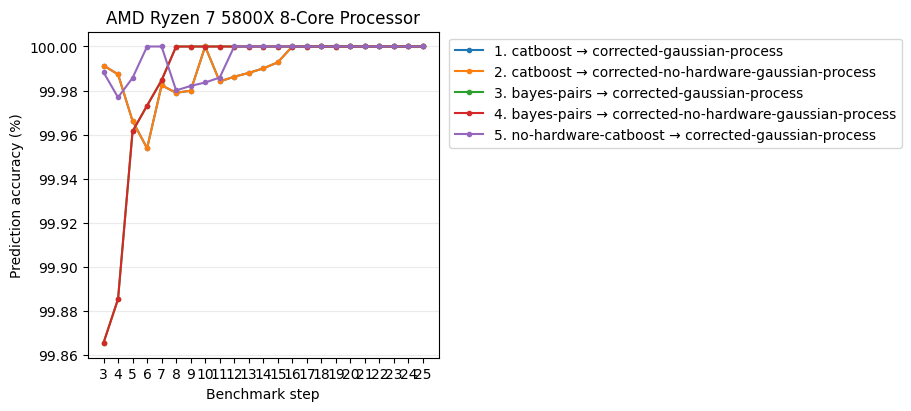

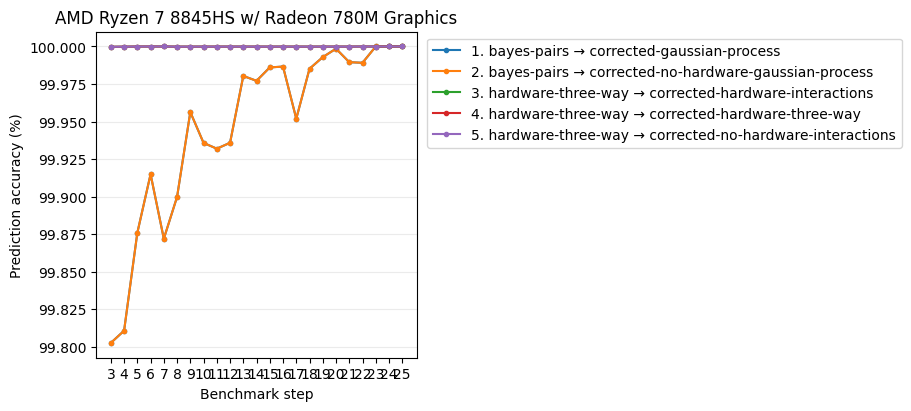

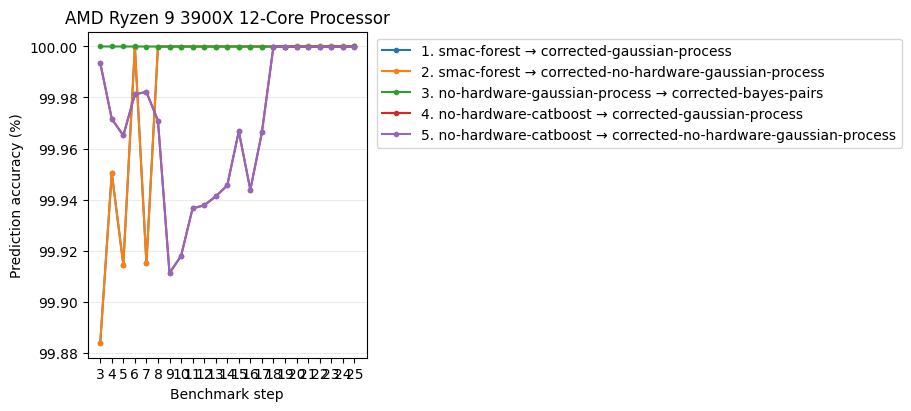

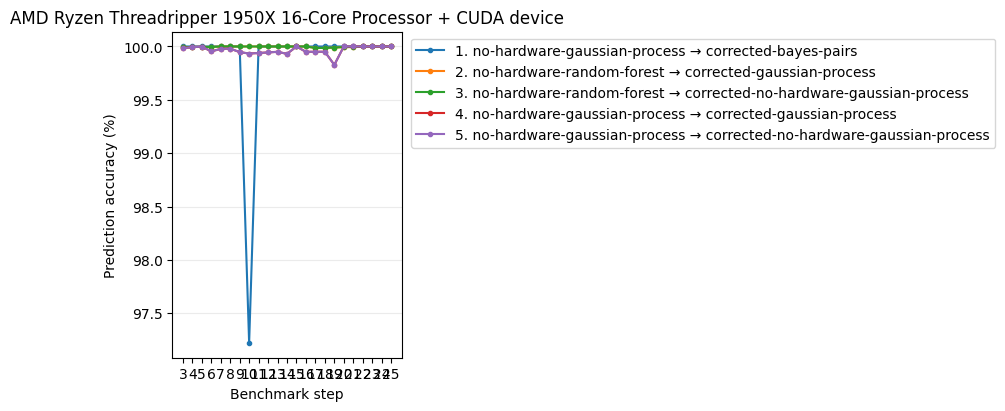

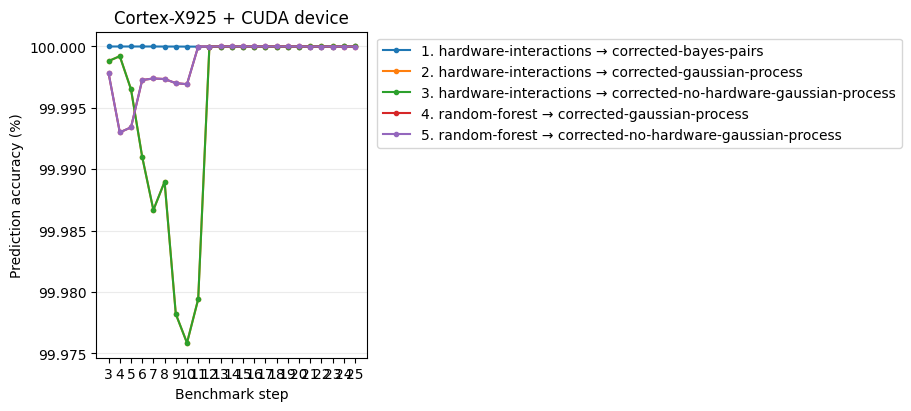

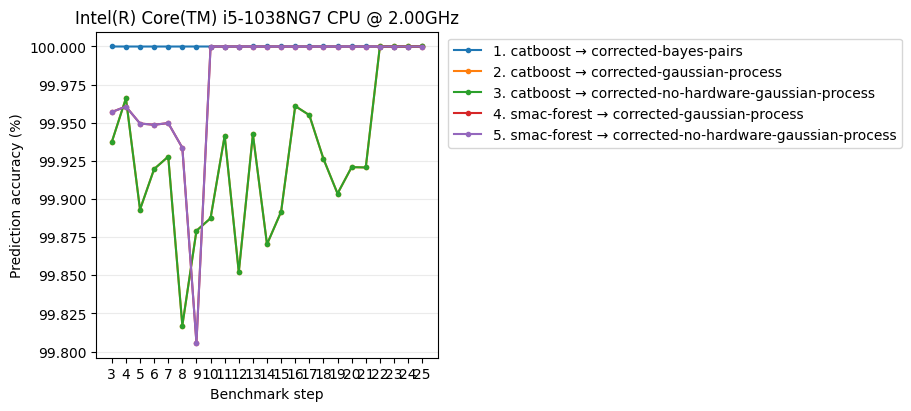

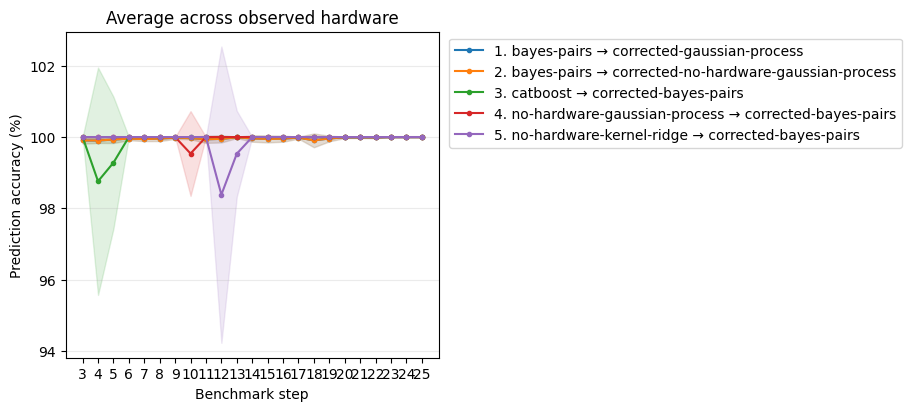

In [45]:
plot_progress(final_top)

### Cross-hardware breakdown

**Average across observed hardware**

,Application,Workload,Historical,Local,Mean (%),95% CI lower,95% CI upper,Platforms
Average rank,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",bayes-pairs,corrected-gaussian-process,99.99998197,99.99996319,100.00000075,6
2,llama.cpp,"[[0, 128], [512, 0]]",bayes-pairs,corrected-no-hardware-gaussian-process,99.99998197,99.99996319,100.00000075,6
3,llama.cpp,"[[0, 128], [512, 0]]",catboost,corrected-bayes-pairs,99.99997818,99.99993818,100.00001818,6
4,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-bayes-pairs,99.99997502,99.99993979,100.00001025,6
5,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-kernel-ridge,corrected-bayes-pairs,99.99997109,99.99994028,100.00000190,6


**AMD Ryzen 7 5800X 8-Core Processor**

,Application,Workload,Historical,Local,Mean (%),95% CI lower,95% CI upper,Seeds,Difference from average (%)
Average rank,,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",bayes-pairs,corrected-gaussian-process,99.99999854,—,—,1,0.00001657
2,llama.cpp,"[[0, 128], [512, 0]]",bayes-pairs,corrected-no-hardware-gaussian-process,99.99999854,—,—,1,0.00001657
3,llama.cpp,"[[0, 128], [512, 0]]",catboost,corrected-bayes-pairs,99.99999531,—,—,1,0.00001713
4,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-bayes-pairs,99.99999275,—,—,1,0.00001773
5,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-kernel-ridge,corrected-bayes-pairs,99.99998444,—,—,1,0.00001335


**AMD Ryzen 7 8845HS w/ Radeon 780M Graphics**

,Application,Workload,Historical,Local,Mean (%),95% CI lower,95% CI upper,Seeds,Difference from average (%)
Average rank,,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",bayes-pairs,corrected-gaussian-process,99.99999952,—,—,1,0.00001755
2,llama.cpp,"[[0, 128], [512, 0]]",bayes-pairs,corrected-no-hardware-gaussian-process,99.99999952,—,—,1,0.00001755
3,llama.cpp,"[[0, 128], [512, 0]]",catboost,corrected-bayes-pairs,99.99990088,—,—,1,-0.00007730
4,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-bayes-pairs,99.99993138,—,—,1,-0.00004364
5,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-kernel-ridge,corrected-bayes-pairs,99.99993973,—,—,1,-0.00003136


... (4 outputs left out)

**Cortex-X925 + CUDA device**

,Application,Workload,Historical,Local,Mean (%),95% CI lower,95% CI upper,Seeds,Difference from average (%)
Average rank,,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",bayes-pairs,corrected-gaussian-process,99.99999439,—,—,1,0.00001242
2,llama.cpp,"[[0, 128], [512, 0]]",bayes-pairs,corrected-no-hardware-gaussian-process,99.99999439,—,—,1,0.00001242
3,llama.cpp,"[[0, 128], [512, 0]]",catboost,corrected-bayes-pairs,99.99999772,—,—,1,0.00001954
4,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-bayes-pairs,99.99999677,—,—,1,0.00002175
5,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-kernel-ridge,corrected-bayes-pairs,99.99999186,—,—,1,0.00002077


**Intel(R) Core(TM) i5-1038NG7 CPU @ 2.00GHz**

,Application,Workload,Historical,Local,Mean (%),95% CI lower,95% CI upper,Seeds,Difference from average (%)
Average rank,,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",bayes-pairs,corrected-gaussian-process,99.99995675,—,—,1,-0.00002522
2,llama.cpp,"[[0, 128], [512, 0]]",bayes-pairs,corrected-no-hardware-gaussian-process,99.99995675,—,—,1,-0.00002522
3,llama.cpp,"[[0, 128], [512, 0]]",catboost,corrected-bayes-pairs,99.99999781,—,—,1,0.00001963
4,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-bayes-pairs,99.99993217,—,—,1,-0.00004285
5,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-kernel-ridge,corrected-bayes-pairs,99.99992780,—,—,1,-0.00004329


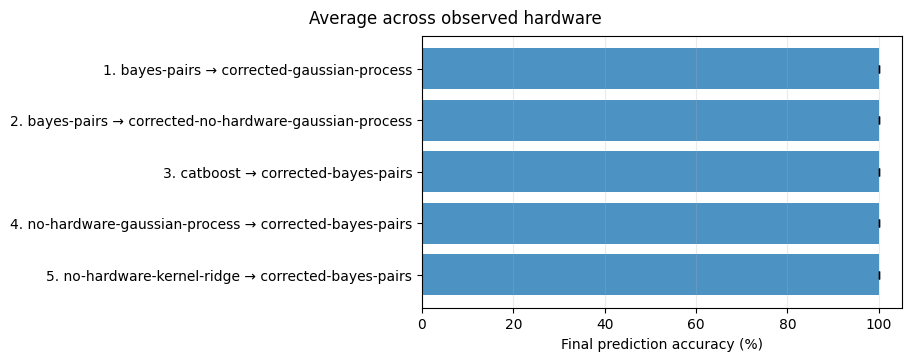

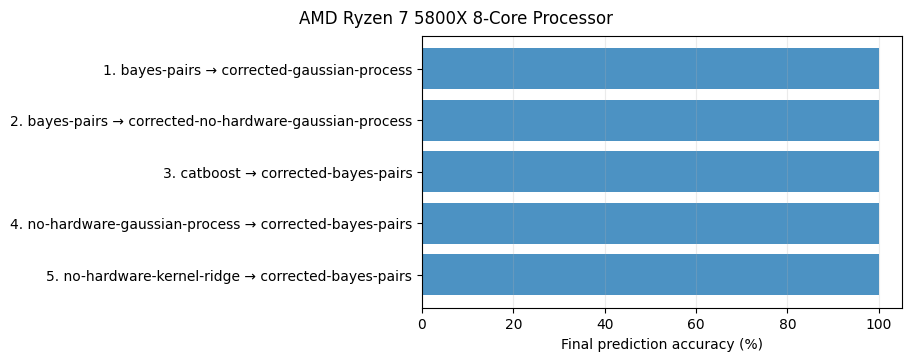

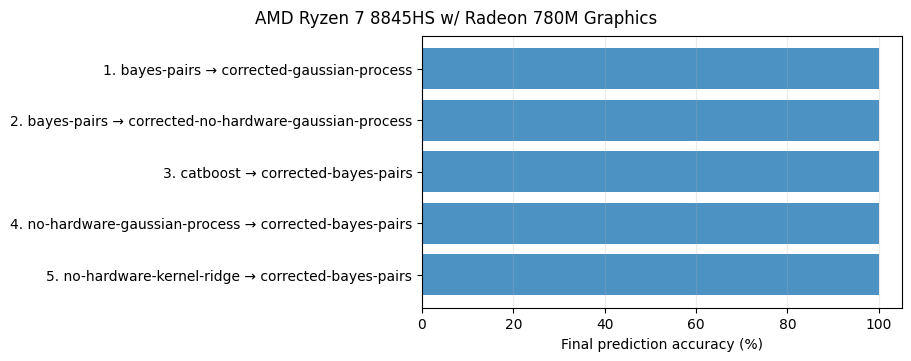

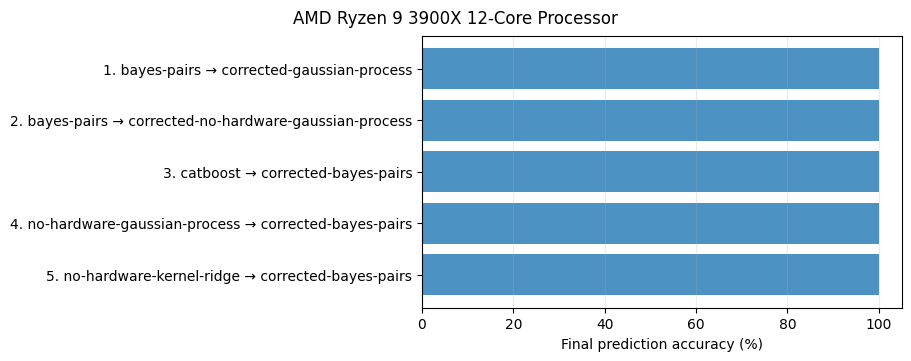

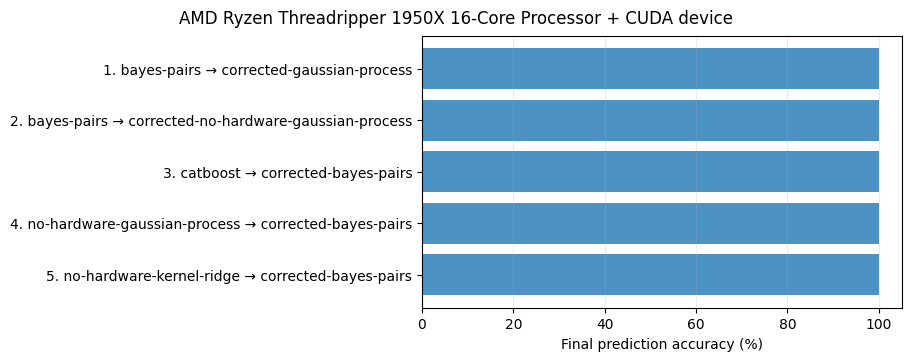

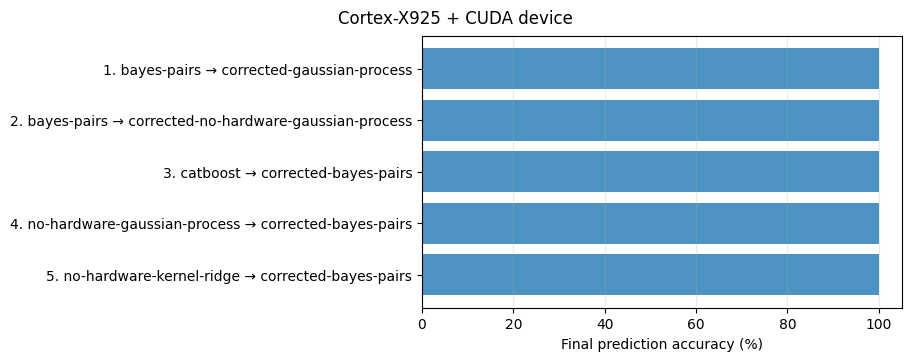

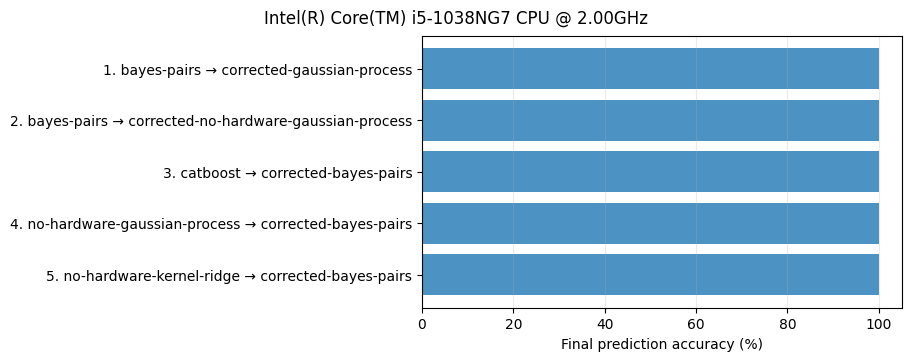

In [46]:
compare_hardware(final_top, "accuracy", "%", "Final prediction accuracy (%)")

## 2. First-to-last accuracy improvement

In [47]:
improvement_top = rankings("improvement", "pp", companions={
    "pool_share": "Final % of pool best", "pool_improvement": "Pool share gain (pp)",
})

#### AMD Ryzen 7 5800X 8-Core Processor

Eligible combinations: 420/420 ready · Range: -83.689251 to 2.5898291 pp
Tie-breaker: final recommendation quality → final prediction accuracy → historical → local → application → workload (alphabetical); no tie at table cutoff


,Application,Workload,Historical,Local,Mean (pp),95% CI lower,95% CI upper,Seeds,Final % of pool best,Pool share gain (pp)
1,llama.cpp,"[[0, 128], [512, 0]]",support-vector,corrected-no-hardware-small-mlp,2.58982908,—,—,1,98.932,1.91764
2,llama.cpp,"[[0, 128], [512, 0]]",support-vector,corrected-small-mlp,2.58982908,—,—,1,98.932,1.91764
3,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-small-mlp,2.14017023,—,—,1,99.5167,0
4,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-small-mlp,2.14017023,—,—,1,99.5167,0
5,llama.cpp,"[[0, 128], [512, 0]]",kernel-ridge,corrected-no-hardware-small-mlp,1.80064508,—,—,1,98.932,0.62883
6,llama.cpp,"[[0, 128], [512, 0]]",kernel-ridge,corrected-small-mlp,1.80064508,—,—,1,98.932,0.62883
7,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-kernel-ridge,corrected-no-hardware-small-mlp,1.26476087,—,—,1,98.6799,0.376749
8,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-kernel-ridge,corrected-small-mlp,1.26476087,—,—,1,98.6799,0.376749
9,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-support-vector,corrected-no-hardware-small-mlp,1.18234531,—,—,1,98.932,1.91764
10,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-support-vector,corrected-small-mlp,1.18234531,—,—,1,98.932,1.91764


#### AMD Ryzen 7 8845HS w/ Radeon 780M Graphics

Eligible combinations: 420/420 ready · Range: -147.92058 to 71.596625 pp
Tie-breaker: final recommendation quality → final prediction accuracy → historical → local → application → workload (alphabetical); 2 tied at table cutoff


,Application,Workload,Historical,Local,Mean (pp),95% CI lower,95% CI upper,Seeds,Final % of pool best,Pool share gain (pp)
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-random-forest,71.59662507,36.72149507,106.47175507,3,"96.8088 [83.078, 110.54]","70.6758 [56.945, 84.4065]"
2,llama.cpp,"[[0, 128], [512, 0]]",none,random-forest,71.59662507,36.72149507,106.47175507,3,"96.8088 [83.078, 110.54]","70.6758 [56.945, 84.4065]"
3,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-catboost,corrected-no-hardware-random-forest,32.31701731,—,—,1,100,51.7955
4,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-catboost,corrected-random-forest,32.31701731,—,—,1,100,51.7955
5,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-no-hardware-random-forest,29.08369686,—,—,1,99.8217,51.6172
6,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-random-forest,29.08369686,—,—,1,99.8217,51.6172
7,llama.cpp,"[[0, 128], [512, 0]]",hardware-three-way,corrected-no-hardware-random-forest,26.92950568,—,—,1,72.814,3.46141
8,llama.cpp,"[[0, 128], [512, 0]]",hardware-three-way,corrected-random-forest,26.92950568,—,—,1,72.814,3.46141
9,llama.cpp,"[[0, 128], [512, 0]]",none,smac-forest,21.92170341,-65.91596350,109.75937031,3,"94.6355 [71.5541, 117.717]","47.5739 [-12.771, 107.919]"
10,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-interactions,corrected-no-hardware-random-forest,19.32405919,—,—,1,99.8217,19.0136


... (11 outputs left out)

,Application,Workload,Historical,Local,Mean (pp),95% CI lower,95% CI upper,Seeds,Final % of pool best,Pool share gain (pp)
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-random-forest,29.32075909,-52.97985202,111.62137020,3,"88.757 [83.3915, 94.1225]","33.2901 [27.9246, 38.6556]"
2,llama.cpp,"[[0, 128], [512, 0]]",none,random-forest,29.32075909,-52.97985202,111.62137020,3,"88.757 [83.3915, 94.1225]","33.2901 [27.9246, 38.6556]"
3,llama.cpp,"[[0, 128], [512, 0]]",none,smac-forest,22.66769711,-37.71140420,83.04679843,3,"89.4923 [78.6827, 100.302]","32.0227 [14.8482, 49.1972]"
4,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-catboost,corrected-smac-forest,17.15799310,—,—,1,87.51,0
5,llama.cpp,"[[0, 128], [512, 0]]",bayes-pairs,corrected-smac-forest,15.24728867,—,—,1,87.2809,0
6,llama.cpp,"[[0, 128], [512, 0]]",none,kernel-ridge,13.41286411,-15.27556446,42.10129268,3,"73.0573 [73.0573, 73.0573]","9.77224 [-13.732, 33.2765]"
7,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-kernel-ridge,13.41286411,-15.27556446,42.10129268,3,"73.0573 [73.0573, 73.0573]","9.77224 [-13.732, 33.2765]"
8,llama.cpp,"[[0, 128], [512, 0]]",bayes-pairs,corrected-no-hardware-random-forest,10.38722359,—,—,1,100,12.7191
9,llama.cpp,"[[0, 128], [512, 0]]",bayes-pairs,corrected-random-forest,10.38722359,—,—,1,100,12.7191
10,llama.cpp,"[[0, 128], [512, 0]]",random-forest,corrected-no-hardware-random-forest,9.19230939,—,—,1,87.51,0.229109


#### Average across observed hardware

Eligible combinations: 380/380 ready · Range: -66.097 to 126.40455 pp
Range of all eligible per-hardware means: -147.92058 to 754.22244 pp
Tie-breaker: final recommendation quality → final prediction accuracy → historical → local → application → workload (alphabetical); no tie at table cutoff


,Application,Workload,Historical,Local,Mean (pp),95% CI lower,95% CI upper,Platforms,Final % of pool best,Pool share gain (pp)
1,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-random-forest,corrected-no-hardware-random-forest,126.40455284,-196.38464877,449.19375445,6,"97.3861 [93.754, 101.018]","21.9297 [-15.895, 59.7544]"
2,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-random-forest,corrected-random-forest,126.40455284,-196.38464877,449.19375445,6,"97.3861 [93.754, 101.018]","21.9297 [-15.895, 59.7544]"
3,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-random-forest,119.49749011,-126.78486362,365.77984383,6,"96.318 [91.876, 100.76]","34.4725 [-4.9708, 73.9158]"
4,llama.cpp,"[[0, 128], [512, 0]]",none,random-forest,119.49749011,-126.78486362,365.77984383,6,"96.318 [91.876, 100.76]","34.4725 [-4.9708, 73.9158]"
5,llama.cpp,"[[0, 128], [512, 0]]",none,smac-forest,26.62800306,-0.62597626,53.88198237,6,"96.5515 [92.3263, 100.777]","20.1694 [1.56618, 38.7726]"
6,llama.cpp,"[[0, 128], [512, 0]]",catboost,corrected-hardware,23.33392324,-41.52283242,88.19067890,6,"96.6842 [91.4912, 101.877]","5.96443 [-3.83106, 15.7599]"
7,llama.cpp,"[[0, 128], [512, 0]]",catboost,corrected-no-hardware,23.33392324,-41.52283242,88.19067890,6,"96.6842 [91.4912, 101.877]","5.96443 [-3.83106, 15.7599]"
8,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-catboost,corrected-no-hardware-random-forest,10.08689882,-5.15120806,25.32500570,6,"98.9823 [97.4766, 100.488]","12.4076 [-8.49961, 33.3149]"
9,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-catboost,corrected-random-forest,10.08689882,-5.15120806,25.32500570,6,"98.9823 [97.4766, 100.488]","12.4076 [-8.49961, 33.3149]"
10,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-random-forest,corrected-smac-forest,9.79696510,-11.85258362,31.44651382,6,"97.5372 [93.8858, 101.189]","1.09272 [-0.546035, 2.73147]"


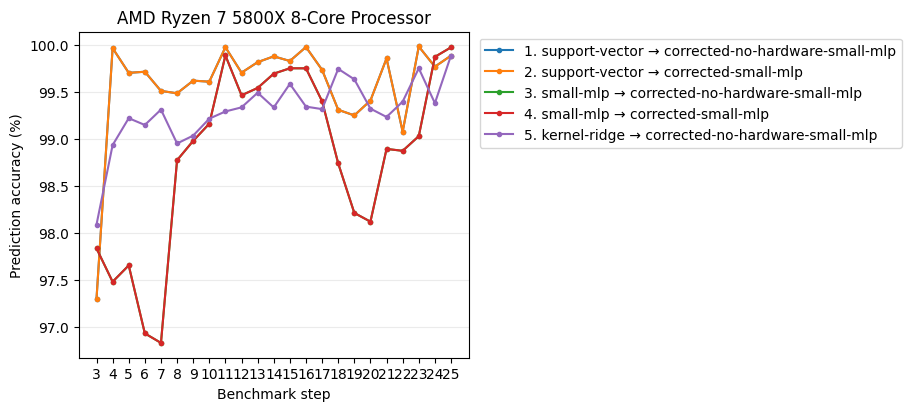

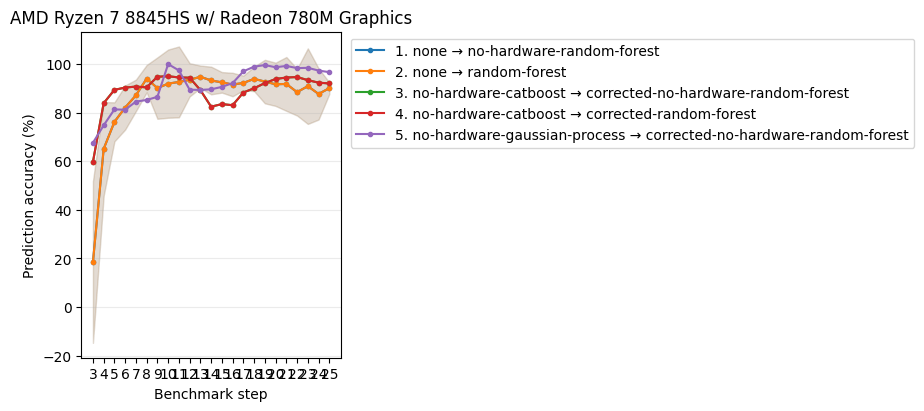

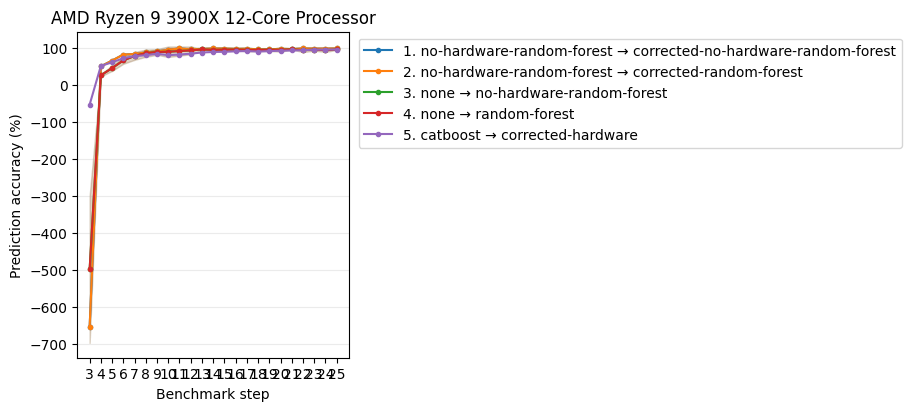

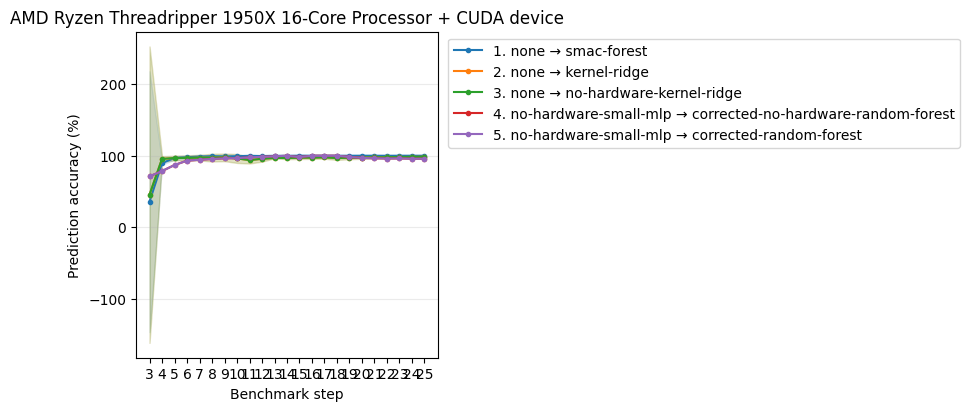

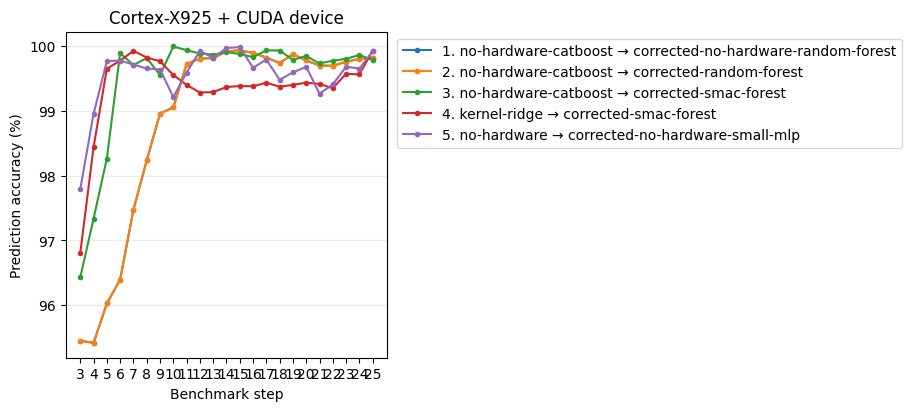

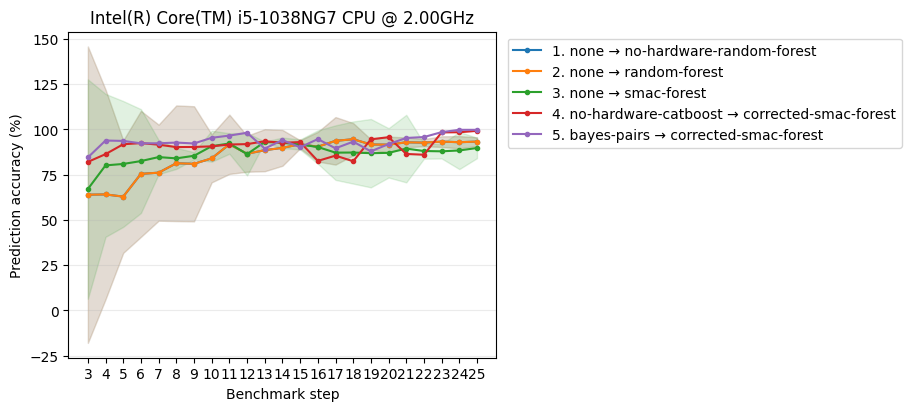

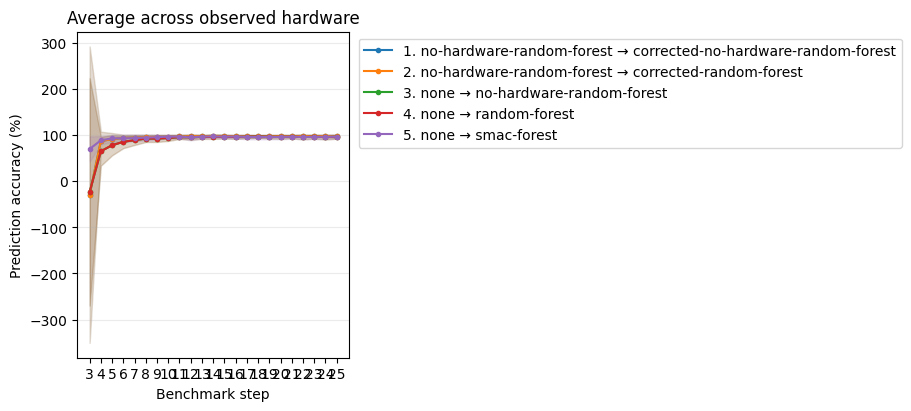

In [48]:
plot_progress(improvement_top)

### Cross-hardware breakdown

**Average across observed hardware**

,Application,Workload,Historical,Local,Mean (pp),95% CI lower,95% CI upper,Platforms
Average rank,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-random-forest,corrected-no-hardware-random-forest,126.40455284,-196.38464877,449.19375445,6
2,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-random-forest,corrected-random-forest,126.40455284,-196.38464877,449.19375445,6
3,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-random-forest,119.49749011,-126.78486362,365.77984383,6
4,llama.cpp,"[[0, 128], [512, 0]]",none,random-forest,119.49749011,-126.78486362,365.77984383,6
5,llama.cpp,"[[0, 128], [512, 0]]",none,smac-forest,26.62800306,-0.62597626,53.88198237,6


**AMD Ryzen 7 5800X 8-Core Processor**

,Application,Workload,Historical,Local,Mean (pp),95% CI lower,95% CI upper,Seeds,Difference from average (pp)
Average rank,,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-random-forest,corrected-no-hardware-random-forest,-0.14603824,—,—,1,-126.55059108
2,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-random-forest,corrected-random-forest,-0.14603824,—,—,1,-126.55059108
3,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-random-forest,0.02451746,-0.77849545,0.82753037,3,-119.47297264
4,llama.cpp,"[[0, 128], [512, 0]]",none,random-forest,0.02451746,-0.77849545,0.82753037,3,-119.47297264
5,llama.cpp,"[[0, 128], [512, 0]]",none,smac-forest,-0.21132445,-1.08613340,0.66348449,3,-26.83932751


**AMD Ryzen 7 8845HS w/ Radeon 780M Graphics**

,Application,Workload,Historical,Local,Mean (pp),95% CI lower,95% CI upper,Seeds,Difference from average (pp)
Average rank,,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-random-forest,corrected-no-hardware-random-forest,6.70610139,—,—,1,-119.69845145
2,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-random-forest,corrected-random-forest,6.70610139,—,—,1,-119.69845145
3,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-random-forest,71.59662507,36.72149507,106.47175507,3,-47.90086503
4,llama.cpp,"[[0, 128], [512, 0]]",none,random-forest,71.59662507,36.72149507,106.47175507,3,-47.90086503
5,llama.cpp,"[[0, 128], [512, 0]]",none,smac-forest,21.92170341,-65.91596350,109.75937031,3,-4.70629965


... (4 outputs left out)

**Cortex-X925 + CUDA device**

,Application,Workload,Historical,Local,Mean (pp),95% CI lower,95% CI upper,Seeds,Difference from average (pp)
Average rank,,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-random-forest,corrected-no-hardware-random-forest,-0.10683035,—,—,1,-126.51138319
2,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-random-forest,corrected-random-forest,-0.10683035,—,—,1,-126.51138319
3,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-random-forest,1.57786218,-3.37499953,6.53072390,3,-117.91962792
4,llama.cpp,"[[0, 128], [512, 0]]",none,random-forest,1.57786218,-3.37499953,6.53072390,3,-117.91962792
5,llama.cpp,"[[0, 128], [512, 0]]",none,smac-forest,1.10200603,-2.07782580,4.28183786,3,-25.52599703


**Intel(R) Core(TM) i5-1038NG7 CPU @ 2.00GHz**

,Application,Workload,Historical,Local,Mean (pp),95% CI lower,95% CI upper,Seeds,Difference from average (pp)
Average rank,,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-random-forest,corrected-no-hardware-random-forest,-3.12681356,—,—,1,-129.53136640
2,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-random-forest,corrected-random-forest,-3.12681356,—,—,1,-129.53136640
3,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-random-forest,29.32075909,-52.97985202,111.62137020,3,-90.17673102
4,llama.cpp,"[[0, 128], [512, 0]]",none,random-forest,29.32075909,-52.97985202,111.62137020,3,-90.17673102
5,llama.cpp,"[[0, 128], [512, 0]]",none,smac-forest,22.66769711,-37.71140420,83.04679843,3,-3.96030594


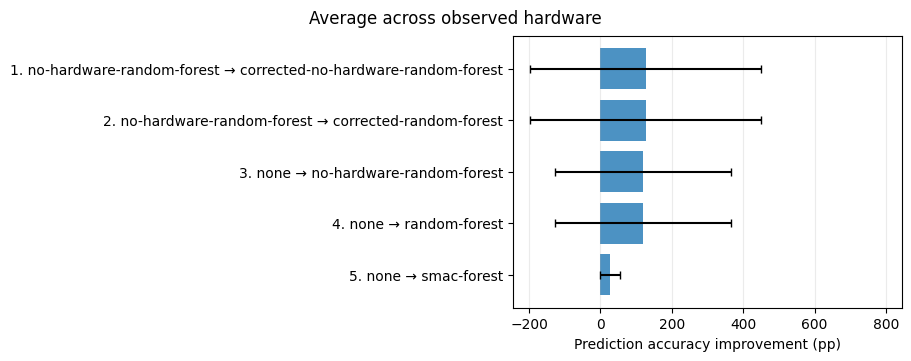

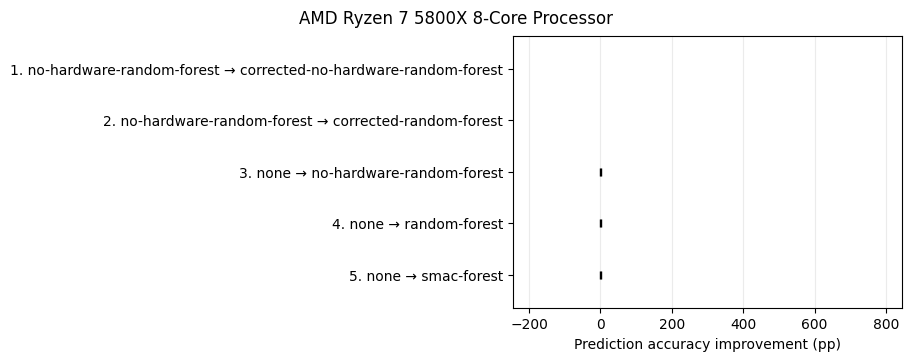

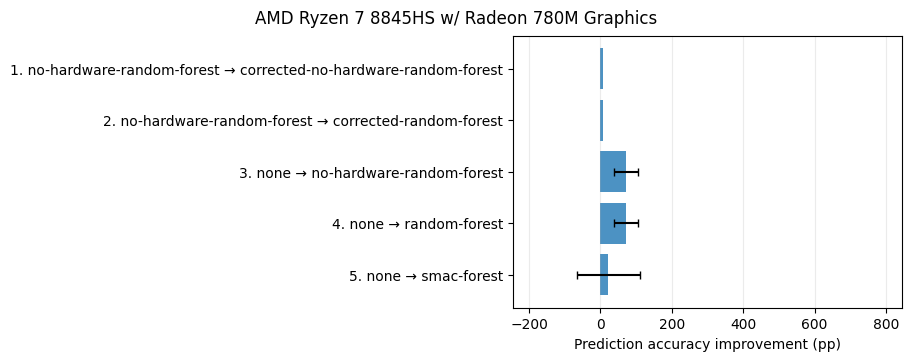

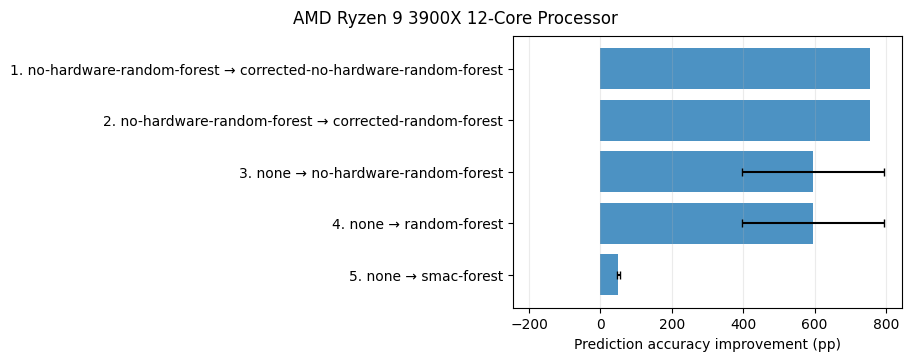

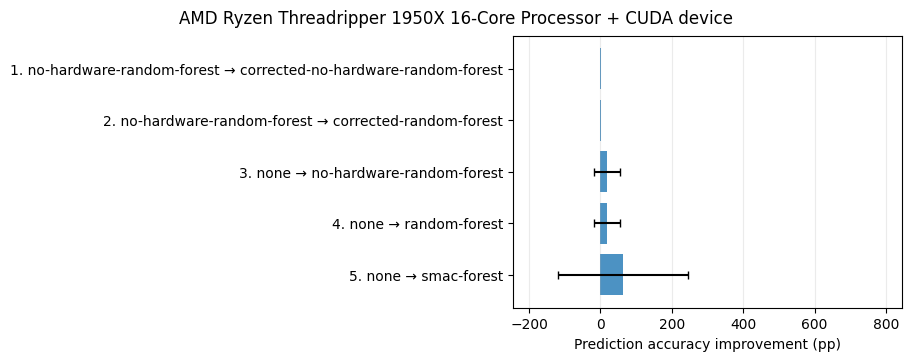

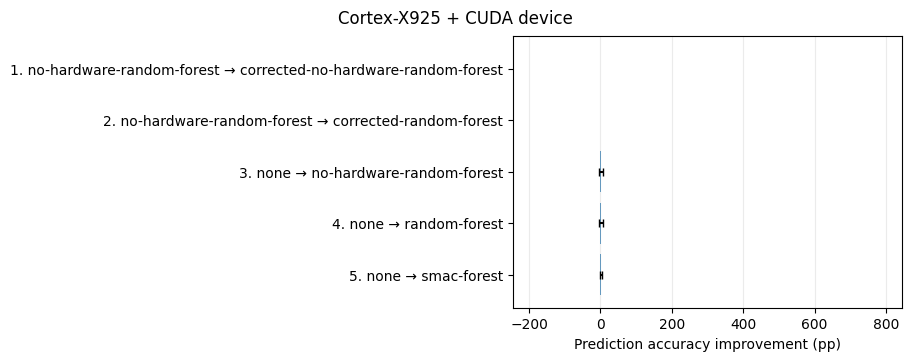

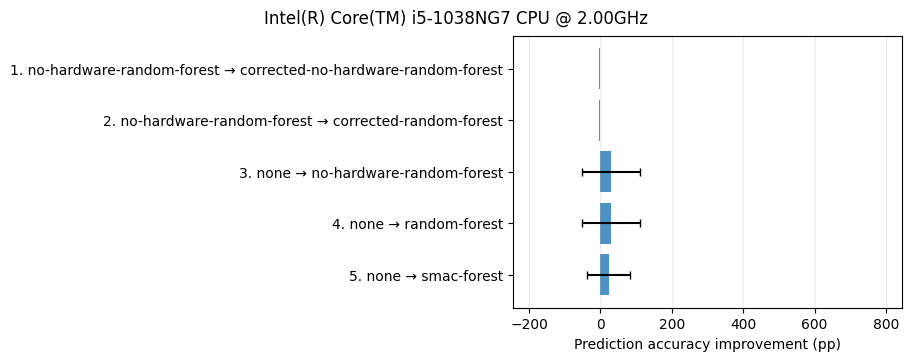

In [49]:
compare_hardware(improvement_top, "improvement", "pp", "Prediction accuracy improvement (pp)")

## 3. Final recommendation quality

In [50]:
pool_final_top = rankings("pool_share", "%", companions={"accuracy": "Final prediction accuracy (%)"})

#### AMD Ryzen 7 5800X 8-Core Processor

Eligible combinations: 420/420 ready · Range: 95.922914 to 99.675133 %
Tie-breaker: final prediction accuracy → historical → local → application → workload (alphabetical); 14 tied at table cutoff


,Application,Workload,Historical,Local,Mean (%),95% CI lower,95% CI upper,Seeds,Final prediction accuracy (%)
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-support-vector,99.67513339,98.97623001,100.37403678,3,"98.0216 [97.9438, 98.0995]"
2,llama.cpp,"[[0, 128], [512, 0]]",none,support-vector,99.67513339,98.97623001,100.37403678,3,"98.0216 [97.9438, 98.0995]"
3,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-bayes-pairs,99.66083046,—,—,1,100
4,llama.cpp,"[[0, 128], [512, 0]]",hardware-three-way,corrected-bayes-pairs,99.66083046,—,—,1,100
5,llama.cpp,"[[0, 128], [512, 0]]",gaussian-process,corrected-sparse-bayes,99.66083046,—,—,1,99.9642
6,llama.cpp,"[[0, 128], [512, 0]]",hardware-three-way,corrected-no-hardware-small-mlp,99.66083046,—,—,1,99.9317
7,llama.cpp,"[[0, 128], [512, 0]]",hardware-three-way,corrected-small-mlp,99.66083046,—,—,1,99.9317
8,llama.cpp,"[[0, 128], [512, 0]]",hardware-three-way,corrected-hardware,99.66083046,—,—,1,99.9277
9,llama.cpp,"[[0, 128], [512, 0]]",hardware-three-way,corrected-no-hardware,99.66083046,—,—,1,99.9277
10,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-gaussian-process,99.66083046,—,—,1,99.8261


#### AMD Ryzen 7 8845HS w/ Radeon 780M Graphics

Eligible combinations: 420/420 ready · Range: 69.352566 to 100 %
Tie-breaker: final prediction accuracy → historical → local → application → workload (alphabetical); 248 tied at table cutoff


,Application,Workload,Historical,Local,Mean (%),95% CI lower,95% CI upper,Seeds,Final prediction accuracy (%)
1,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-random-forest,corrected-bayes-pairs,100.00000000,—,—,1,100
2,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-random-forest,corrected-gaussian-process,100.00000000,—,—,1,100
3,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-random-forest,corrected-no-hardware-gaussian-process,100.00000000,—,—,1,100
4,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-bayes-pairs,100.00000000,—,—,1,100
5,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-support-vector,corrected-gaussian-process,100.00000000,—,—,1,100
6,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-support-vector,corrected-no-hardware-gaussian-process,100.00000000,—,—,1,100
7,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-support-vector,corrected-bayes-pairs,100.00000000,—,—,1,100
8,llama.cpp,"[[0, 128], [512, 0]]",support-vector,corrected-bayes-pairs,100.00000000,—,—,1,100
9,llama.cpp,"[[0, 128], [512, 0]]",kernel-ridge,corrected-gaussian-process,100.00000000,—,—,1,100
10,llama.cpp,"[[0, 128], [512, 0]]",kernel-ridge,corrected-no-hardware-gaussian-process,100.00000000,—,—,1,100


... (11 outputs left out)

,Application,Workload,Historical,Local,Mean (%),95% CI lower,95% CI upper,Seeds,Final prediction accuracy (%)
1,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-gaussian-process,100.00000000,—,—,1,100
2,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-no-hardware-gaussian-process,100.00000000,—,—,1,100
3,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-interactions,corrected-gaussian-process,100.00000000,—,—,1,100
4,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-interactions,corrected-no-hardware-gaussian-process,100.00000000,—,—,1,100
5,llama.cpp,"[[0, 128], [512, 0]]",sparse-bayes,corrected-gaussian-process,100.00000000,—,—,1,100
6,llama.cpp,"[[0, 128], [512, 0]]",sparse-bayes,corrected-no-hardware-gaussian-process,100.00000000,—,—,1,100
7,llama.cpp,"[[0, 128], [512, 0]]",bayes-pairs,corrected-gaussian-process,100.00000000,—,—,1,100
8,llama.cpp,"[[0, 128], [512, 0]]",bayes-pairs,corrected-no-hardware-gaussian-process,100.00000000,—,—,1,100
9,llama.cpp,"[[0, 128], [512, 0]]",gaussian-process,corrected-gaussian-process,100.00000000,—,—,1,100
10,llama.cpp,"[[0, 128], [512, 0]]",gaussian-process,corrected-no-hardware-gaussian-process,100.00000000,—,—,1,100


#### Average across observed hardware

Eligible combinations: 380/380 ready · Range: 88.789149 to 99.919449 %
Range of all eligible per-hardware means: 69.352566 to 100 %
Tie-breaker: final prediction accuracy → historical → local → application → workload (alphabetical); 6 tied at table cutoff


,Application,Workload,Historical,Local,Mean (%),95% CI lower,95% CI upper,Platforms,Final prediction accuracy (%)
1,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-gaussian-process,99.91944933,99.71238723,100.12651142,6,"99.9624 [99.9132, 100.012]"
2,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-gaussian-process,99.91944933,99.71238723,100.12651142,6,"99.9624 [99.9132, 100.012]"
3,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-bayes-pairs,99.88735227,99.68035329,100.09435126,6,"98.7885 [95.6742, 101.903]"
4,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-bayes-pairs,99.87679229,99.72102071,100.03256387,6,"100 [99.9999, 100]"
5,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-gaussian-process,99.87679229,99.72102071,100.03256387,6,"99.9591 [99.8845, 100.034]"
6,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-no-hardware-gaussian-process,99.87679229,99.72102071,100.03256387,6,"99.9591 [99.8845, 100.034]"
7,llama.cpp,"[[0, 128], [512, 0]]",gaussian-process,corrected-sparse-bayes,99.85049362,99.70704574,99.99394150,6,"99.7899 [99.5409, 100.039]"
8,llama.cpp,"[[0, 128], [512, 0]]",support-vector,corrected-bayes-pairs,99.82199390,99.36441465,100.27957315,6,"100 [99.9999, 100]"
9,llama.cpp,"[[0, 128], [512, 0]]",support-vector,corrected-hardware-interactions,99.82199390,99.36441465,100.27957315,6,"99.9922 [99.9806, 100.004]"
10,llama.cpp,"[[0, 128], [512, 0]]",support-vector,corrected-hardware-three-way,99.82199390,99.36441465,100.27957315,6,"99.9922 [99.9806, 100.004]"


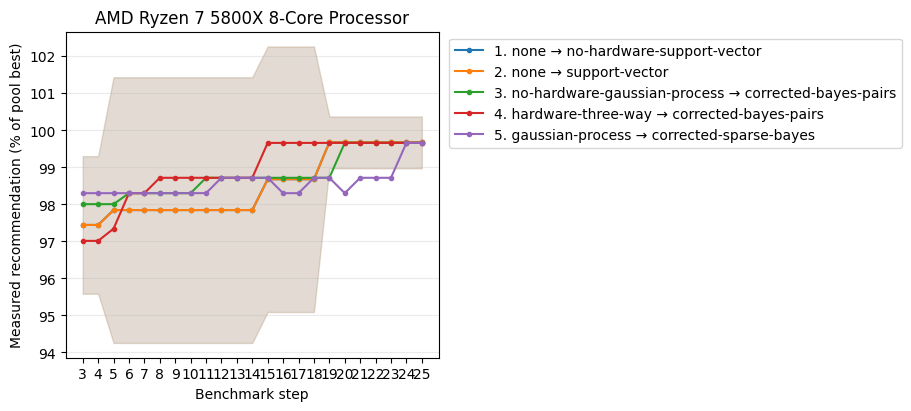

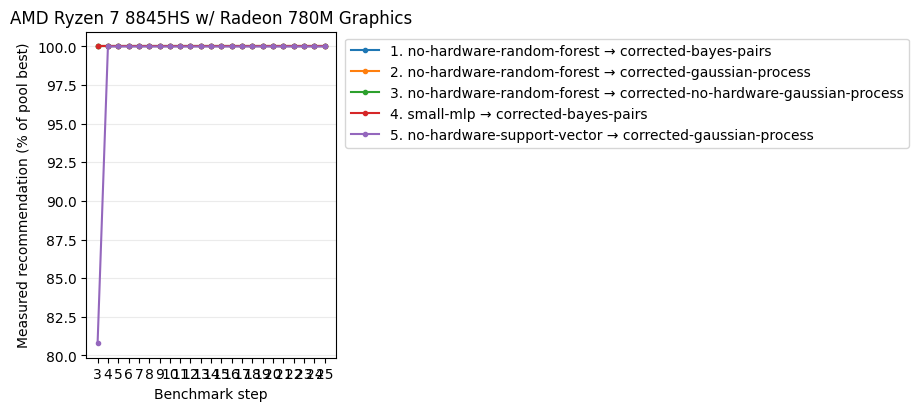

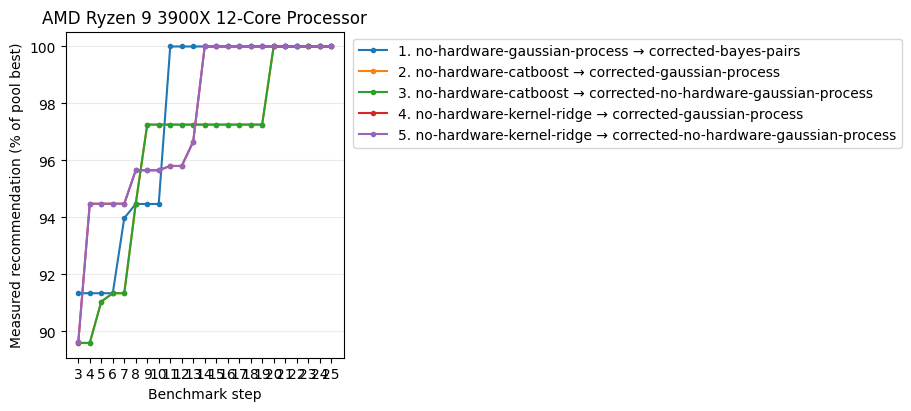

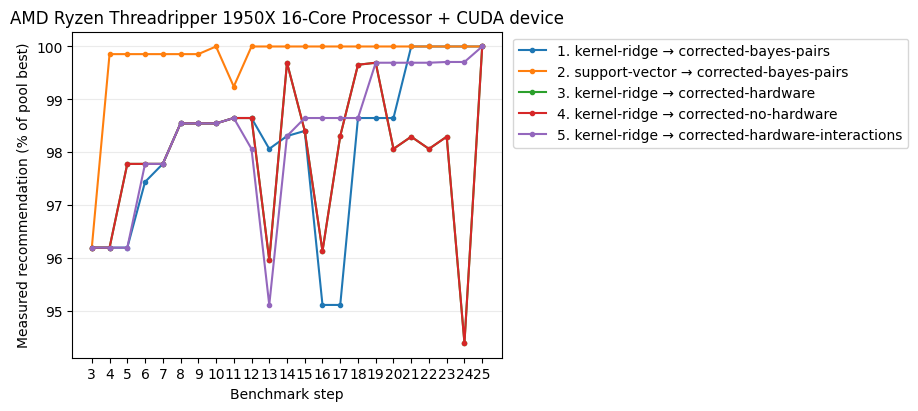

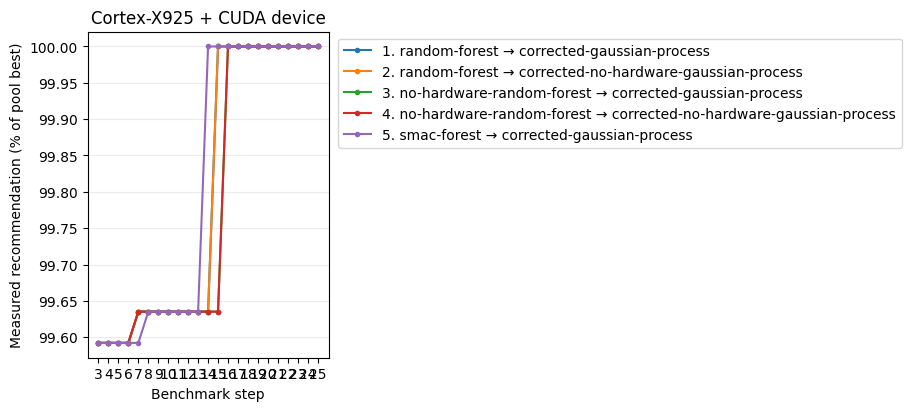

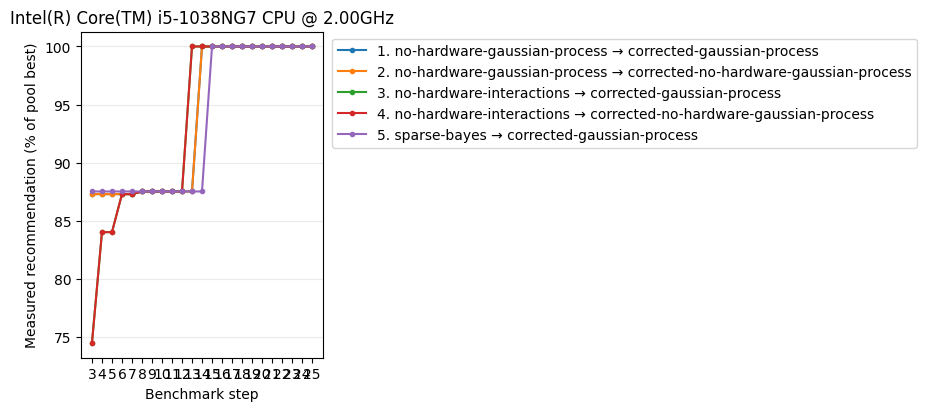

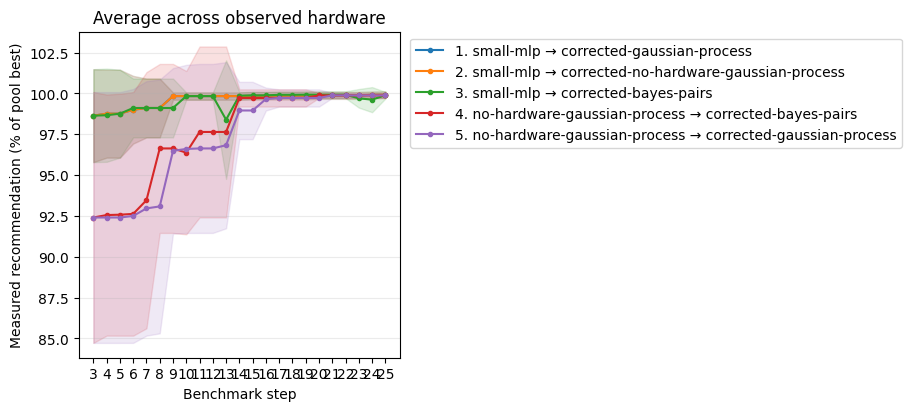

In [51]:
plot_progress(pool_final_top, "pool_share", "Measured recommendation (% of pool best)")

### Cross-hardware breakdown

**Average across observed hardware**

,Application,Workload,Historical,Local,Mean (%),95% CI lower,95% CI upper,Platforms
Average rank,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-gaussian-process,99.91944933,99.71238723,100.12651142,6
2,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-gaussian-process,99.91944933,99.71238723,100.12651142,6
3,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-bayes-pairs,99.88735227,99.68035329,100.09435126,6
4,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-bayes-pairs,99.87679229,99.72102071,100.03256387,6
5,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-gaussian-process,99.87679229,99.72102071,100.03256387,6


**AMD Ryzen 7 5800X 8-Core Processor**

,Application,Workload,Historical,Local,Mean (%),95% CI lower,95% CI upper,Seeds,Difference from average (%)
Average rank,,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-gaussian-process,99.51669596,—,—,1,-0.40275337
2,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-gaussian-process,99.51669596,—,—,1,-0.40275337
3,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-bayes-pairs,99.51669596,—,—,1,-0.37065632
4,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-bayes-pairs,99.66083046,—,—,1,-0.21596183
5,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-gaussian-process,99.66083046,—,—,1,-0.21596183


**AMD Ryzen 7 8845HS w/ Radeon 780M Graphics**

,Application,Workload,Historical,Local,Mean (%),95% CI lower,95% CI upper,Seeds,Difference from average (%)
Average rank,,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-gaussian-process,100.00000000,—,—,1,0.08055067
2,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-gaussian-process,100.00000000,—,—,1,0.08055067
3,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-bayes-pairs,100.00000000,—,—,1,0.11264773
4,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-bayes-pairs,100.00000000,—,—,1,0.12320771
5,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-gaussian-process,100.00000000,—,—,1,0.12320771


... (4 outputs left out)

**Cortex-X925 + CUDA device**

,Application,Workload,Historical,Local,Mean (%),95% CI lower,95% CI upper,Seeds,Difference from average (%)
Average rank,,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-gaussian-process,100.00000000,—,—,1,0.08055067
2,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-gaussian-process,100.00000000,—,—,1,0.08055067
3,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-bayes-pairs,100.00000000,—,—,1,0.11264773
4,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-bayes-pairs,99.74438766,—,—,1,-0.13240463
5,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-gaussian-process,99.74438766,—,—,1,-0.13240463


**Intel(R) Core(TM) i5-1038NG7 CPU @ 2.00GHz**

,Application,Workload,Historical,Local,Mean (%),95% CI lower,95% CI upper,Seeds,Difference from average (%)
Average rank,,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-gaussian-process,100.00000000,—,—,1,0.08055067
2,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-gaussian-process,100.00000000,—,—,1,0.08055067
3,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-bayes-pairs,100.00000000,—,—,1,0.11264773
4,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-bayes-pairs,100.00000000,—,—,1,0.12320771
5,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-gaussian-process,100.00000000,—,—,1,0.12320771


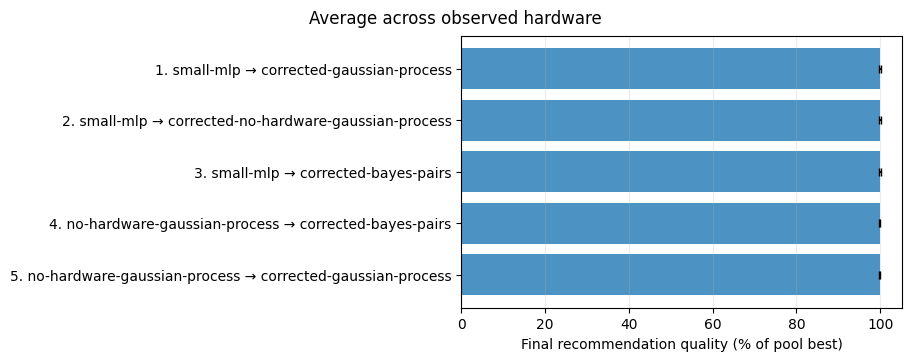

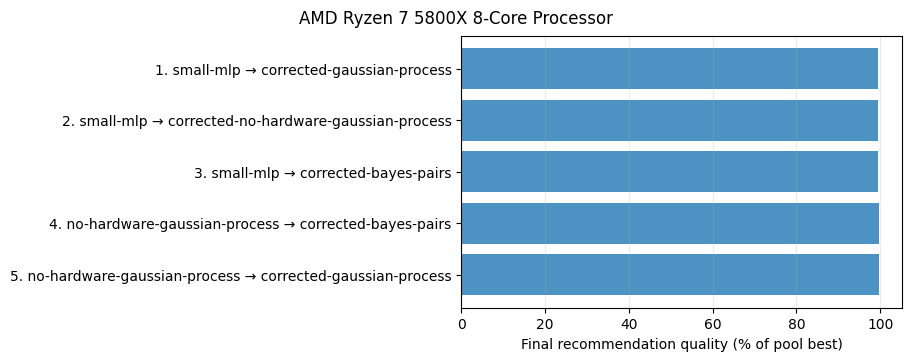

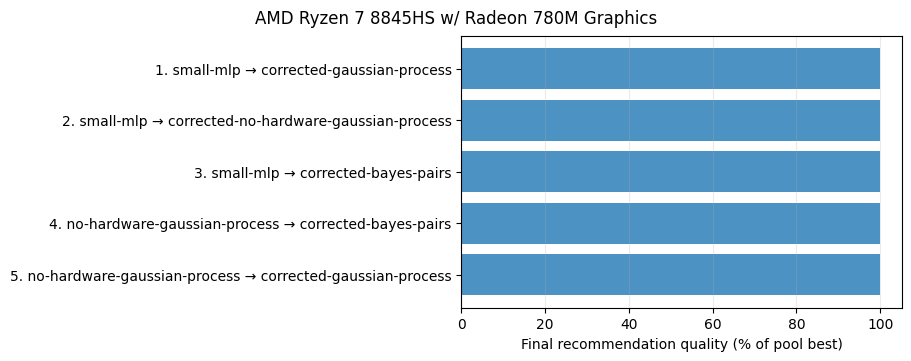

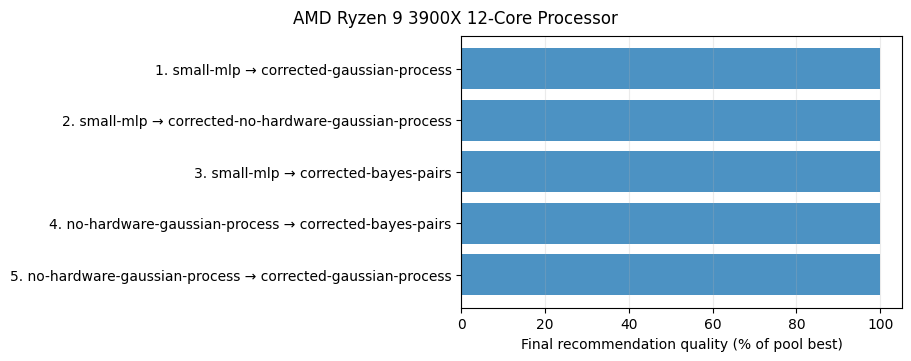

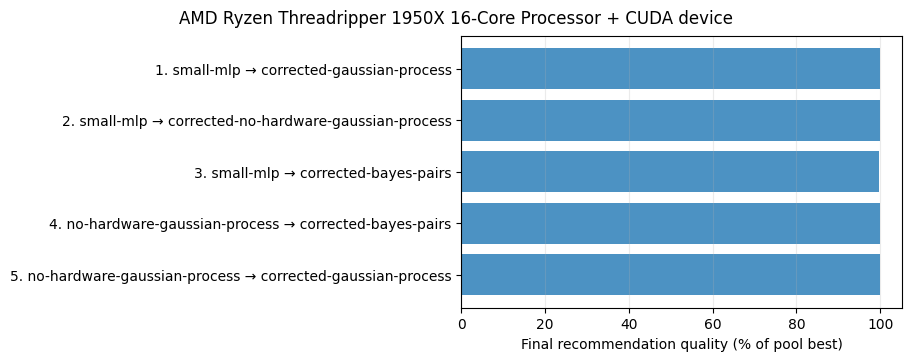

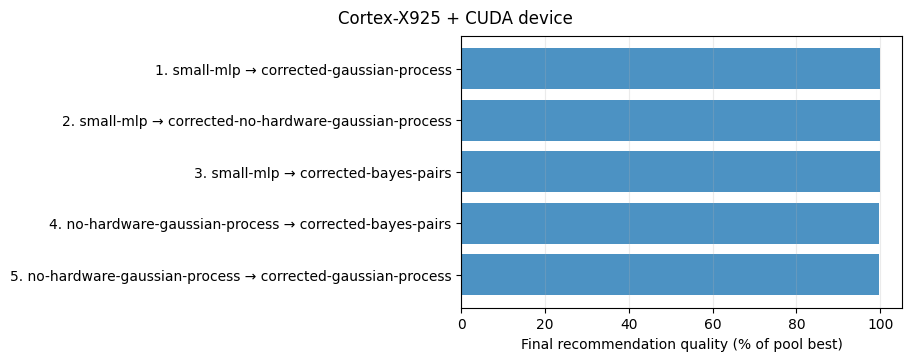

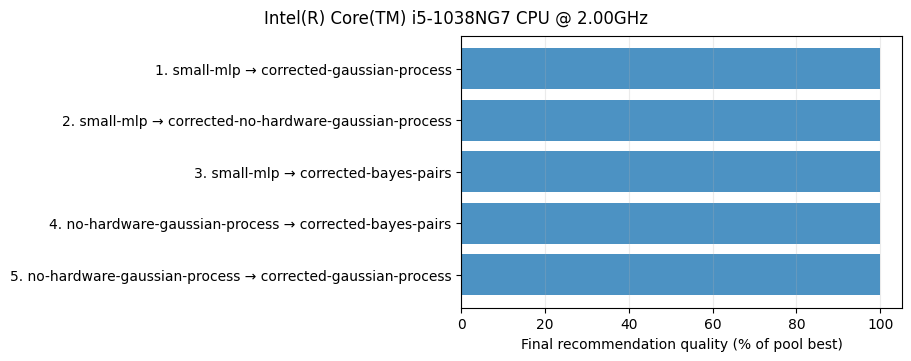

In [52]:
compare_hardware(pool_final_top, "pool_share", "%", "Final recommendation quality (% of pool best)")

## 4. First-to-last recommendation quality improvement

In [53]:
pool_gain_top = rankings("pool_improvement", "pp", companions={
    "pool_share": "Final % of pool best", "accuracy": "Final prediction accuracy (%)",
    "improvement": "Prediction accuracy gain (pp)",
})

#### AMD Ryzen 7 5800X 8-Core Processor

Eligible combinations: 420/420 ready · Range: -1.5014935 to 3.0470124 pp
Tie-breaker: final recommendation quality → final prediction accuracy → historical → local → application → workload (alphabetical); 2 tied at table cutoff


,Application,Workload,Historical,Local,Mean (pp),95% CI lower,95% CI upper,Seeds,Final % of pool best,Final prediction accuracy (%),Prediction accuracy gain (pp)
1,llama.cpp,"[[0, 128], [512, 0]]",hardware-three-way,corrected-no-hardware-small-mlp,3.04701242,—,—,1,99.6608,99.9317,0.683154
2,llama.cpp,"[[0, 128], [512, 0]]",hardware-three-way,corrected-small-mlp,3.04701242,—,—,1,99.6608,99.9317,0.683154
3,llama.cpp,"[[0, 128], [512, 0]]",hardware-three-way,corrected-hardware,3.04701242,—,—,1,99.6608,99.9277,-0.071047
4,llama.cpp,"[[0, 128], [512, 0]]",hardware-three-way,corrected-no-hardware,3.04701242,—,—,1,99.6608,99.9277,-0.071047
5,llama.cpp,"[[0, 128], [512, 0]]",hardware-three-way,corrected-gaussian-process,3.04701242,—,—,1,99.6608,99.8042,-0.0771086
6,llama.cpp,"[[0, 128], [512, 0]]",hardware-three-way,corrected-no-hardware-gaussian-process,3.04701242,—,—,1,99.6608,99.8042,-0.0771086
7,llama.cpp,"[[0, 128], [512, 0]]",hardware-three-way,corrected-bayes-pairs,2.64650326,—,—,1,99.6608,100,-9.9641e-06
8,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-random-forest,2.36251559,1.46868303,3.25634815,3,"99.3753 [98.4814, 100.269]","99.5912 [98.8463, 100.336]","0.0245175 [-0.778495, 0.82753]"
9,llama.cpp,"[[0, 128], [512, 0]]",none,random-forest,2.36251559,1.46868303,3.25634815,3,"99.3753 [98.4814, 100.269]","99.5912 [98.8463, 100.336]","0.0245175 [-0.778495, 0.82753]"
10,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-support-vector,2.23042674,-0.05647042,4.51732390,3,"99.6751 [98.9762, 100.374]","98.0216 [97.9438, 98.0995]","-1.11125 [-3.58516, 1.36265]"


#### AMD Ryzen 7 8845HS w/ Radeon 780M Graphics

Eligible combinations: 420/420 ready · Range: -18.965456 to 70.675777 pp
Tie-breaker: final recommendation quality → final prediction accuracy → historical → local → application → workload (alphabetical); no tie at table cutoff


,Application,Workload,Historical,Local,Mean (pp),95% CI lower,95% CI upper,Seeds,Final % of pool best,Final prediction accuracy (%),Prediction accuracy gain (pp)
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-random-forest,70.67577654,56.94504609,84.40650698,3,"96.8088 [83.078, 110.54]","90.0724 [87.6869, 92.4578]","71.5966 [36.7215, 106.472]"
2,llama.cpp,"[[0, 128], [512, 0]]",none,random-forest,70.67577654,56.94504609,84.40650698,3,"96.8088 [83.078, 110.54]","90.0724 [87.6869, 92.4578]","71.5966 [36.7215, 106.472]"
3,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-kernel-ridge,corrected-no-hardware-random-forest,51.79550061,—,—,1,100,94.496,7.00531
4,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-kernel-ridge,corrected-random-forest,51.79550061,—,—,1,100,94.496,7.00531
5,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-catboost,corrected-no-hardware-random-forest,51.79550061,—,—,1,100,92.021,32.317
6,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-catboost,corrected-random-forest,51.79550061,—,—,1,100,92.021,32.317
7,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-no-hardware-random-forest,51.61715754,—,—,1,99.8217,96.6667,29.0837
8,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-random-forest,51.61715754,—,—,1,99.8217,96.6667,29.0837
9,llama.cpp,"[[0, 128], [512, 0]]",sparse-bayes,corrected-no-hardware-random-forest,51.61715754,—,—,1,99.8217,90.6023,10.0817
10,llama.cpp,"[[0, 128], [512, 0]]",sparse-bayes,corrected-random-forest,51.61715754,—,—,1,99.8217,90.6023,10.0817


... (11 outputs left out)

,Application,Workload,Historical,Local,Mean (pp),95% CI lower,95% CI upper,Seeds,Final % of pool best,Final prediction accuracy (%),Prediction accuracy gain (pp)
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-random-forest,33.29009202,27.92458491,38.65559912,3,"88.757 [83.3915, 94.1225]","93.273 [90.894, 95.6519]","29.3208 [-52.9799, 111.621]"
2,llama.cpp,"[[0, 128], [512, 0]]",none,random-forest,33.29009202,27.92458491,38.65559912,3,"88.757 [83.3915, 94.1225]","93.273 [90.894, 95.6519]","29.3208 [-52.9799, 111.621]"
3,llama.cpp,"[[0, 128], [512, 0]]",none,smac-forest,32.02270518,14.84821389,49.19719647,3,"89.4923 [78.6827, 100.302]","89.7389 [84.1315, 95.3463]","22.6677 [-37.7114, 83.0468]"
4,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-support-vector,31.96709044,12.29460865,51.63957224,3,"95.2521 [84.2672, 106.237]","98.0155 [97.9434, 98.0877]","-0.0109163 [-0.0915021, 0.0696695]"
5,llama.cpp,"[[0, 128], [512, 0]]",none,support-vector,31.96709044,12.29460865,51.63957224,3,"95.2521 [84.2672, 106.237]","98.0155 [97.9434, 98.0877]","-0.0109163 [-0.0915021, 0.0696695]"
6,llama.cpp,"[[0, 128], [512, 0]]",none,gaussian-process,30.72006740,-4.56769968,66.00783447,3,"94.0051 [78.4544, 109.556]","99.9397 [99.6804, 100.199]","0.142816 [-0.723877, 1.00951]"
7,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-gaussian-process,30.72006740,-4.56769968,66.00783447,3,"94.0051 [78.4544, 109.556]","99.9397 [99.6804, 100.199]","0.142816 [-0.723877, 1.00951]"
8,llama.cpp,"[[0, 128], [512, 0]]",none,bayes-pairs,27.42453770,-15.29766480,70.14674021,3,"94.1674 [81.6195, 106.715]","99.9999 [99.9997, 100]","-3.32922e-05 [-0.000103623, 3.70385e-05]"
9,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-small-mlp,27.42453770,-1.31674069,56.16581609,3,"94.1674 [81.6195, 106.715]","99.8277 [99.6403, 100.015]","0.169324 [-0.705367, 1.04401]"
10,llama.cpp,"[[0, 128], [512, 0]]",none,small-mlp,27.42453770,-1.31674069,56.16581609,3,"94.1674 [81.6195, 106.715]","99.8277 [99.6403, 100.015]","0.169324 [-0.705367, 1.04401]"


#### Average across observed hardware

Eligible combinations: 380/380 ready · Range: -3.1609093 to 34.472492 pp
Range of all eligible per-hardware means: -18.965456 to 91.132403 pp
Tie-breaker: final recommendation quality → final prediction accuracy → historical → local → application → workload (alphabetical); 2 tied at table cutoff


,Application,Workload,Historical,Local,Mean (pp),95% CI lower,95% CI upper,Platforms,Final % of pool best,Final prediction accuracy (%),Prediction accuracy gain (pp)
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-random-forest,34.47249182,-4.97079665,73.91578030,6,"96.318 [91.876, 100.76]","96.5773 [92.2763, 100.878]","119.497 [-126.785, 365.78]"
2,llama.cpp,"[[0, 128], [512, 0]]",none,random-forest,34.47249182,-4.97079665,73.91578030,6,"96.318 [91.876, 100.76]","96.5773 [92.2763, 100.878]","119.497 [-126.785, 365.78]"
3,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-random-forest,corrected-no-hardware-random-forest,21.92972022,-15.89495331,59.75439375,6,"97.3861 [93.754, 101.018]","97.296 [93.3559, 101.236]","126.405 [-196.385, 449.194]"
4,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-random-forest,corrected-random-forest,21.92972022,-15.89495331,59.75439375,6,"97.3861 [93.754, 101.018]","97.296 [93.3559, 101.236]","126.405 [-196.385, 449.194]"
5,llama.cpp,"[[0, 128], [512, 0]]",none,smac-forest,20.16938148,1.56617700,38.77258596,6,"96.5515 [92.3263, 100.777]","96.6878 [92.2953, 101.08]","26.628 [-0.625976, 53.882]"
6,llama.cpp,"[[0, 128], [512, 0]]",sparse-bayes,corrected-no-hardware-random-forest,12.63214805,-8.10215722,33.36645333,6,"97.9824 [95.3683, 100.597]","92.4218 [86.6322, 98.2113]","-1.53941 [-9.38261, 6.3038]"
7,llama.cpp,"[[0, 128], [512, 0]]",sparse-bayes,corrected-random-forest,12.63214805,-8.10215722,33.36645333,6,"97.9824 [95.3683, 100.597]","92.4218 [86.6322, 98.2113]","-1.53941 [-9.38261, 6.3038]"
8,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-catboost,corrected-no-hardware-random-forest,12.40762890,-8.49960713,33.31486494,6,"98.9823 [97.4766, 100.488]","94.9266 [89.6117, 100.241]","10.0869 [-5.15121, 25.325]"
9,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-catboost,corrected-random-forest,12.40762890,-8.49960713,33.31486494,6,"98.9823 [97.4766, 100.488]","94.9266 [89.6117, 100.241]","10.0869 [-5.15121, 25.325]"
10,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-support-vector,12.36692488,-2.91156446,27.64541421,6,"98.258 [96.2093, 100.307]","98.1493 [97.8132, 98.4853]","-0.205809 [-0.912195, 0.500577]"


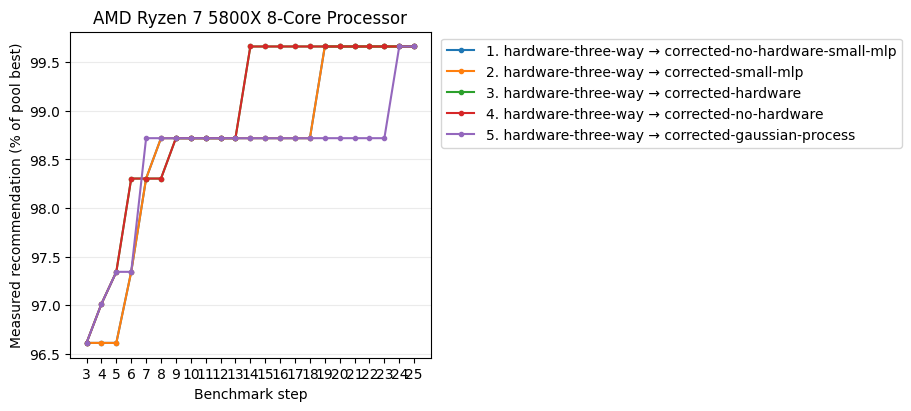

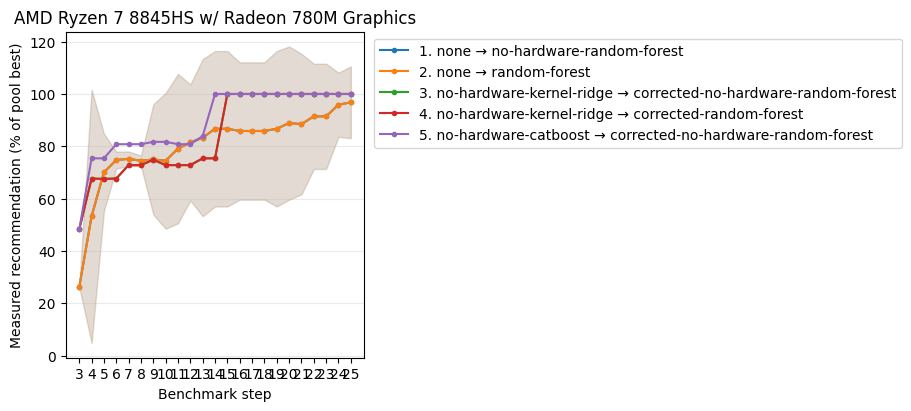

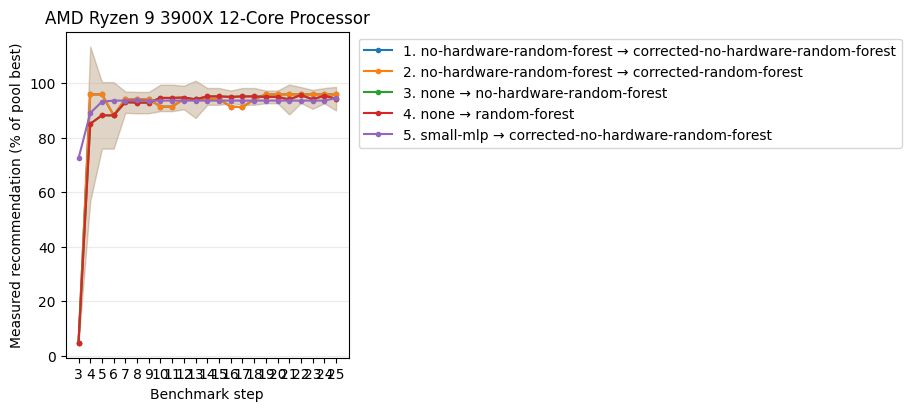

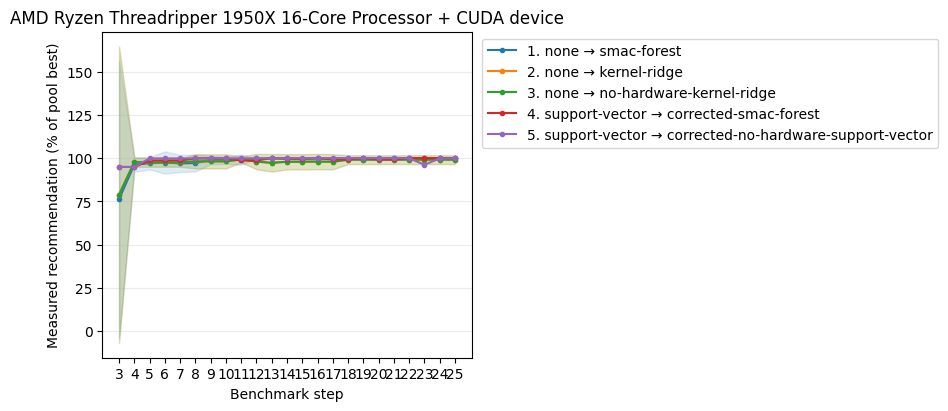

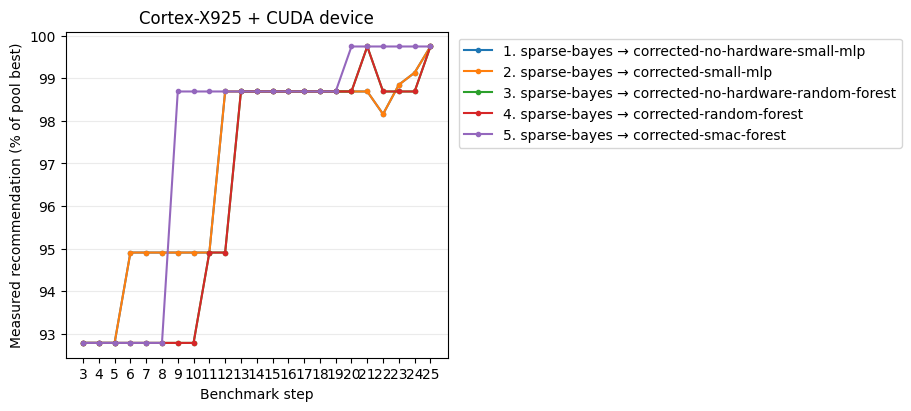

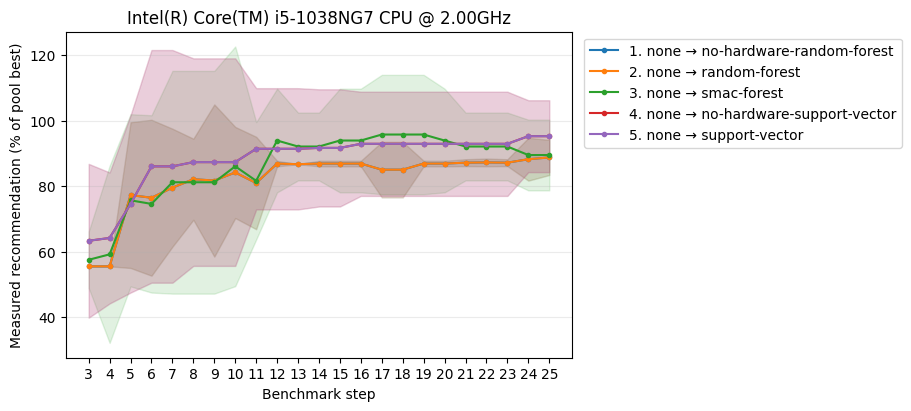

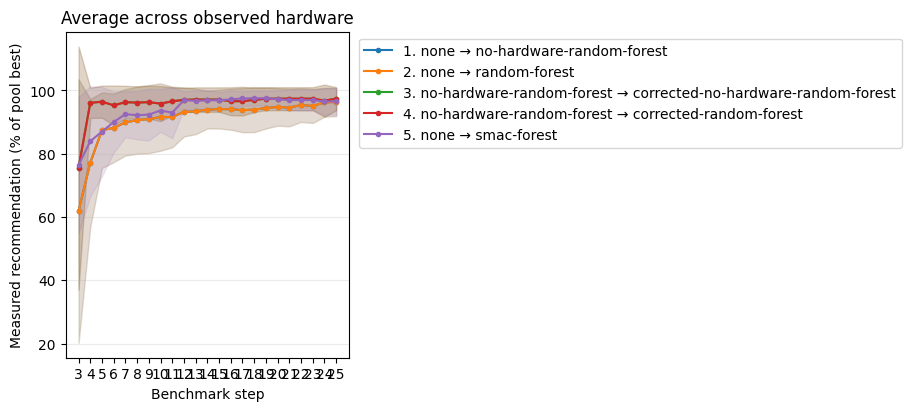

In [54]:
plot_progress(pool_gain_top, "pool_share", "Measured recommendation (% of pool best)")

### Cross-hardware breakdown

**Average across observed hardware**

,Application,Workload,Historical,Local,Mean (pp),95% CI lower,95% CI upper,Platforms
Average rank,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-random-forest,34.47249182,-4.97079665,73.91578030,6
2,llama.cpp,"[[0, 128], [512, 0]]",none,random-forest,34.47249182,-4.97079665,73.91578030,6
3,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-random-forest,corrected-no-hardware-random-forest,21.92972022,-15.89495331,59.75439375,6
4,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-random-forest,corrected-random-forest,21.92972022,-15.89495331,59.75439375,6
5,llama.cpp,"[[0, 128], [512, 0]]",none,smac-forest,20.16938148,1.56617700,38.77258596,6


**AMD Ryzen 7 5800X 8-Core Processor**

,Application,Workload,Historical,Local,Mean (pp),95% CI lower,95% CI upper,Seeds,Difference from average (pp)
Average rank,,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-random-forest,2.36251559,1.46868303,3.25634815,3,-32.10997624
2,llama.cpp,"[[0, 128], [512, 0]]",none,random-forest,2.36251559,1.46868303,3.25634815,3,-32.10997624
3,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-random-forest,corrected-no-hardware-random-forest,0.88699102,—,—,1,-21.04272920
4,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-random-forest,corrected-random-forest,0.88699102,—,—,1,-21.04272920
5,llama.cpp,"[[0, 128], [512, 0]]",none,smac-forest,1.83951770,0.17438021,3.50465518,3,-18.32986378


**AMD Ryzen 7 8845HS w/ Radeon 780M Graphics**

,Application,Workload,Historical,Local,Mean (pp),95% CI lower,95% CI upper,Seeds,Difference from average (pp)
Average rank,,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-random-forest,70.67577654,56.94504609,84.40650698,3,36.20328471
2,llama.cpp,"[[0, 128], [512, 0]]",none,random-forest,70.67577654,56.94504609,84.40650698,3,36.20328471
3,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-random-forest,corrected-no-hardware-random-forest,32.46316980,—,—,1,10.53344958
4,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-random-forest,corrected-random-forest,32.46316980,—,—,1,10.53344958
5,llama.cpp,"[[0, 128], [512, 0]]",none,smac-forest,47.57393272,-12.77103012,107.91889557,3,27.40455124


... (4 outputs left out)

**Cortex-X925 + CUDA device**

,Application,Workload,Historical,Local,Mean (pp),95% CI lower,95% CI upper,Seeds,Difference from average (pp)
Average rank,,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-random-forest,6.47604863,6.25980678,6.69229049,3,-27.99644319
2,llama.cpp,"[[0, 128], [512, 0]]",none,random-forest,6.47604863,6.25980678,6.69229049,3,-27.99644319
3,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-random-forest,corrected-no-hardware-random-forest,1.05653649,—,—,1,-20.87318373
4,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-random-forest,corrected-random-forest,1.05653649,—,—,1,-20.87318373
5,llama.cpp,"[[0, 128], [512, 0]]",none,smac-forest,3.84955622,-4.45633393,12.15544637,3,-16.31982526


**Intel(R) Core(TM) i5-1038NG7 CPU @ 2.00GHz**

,Application,Workload,Historical,Local,Mean (pp),95% CI lower,95% CI upper,Seeds,Difference from average (pp)
Average rank,,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-random-forest,33.29009202,27.92458491,38.65559912,3,-1.18239981
2,llama.cpp,"[[0, 128], [512, 0]]",none,random-forest,33.29009202,27.92458491,38.65559912,3,-1.18239981
3,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-random-forest,corrected-no-hardware-random-forest,3.97017828,—,—,1,-17.95954194
4,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-random-forest,corrected-random-forest,3.97017828,—,—,1,-17.95954194
5,llama.cpp,"[[0, 128], [512, 0]]",none,smac-forest,32.02270518,14.84821389,49.19719647,3,11.85332370


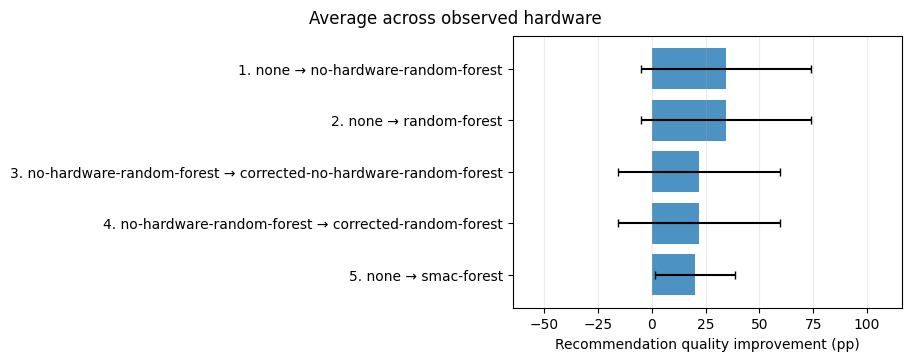

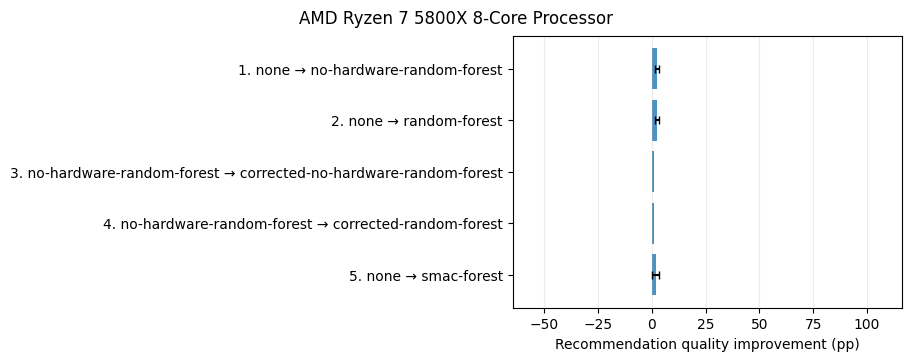

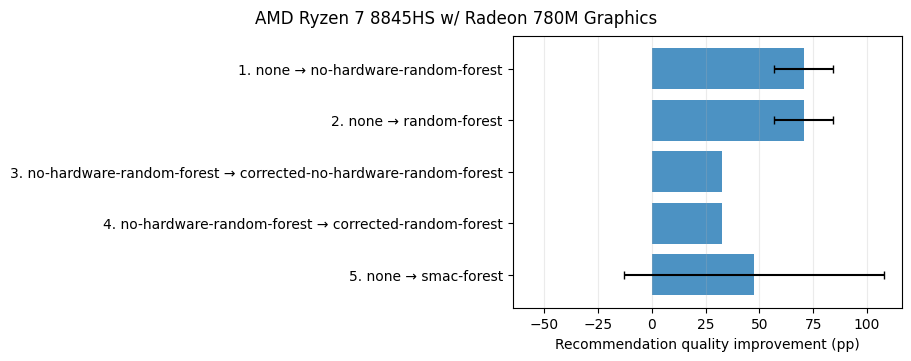

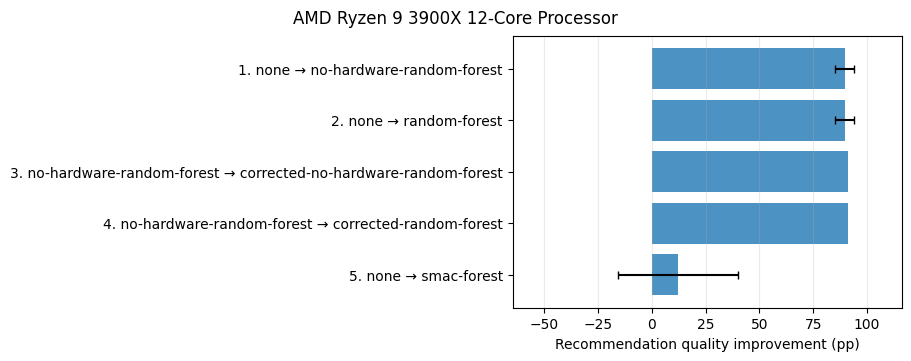

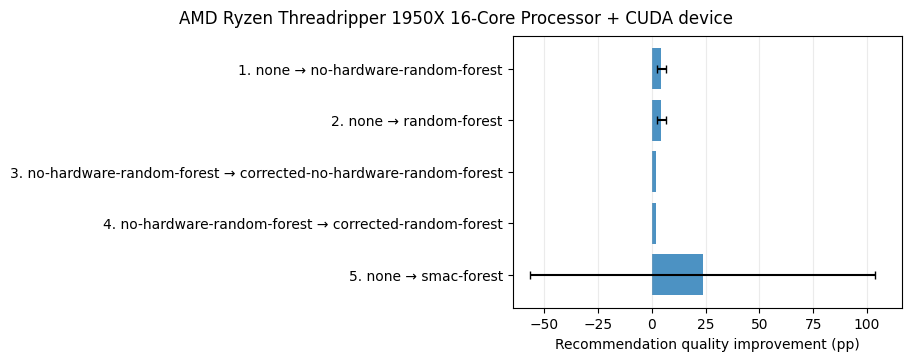

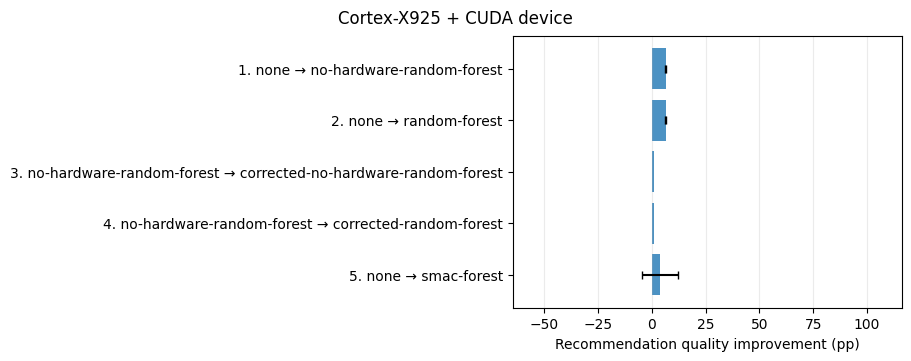

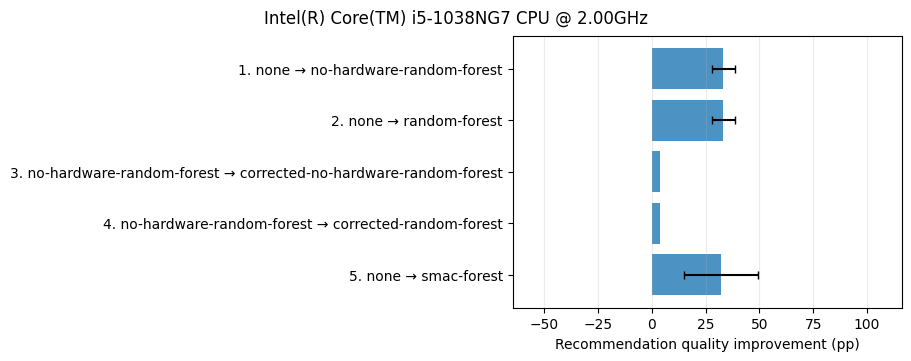

In [55]:
compare_hardware(pool_gain_top, "pool_improvement", "pp", "Recommendation quality improvement (pp)")

## 5. Local convergence

- Round 1: first recommendation after startup, at benchmark step 3 in this evaluation
- Round 1 convergence: same recommended build throughout all reported rounds
- Final quality (%): measured throughput of the final recommendation ÷ best throughput sampled by that session × 100
- Above 100%: recommendation outside the sampled builds with higher measured throughput in the replay pool

In [56]:
convergence_top = rankings("convergence", "round", ascending=True)

#### AMD Ryzen 7 5800X 8-Core Processor

Final quality range: 96.84% to 100% of best sampled
Eligible combinations: 420/420 ready · Range: 1 to 23 round
Tie-breaker: final recommendation quality → final prediction accuracy → historical → local → application → workload (alphabetical); 120 tied at table cutoff


,Application,Workload,Historical,Local,Mean (round),95% CI lower,95% CI upper,Seeds,Final % of best sampled,Final % CI lower,Final % CI upper
1,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-gaussian-process,1.00000000,—,—,1,100.00000000,—,—
2,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-gaussian-process,1.00000000,—,—,1,100.00000000,—,—
3,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-bayes-pairs,1.00000000,—,—,1,100.00000000,—,—
4,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-hardware-interactions,1.00000000,—,—,1,100.00000000,—,—
5,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-hardware-three-way,1.00000000,—,—,1,100.00000000,—,—
6,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-interactions,1.00000000,—,—,1,100.00000000,—,—
7,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-support-vector,1.00000000,—,—,1,100.00000000,—,—
8,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-support-vector,1.00000000,—,—,1,100.00000000,—,—
9,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-smac-forest,1.00000000,—,—,1,100.00000000,—,—
10,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-random-forest,1.00000000,—,—,1,100.00000000,—,—


#### AMD Ryzen 7 8845HS w/ Radeon 780M Graphics

Final quality range: 69.48% to 100.2% of best sampled
Eligible combinations: 420/420 ready · Range: 1 to 23 round
Tie-breaker: final recommendation quality → final prediction accuracy → historical → local → application → workload (alphabetical); 52 tied at table cutoff


,Application,Workload,Historical,Local,Mean (round),95% CI lower,95% CI upper,Seeds,Final % of best sampled,Final % CI lower,Final % CI upper
1,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-random-forest,corrected-bayes-pairs,1.00000000,—,—,1,100.00000000,—,—
2,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-random-forest,corrected-gaussian-process,1.00000000,—,—,1,100.00000000,—,—
3,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-random-forest,corrected-no-hardware-gaussian-process,1.00000000,—,—,1,100.00000000,—,—
4,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-bayes-pairs,1.00000000,—,—,1,100.00000000,—,—
5,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-hardware,1.00000000,—,—,1,100.00000000,—,—
6,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware,1.00000000,—,—,1,100.00000000,—,—
7,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-gaussian-process,1.00000000,—,—,1,100.00000000,—,—
8,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-gaussian-process,1.00000000,—,—,1,100.00000000,—,—
9,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-random-forest,corrected-no-hardware-small-mlp,1.00000000,—,—,1,100.00000000,—,—
10,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-random-forest,corrected-small-mlp,1.00000000,—,—,1,100.00000000,—,—


... (11 outputs left out)

,Application,Workload,Historical,Local,Mean (round),95% CI lower,95% CI upper,Seeds,Final % of best sampled,Final % CI lower,Final % CI upper
1,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-bayes-pairs,1.00000000,—,—,1,100.00000000,—,—
2,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-hardware-interactions,1.00000000,—,—,1,100.00000000,—,—
3,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-hardware-three-way,1.00000000,—,—,1,100.00000000,—,—
4,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-interactions,1.00000000,—,—,1,100.00000000,—,—
5,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-hardware,1.00000000,—,—,1,100.00000000,—,—
6,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware,1.00000000,—,—,1,100.00000000,—,—
7,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-gaussian-process,1.00000000,—,—,1,100.00000000,—,—
8,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-gaussian-process,1.00000000,—,—,1,100.00000000,—,—
9,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-small-mlp,1.00000000,—,—,1,100.00000000,—,—
10,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-small-mlp,1.00000000,—,—,1,100.00000000,—,—


#### Average across observed hardware

Final quality range: 89.11% to 100% of best sampled
Eligible combinations: 380/380 ready · Range: 1 to 22.444444 round
Range of all eligible per-hardware means: 1 to 23 round
Tie-breaker: final recommendation quality → final prediction accuracy → historical → local → application → workload (alphabetical); no tie at table cutoff


,Application,Workload,Historical,Local,Mean (round),95% CI lower,95% CI upper,Platforms,Final % of best sampled,Final % CI lower,Final % CI upper
1,llama.cpp,"[[0, 128], [512, 0]]",hardware-three-way,corrected-kernel-ridge,1.00000000,1.00000000,1.00000000,6,91.04833711,79.98993628,102.10673794
2,llama.cpp,"[[0, 128], [512, 0]]",hardware-three-way,corrected-no-hardware-kernel-ridge,1.00000000,1.00000000,1.00000000,6,91.04833711,79.98993628,102.10673794
3,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-interactions,corrected-kernel-ridge,1.00000000,1.00000000,1.00000000,6,89.10800826,78.74885503,99.46716150
4,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-interactions,corrected-no-hardware-kernel-ridge,1.00000000,1.00000000,1.00000000,6,89.10800826,78.74885503,99.46716150
5,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-support-vector,1.16666667,0.73823636,1.59509697,6,99.90370335,99.74712330,100.06028340
6,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-support-vector,1.16666667,0.73823636,1.59509697,6,99.90370335,99.74712330,100.06028340
7,llama.cpp,"[[0, 128], [512, 0]]",support-vector,corrected-kernel-ridge,2.33333333,0.26973971,4.39692695,6,96.43530257,91.27478765,101.59581748
8,llama.cpp,"[[0, 128], [512, 0]]",support-vector,corrected-no-hardware-kernel-ridge,2.33333333,0.26973971,4.39692695,6,96.43530257,91.27478765,101.59581748
9,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-kernel-ridge,2.66666667,-0.12306937,5.45640270,6,99.65688910,99.14513023,100.16864797
10,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-kernel-ridge,2.66666667,-0.12306937,5.45640270,6,99.65688910,99.14513023,100.16864797


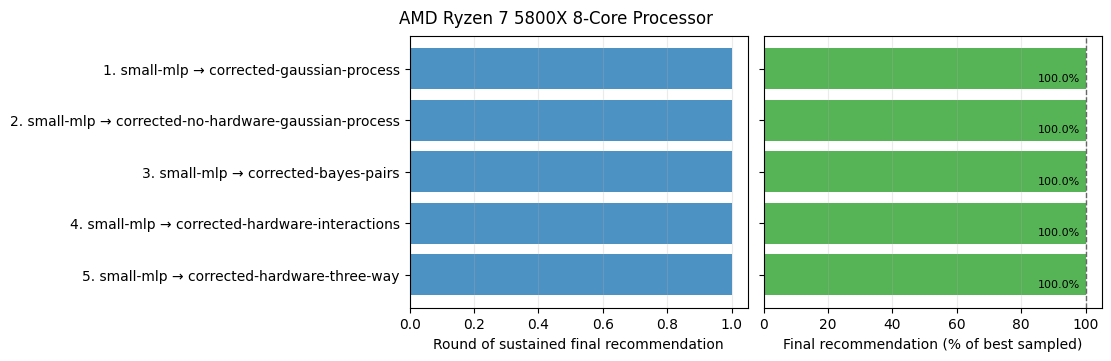

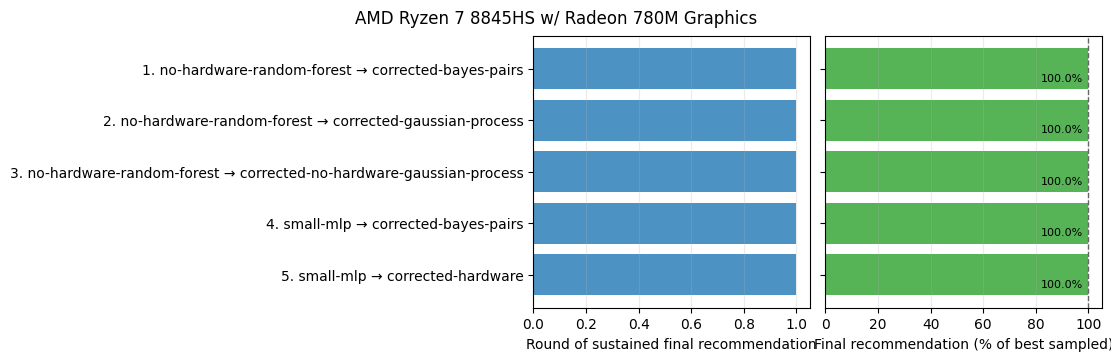

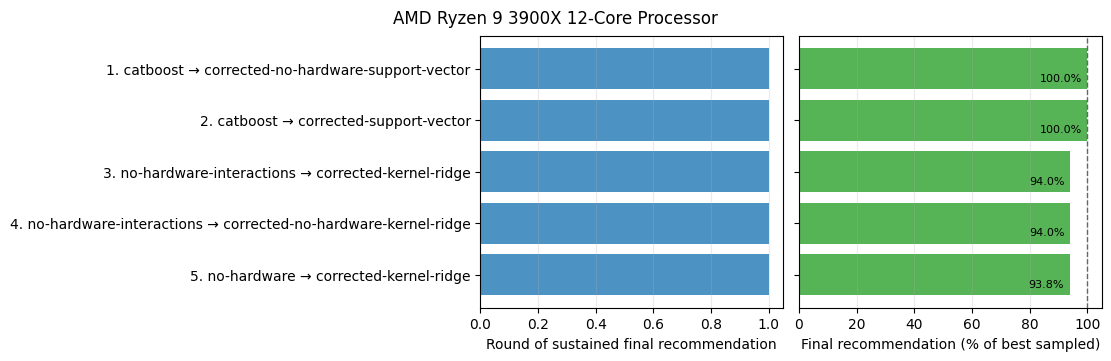

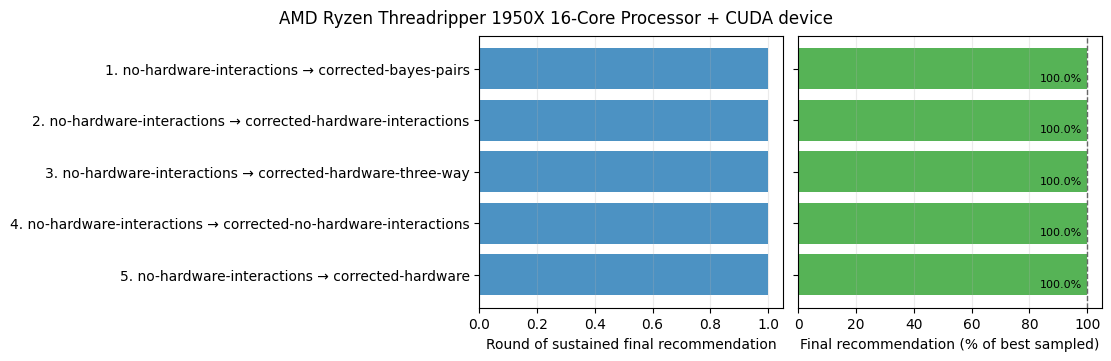

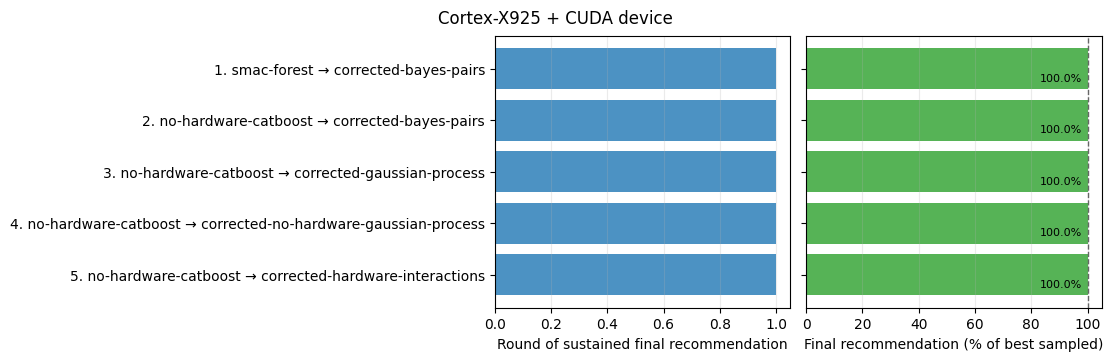

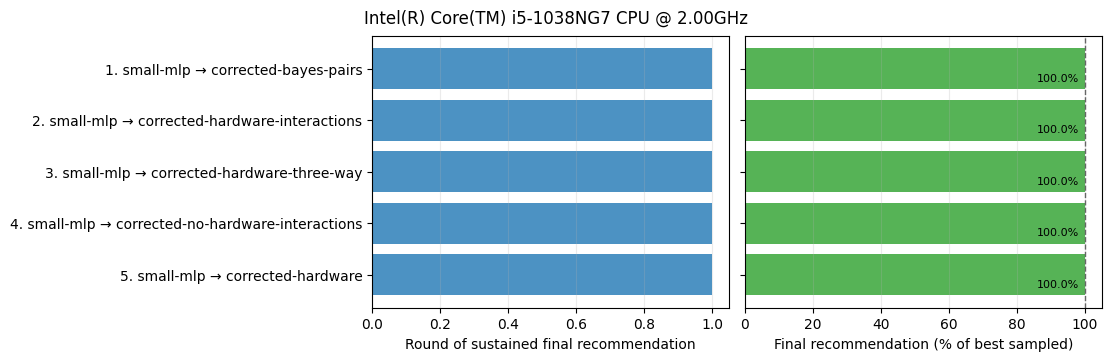

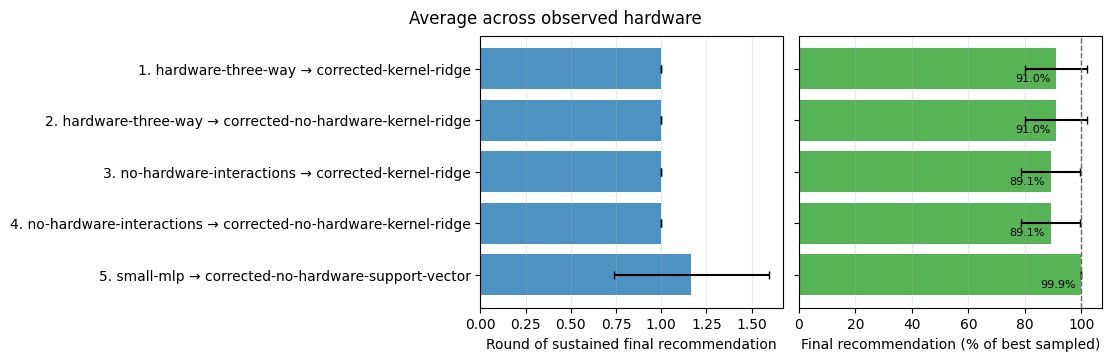

In [57]:
plot_bars(convergence_top, "Round of sustained final recommendation", show_final_quality=True)

### Cross-hardware breakdown

**Average across observed hardware**

,Application,Workload,Historical,Local,Mean (round),95% CI lower,95% CI upper,Platforms
Average rank,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",hardware-three-way,corrected-kernel-ridge,1.00000000,1.00000000,1.00000000,6
2,llama.cpp,"[[0, 128], [512, 0]]",hardware-three-way,corrected-no-hardware-kernel-ridge,1.00000000,1.00000000,1.00000000,6
3,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-interactions,corrected-kernel-ridge,1.00000000,1.00000000,1.00000000,6
4,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-interactions,corrected-no-hardware-kernel-ridge,1.00000000,1.00000000,1.00000000,6
5,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-support-vector,1.16666667,0.73823636,1.59509697,6


**AMD Ryzen 7 5800X 8-Core Processor**

,Application,Workload,Historical,Local,Mean (round),95% CI lower,95% CI upper,Seeds,Difference from average (round)
Average rank,,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",hardware-three-way,corrected-kernel-ridge,1.00000000,—,—,1,0.00000000
2,llama.cpp,"[[0, 128], [512, 0]]",hardware-three-way,corrected-no-hardware-kernel-ridge,1.00000000,—,—,1,0.00000000
3,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-interactions,corrected-kernel-ridge,1.00000000,—,—,1,0.00000000
4,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-interactions,corrected-no-hardware-kernel-ridge,1.00000000,—,—,1,0.00000000
5,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-support-vector,1.00000000,—,—,1,-0.16666667


**AMD Ryzen 7 8845HS w/ Radeon 780M Graphics**

,Application,Workload,Historical,Local,Mean (round),95% CI lower,95% CI upper,Seeds,Difference from average (round)
Average rank,,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",hardware-three-way,corrected-kernel-ridge,1.00000000,—,—,1,0.00000000
2,llama.cpp,"[[0, 128], [512, 0]]",hardware-three-way,corrected-no-hardware-kernel-ridge,1.00000000,—,—,1,0.00000000
3,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-interactions,corrected-kernel-ridge,1.00000000,—,—,1,0.00000000
4,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-interactions,corrected-no-hardware-kernel-ridge,1.00000000,—,—,1,0.00000000
5,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-support-vector,1.00000000,—,—,1,-0.16666667


... (4 outputs left out)

**Cortex-X925 + CUDA device**

,Application,Workload,Historical,Local,Mean (round),95% CI lower,95% CI upper,Seeds,Difference from average (round)
Average rank,,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",hardware-three-way,corrected-kernel-ridge,1.00000000,—,—,1,0.00000000
2,llama.cpp,"[[0, 128], [512, 0]]",hardware-three-way,corrected-no-hardware-kernel-ridge,1.00000000,—,—,1,0.00000000
3,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-interactions,corrected-kernel-ridge,1.00000000,—,—,1,0.00000000
4,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-interactions,corrected-no-hardware-kernel-ridge,1.00000000,—,—,1,0.00000000
5,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-support-vector,1.00000000,—,—,1,-0.16666667


**Intel(R) Core(TM) i5-1038NG7 CPU @ 2.00GHz**

,Application,Workload,Historical,Local,Mean (round),95% CI lower,95% CI upper,Seeds,Difference from average (round)
Average rank,,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",hardware-three-way,corrected-kernel-ridge,1.00000000,—,—,1,0.00000000
2,llama.cpp,"[[0, 128], [512, 0]]",hardware-three-way,corrected-no-hardware-kernel-ridge,1.00000000,—,—,1,0.00000000
3,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-interactions,corrected-kernel-ridge,1.00000000,—,—,1,0.00000000
4,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-interactions,corrected-no-hardware-kernel-ridge,1.00000000,—,—,1,0.00000000
5,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-support-vector,1.00000000,—,—,1,-0.16666667


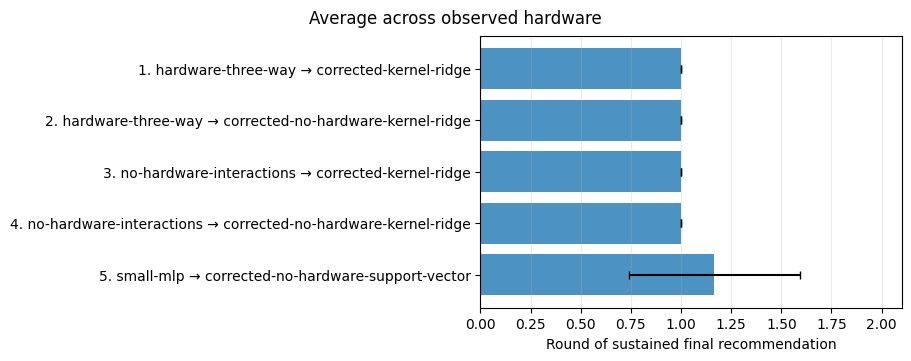

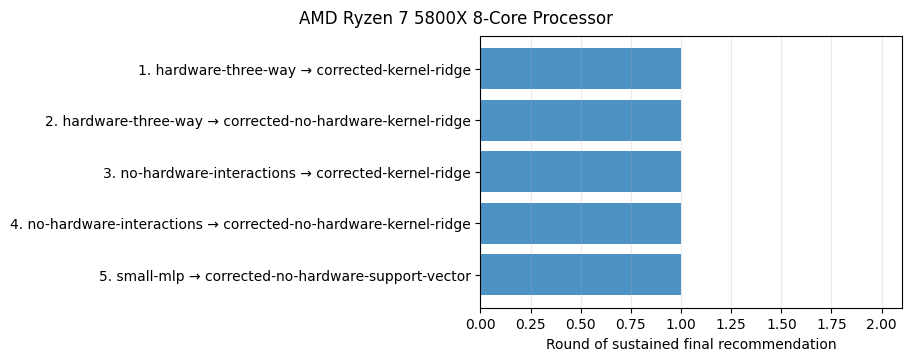

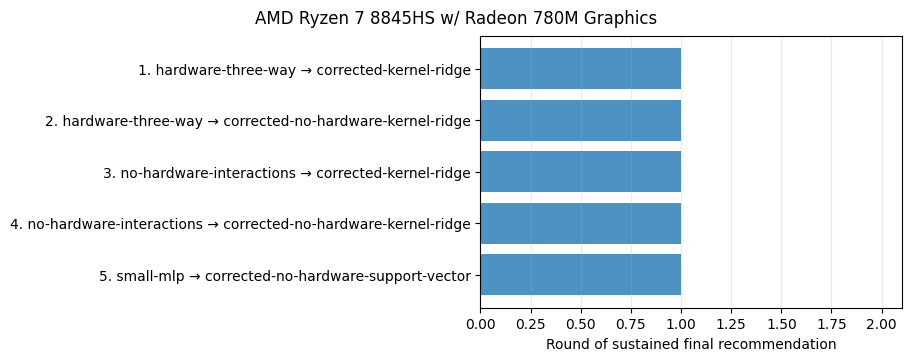

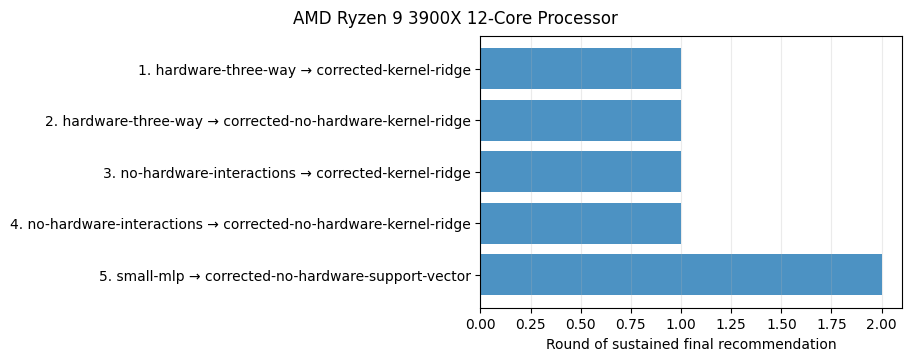

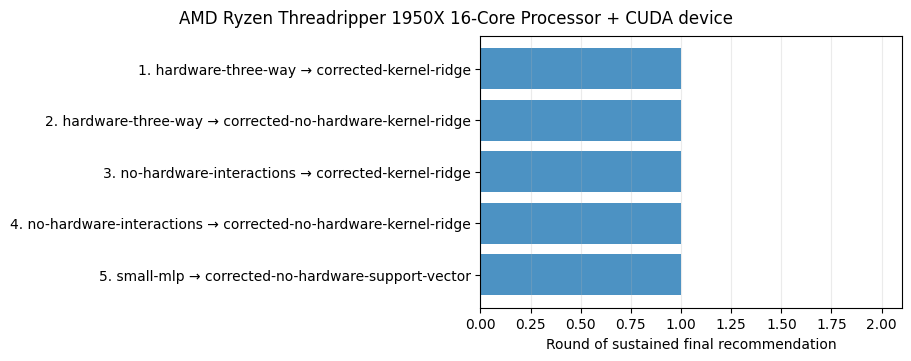

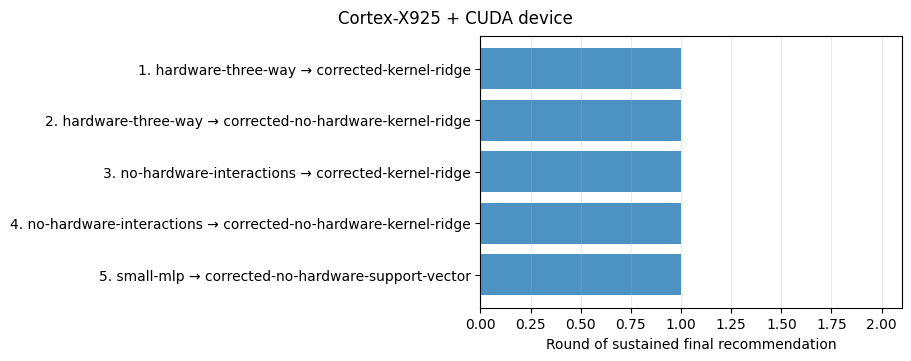

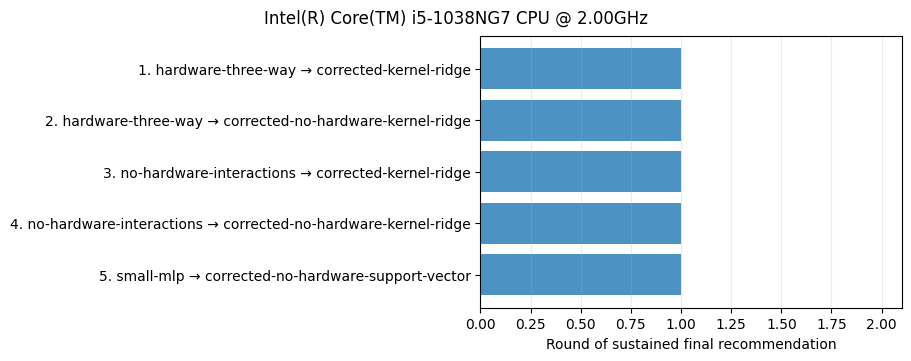

In [58]:
compare_hardware(convergence_top, "convergence", "round", "Round of sustained final recommendation")

## 6. Timing

- Ranking: mean time per round across the session
- Companion columns: final-round time and final prediction accuracy for the same combinations
- Companion values: mean [95% CI], where available

### Prediction

In [59]:
prediction_seconds_top = rankings("prediction_seconds", "ms", ascending=True, companions={
    "final_prediction_seconds": "Final-round time (ms)", "accuracy": "Final prediction accuracy (%)",
})

#### AMD Ryzen 7 5800X 8-Core Processor

Eligible combinations: 420/420 ready · Range: 84.411638 to 18210.805 ms
Tie-breaker: final recommendation quality → final prediction accuracy → historical → local → application → workload (alphabetical); no tie at table cutoff


,Application,Workload,Historical,Local,Mean (ms),95% CI lower,95% CI upper,Seeds,Final-round time (ms),Final prediction accuracy (%)
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-gaussian-process,84.41163783,54.84241888,113.98085677,3,"83.1106 [43.2007, 123.02]","99.9823 [99.9417, 100.023]"
2,llama.cpp,"[[0, 128], [512, 0]]",none,smac-forest,108.25671068,95.88210165,120.63131970,3,"85.9877 [73.4367, 98.5387]","99.412 [99.3, 99.524]"
3,llama.cpp,"[[0, 128], [512, 0]]",none,gaussian-process,114.48161454,74.22649598,154.73673309,3,"78.6099 [33.9536, 123.266]","99.9823 [99.9417, 100.023]"
4,llama.cpp,"[[0, 128], [512, 0]]",none,sparse-bayes,121.27329656,109.51017995,133.03641317,3,"122.629 [65.5599, 179.699]","99.6336 [99.1285, 100.139]"
5,llama.cpp,"[[0, 128], [512, 0]]",no-hardware,corrected-no-hardware-gaussian-process,121.55871035,—,—,1,93.6745,99.9304
6,llama.cpp,"[[0, 128], [512, 0]]",none,bayes-pairs,128.44130455,74.44794023,182.43466888,3,"98.5349 [33.4556, 163.614]","100 [100, 100]"
7,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware,149.25263075,-4.08585971,302.59112121,3,"129.802 [-14.3338, 273.938]","98.887 [97.1579, 100.616]"
8,llama.cpp,"[[0, 128], [512, 0]]",no-hardware,corrected-sparse-bayes,151.15985895,—,—,1,147.475,99.9289
9,llama.cpp,"[[0, 128], [512, 0]]",no-hardware,corrected-gaussian-process,158.85824870,—,—,1,122.654,99.9304
10,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-catboost,166.62509648,104.78062876,228.46956421,3,"218.542 [-96.3356, 533.42]","99.4499 [98.7012, 100.199]"


#### AMD Ryzen 7 8845HS w/ Radeon 780M Graphics

Eligible combinations: 420/420 ready · Range: 20.448088 to 9532.3569 ms
Tie-breaker: final recommendation quality → final prediction accuracy → historical → local → application → workload (alphabetical); no tie at table cutoff


,Application,Workload,Historical,Local,Mean (ms),95% CI lower,95% CI upper,Seeds,Final-round time (ms),Final prediction accuracy (%)
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-gaussian-process,20.44808783,15.16758019,25.72859546,3,"24.2269 [15.5537, 32.9001]","99.9596 [99.7859, 100.133]"
2,llama.cpp,"[[0, 128], [512, 0]]",none,sparse-bayes,34.40844875,30.73946641,38.07743110,3,"41.7197 [30.2332, 53.2062]","81.9492 [28.2746, 135.624]"
3,llama.cpp,"[[0, 128], [512, 0]]",none,gaussian-process,36.95146887,18.93201073,54.97092701,3,"28.4769 [9.93939, 47.0143]","99.9596 [99.7859, 100.133]"
4,llama.cpp,"[[0, 128], [512, 0]]",none,bayes-pairs,38.92271564,28.49713754,49.34829374,3,"44.2044 [26.446, 61.9627]","100 [99.9999, 100]"
5,llama.cpp,"[[0, 128], [512, 0]]",none,smac-forest,51.06453262,34.14306328,67.98600197,3,"45.9471 [16.5191, 75.3752]","93.3991 [91.4966, 95.3017]"
6,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-no-hardware-gaussian-process,61.70705856,—,—,1,63.2235,99.9999
7,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-gaussian-process,67.19974505,—,—,1,57.0473,99.9999
8,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-catboost,67.99473406,54.09398333,81.89548479,3,"61.7694 [47.4946, 76.0443]","85.0131 [71.7407, 98.2856]"
9,llama.cpp,"[[0, 128], [512, 0]]",no-hardware,corrected-no-hardware-gaussian-process,70.53871330,—,—,1,60.2117,99.9999
10,llama.cpp,"[[0, 128], [512, 0]]",sparse-bayes,corrected-no-hardware-gaussian-process,70.95848643,—,—,1,92.6132,99.8358


... (11 outputs left out)

,Application,Workload,Historical,Local,Mean (ms),95% CI lower,95% CI upper,Seeds,Final-round time (ms),Final prediction accuracy (%)
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-gaussian-process,24.16161471,10.72812435,37.59510507,3,"26.3676 [-12.0285, 64.7637]","99.9397 [99.6804, 100.199]"
2,llama.cpp,"[[0, 128], [512, 0]]",none,gaussian-process,28.63474730,27.75912652,29.51036808,3,"28.4481 [5.73915, 51.1571]","99.9397 [99.6804, 100.199]"
3,llama.cpp,"[[0, 128], [512, 0]]",none,sparse-bayes,38.94620786,35.88876984,42.00364587,3,"25.2192 [15.3921, 35.0462]","-33.4692 [-606.186, 539.247]"
4,llama.cpp,"[[0, 128], [512, 0]]",none,bayes-pairs,42.70680700,15.57742691,69.83618709,3,"49.5846 [-7.20387, 106.373]","99.9999 [99.9997, 100]"
5,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware,49.15050583,34.13109232,64.16991933,3,"41.86 [37.5068, 46.2132]","99.9994 [99.9986, 100]"
6,llama.cpp,"[[0, 128], [512, 0]]",none,smac-forest,56.10564991,36.58099048,75.63030935,3,"59.7597 [17.2067, 102.313]","89.7389 [84.1315, 95.3463]"
7,llama.cpp,"[[0, 128], [512, 0]]",no-hardware,corrected-no-hardware-gaussian-process,63.09433526,—,—,1,54.3869,99.8414
8,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-gaussian-process,63.37973900,—,—,1,70.1663,100
9,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-bayes-pairs,69.22971052,—,—,1,71.8309,99.9999
10,llama.cpp,"[[0, 128], [512, 0]]",no-hardware,corrected-gaussian-process,74.92346466,—,—,1,107.134,99.8414


#### Average across observed hardware

Eligible combinations: 380/380 ready · Range: 54.21336 to 15963.138 ms
Range of all eligible per-hardware means: 20.448088 to 23203.338 ms
Tie-breaker: final recommendation quality → final prediction accuracy → historical → local → application → workload (alphabetical); no tie at table cutoff


,Application,Workload,Historical,Local,Mean (ms),95% CI lower,95% CI upper,Platforms,Final-round time (ms),Final prediction accuracy (%)
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-gaussian-process,54.21335980,17.18731147,91.23940813,6,"44.903 [19.0228, 70.7831]","99.9622 [99.9183, 100.006]"
2,llama.cpp,"[[0, 128], [512, 0]]",none,gaussian-process,73.00845470,22.67613386,123.34077555,6,"64.019 [23.7157, 104.322]","99.9622 [99.9183, 100.006]"
3,llama.cpp,"[[0, 128], [512, 0]]",none,sparse-bayes,89.03595523,19.25053671,158.82137375,6,"117.576 [-23.1348, 258.288]","73.4688 [18.0042, 128.933]"
4,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware,92.35792698,50.04775137,134.66810260,6,"111.302 [39.1207, 183.483]","98.9928 [97.8152, 100.171]"
5,llama.cpp,"[[0, 128], [512, 0]]",none,bayes-pairs,97.19729440,25.19360377,169.20098503,6,"99.6465 [27.3589, 171.934]","96.0839 [86.0175, 106.15]"
6,llama.cpp,"[[0, 128], [512, 0]]",no-hardware,corrected-no-hardware-gaussian-process,103.77439270,51.99172594,155.55705947,6,"106.828 [41.6746, 171.981]","99.9481 [99.8804, 100.016]"
7,llama.cpp,"[[0, 128], [512, 0]]",none,smac-forest,111.91268070,19.03206223,204.79329916,6,"85.504 [35.4295, 135.578]","96.6878 [92.2953, 101.08]"
8,llama.cpp,"[[0, 128], [512, 0]]",no-hardware,corrected-gaussian-process,124.94565529,62.72548922,187.16582137,6,"109.196 [64.1515, 154.241]","99.9481 [99.8804, 100.016]"
9,llama.cpp,"[[0, 128], [512, 0]]",sparse-bayes,corrected-no-hardware-gaussian-process,136.42305108,65.63030116,207.21580099,6,"131.738 [69.7798, 193.696]","99.9495 [99.8802, 100.019]"
10,llama.cpp,"[[0, 128], [512, 0]]",none,hardware,150.73092182,84.82556827,216.63627538,6,"173.316 [89.7543, 256.878]","98.9928 [97.8152, 100.171]"


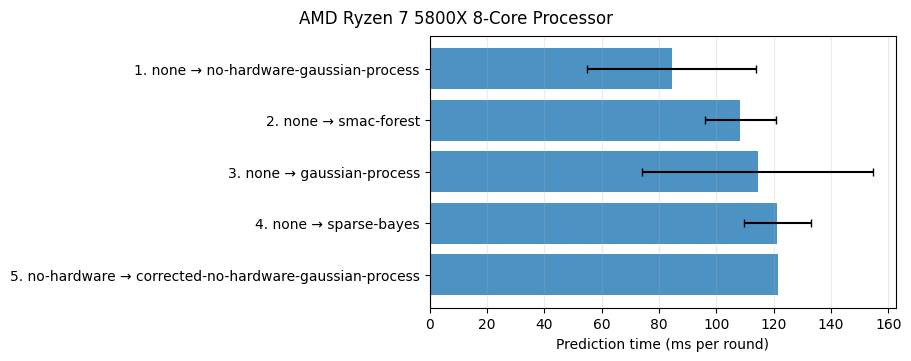

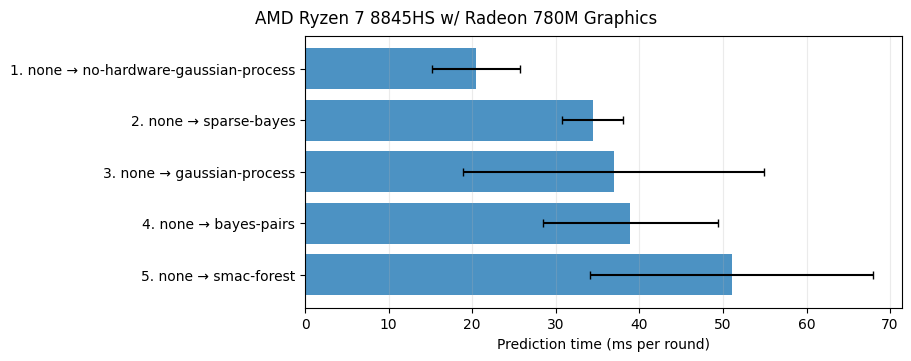

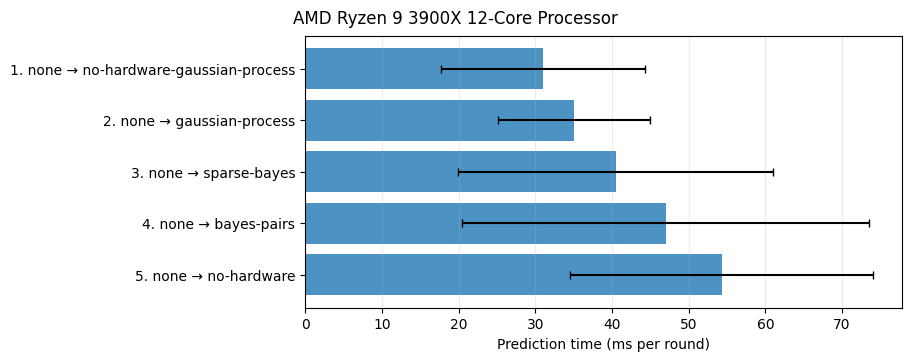

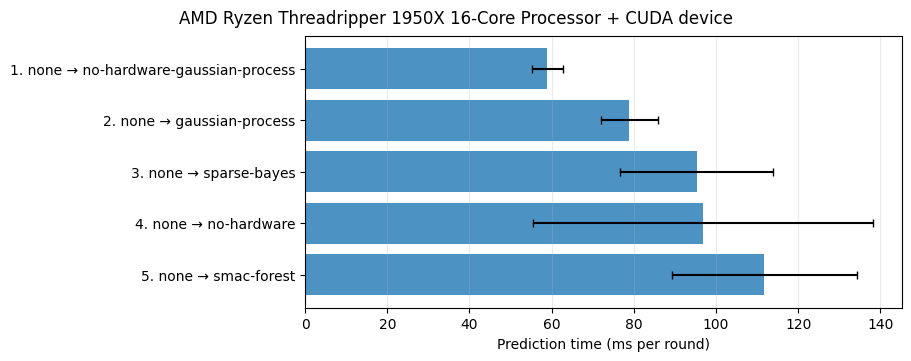

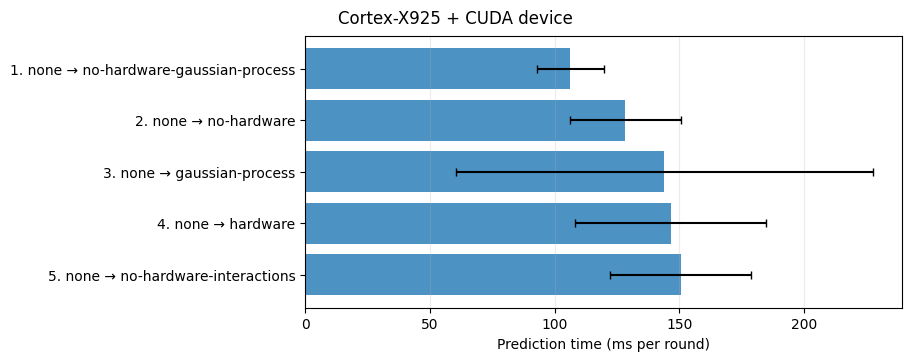

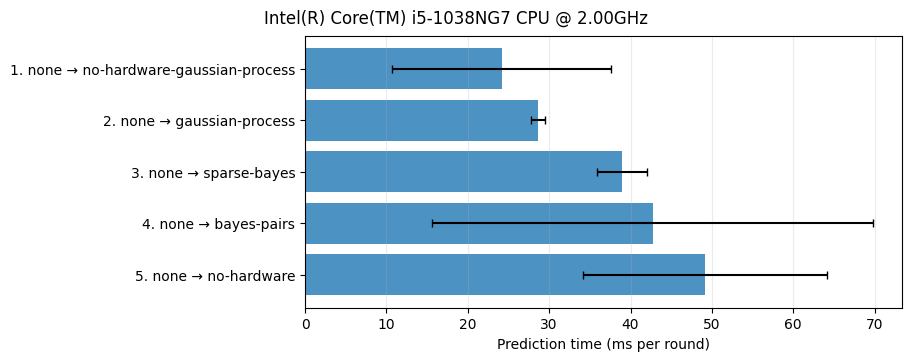

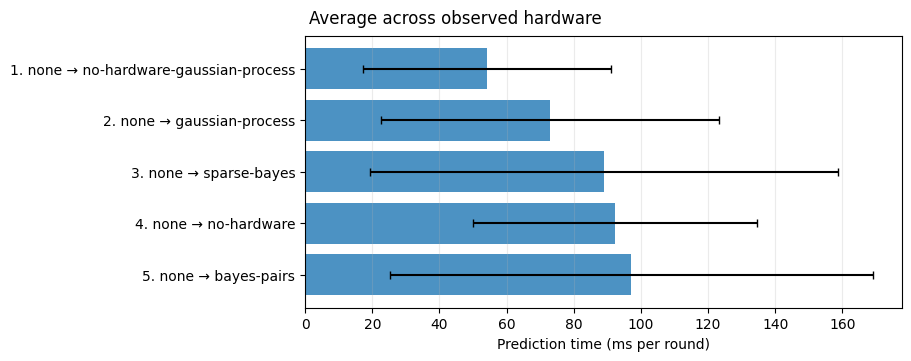

In [60]:
plot_bars(prediction_seconds_top, "Prediction time (ms per round)")

#### Cross-hardware breakdown

**Average across observed hardware**

,Application,Workload,Historical,Local,Mean (ms),95% CI lower,95% CI upper,Platforms
Average rank,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-gaussian-process,54.21335980,17.18731147,91.23940813,6
2,llama.cpp,"[[0, 128], [512, 0]]",none,gaussian-process,73.00845470,22.67613386,123.34077555,6
3,llama.cpp,"[[0, 128], [512, 0]]",none,sparse-bayes,89.03595523,19.25053671,158.82137375,6
4,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware,92.35792698,50.04775137,134.66810260,6
5,llama.cpp,"[[0, 128], [512, 0]]",none,bayes-pairs,97.19729440,25.19360377,169.20098503,6


**AMD Ryzen 7 5800X 8-Core Processor**

,Application,Workload,Historical,Local,Mean (ms),95% CI lower,95% CI upper,Seeds,Difference from average (ms)
Average rank,,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-gaussian-process,84.41163783,54.84241888,113.98085677,3,30.19827803
2,llama.cpp,"[[0, 128], [512, 0]]",none,gaussian-process,114.48161454,74.22649598,154.73673309,3,41.47315983
3,llama.cpp,"[[0, 128], [512, 0]]",none,sparse-bayes,121.27329656,109.51017995,133.03641317,3,32.23734133
4,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware,149.25263075,-4.08585971,302.59112121,3,56.89470377
5,llama.cpp,"[[0, 128], [512, 0]]",none,bayes-pairs,128.44130455,74.44794023,182.43466888,3,31.24401015


**AMD Ryzen 7 8845HS w/ Radeon 780M Graphics**

,Application,Workload,Historical,Local,Mean (ms),95% CI lower,95% CI upper,Seeds,Difference from average (ms)
Average rank,,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-gaussian-process,20.44808783,15.16758019,25.72859546,3,-33.76527197
2,llama.cpp,"[[0, 128], [512, 0]]",none,gaussian-process,36.95146887,18.93201073,54.97092701,3,-36.05698584
3,llama.cpp,"[[0, 128], [512, 0]]",none,sparse-bayes,34.40844875,30.73946641,38.07743110,3,-54.62750648
4,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware,76.24719886,43.68345055,108.81094717,3,-16.11072812
5,llama.cpp,"[[0, 128], [512, 0]]",none,bayes-pairs,38.92271564,28.49713754,49.34829374,3,-58.27457876


... (4 outputs left out)

**Cortex-X925 + CUDA device**

,Application,Workload,Historical,Local,Mean (ms),95% CI lower,95% CI upper,Seeds,Difference from average (ms)
Average rank,,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-gaussian-process,106.25919607,92.91781980,119.60057234,3,52.04583627
2,llama.cpp,"[[0, 128], [512, 0]]",none,gaussian-process,144.00520548,60.33197744,227.67843351,3,70.99675077
3,llama.cpp,"[[0, 128], [512, 0]]",none,sparse-bayes,203.84463968,-49.85999269,457.54927206,3,114.80868445
4,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware,128.35681313,106.24841117,150.46521508,3,35.99888615
5,llama.cpp,"[[0, 128], [512, 0]]",none,bayes-pairs,213.05776635,116.91735753,309.19817517,3,115.86047195


**Intel(R) Core(TM) i5-1038NG7 CPU @ 2.00GHz**

,Application,Workload,Historical,Local,Mean (ms),95% CI lower,95% CI upper,Seeds,Difference from average (ms)
Average rank,,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-gaussian-process,24.16161471,10.72812435,37.59510507,3,-30.05174509
2,llama.cpp,"[[0, 128], [512, 0]]",none,gaussian-process,28.63474730,27.75912652,29.51036808,3,-44.37370740
3,llama.cpp,"[[0, 128], [512, 0]]",none,sparse-bayes,38.94620786,35.88876984,42.00364587,3,-50.08974738
4,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware,49.15050583,34.13109232,64.16991933,3,-43.20742115
5,llama.cpp,"[[0, 128], [512, 0]]",none,bayes-pairs,42.70680700,15.57742691,69.83618709,3,-54.49048740


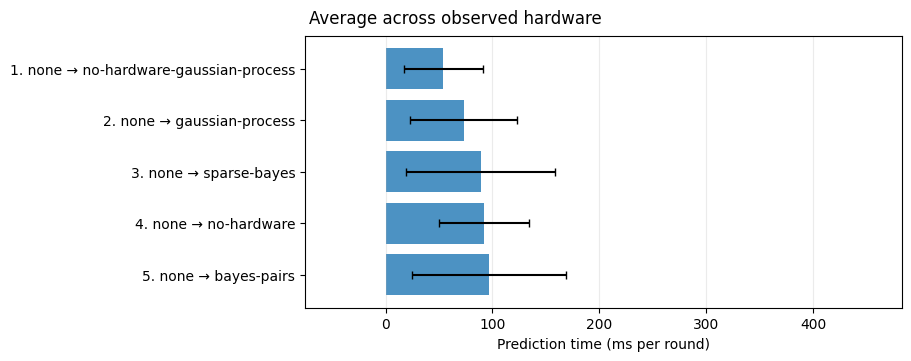

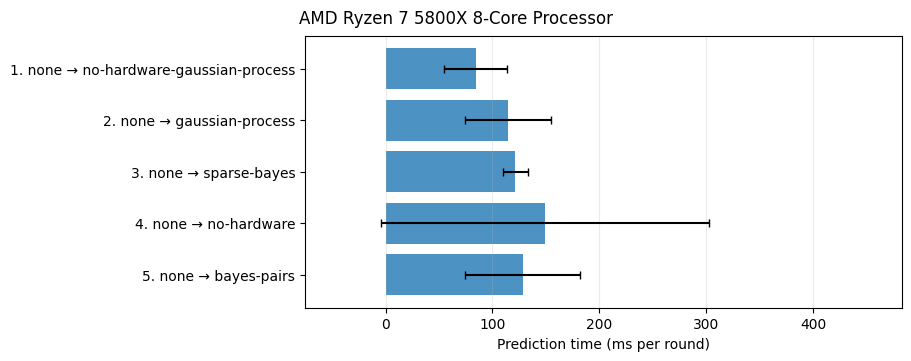

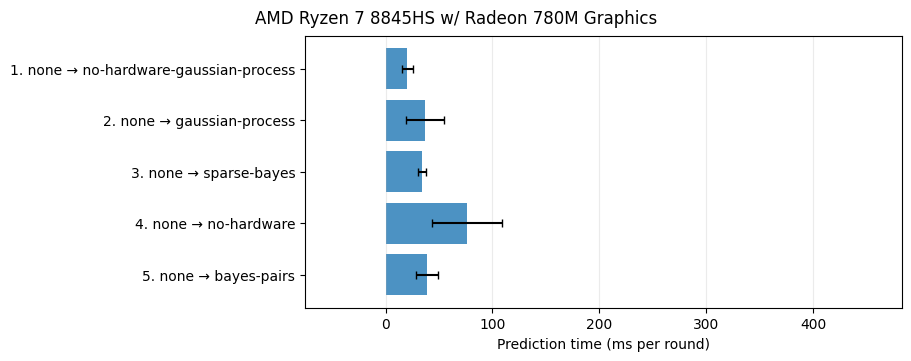

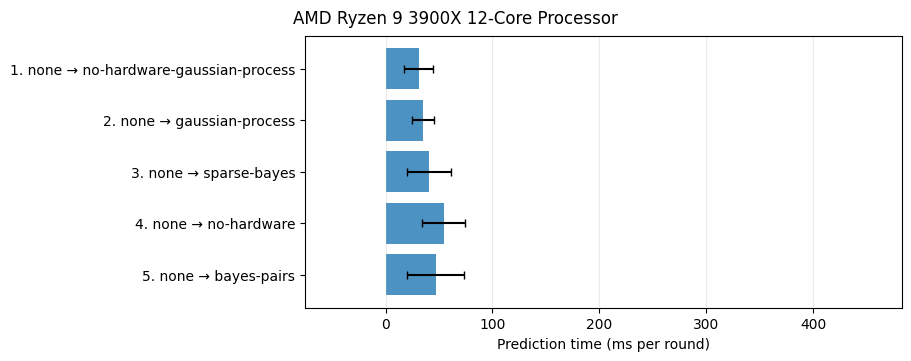

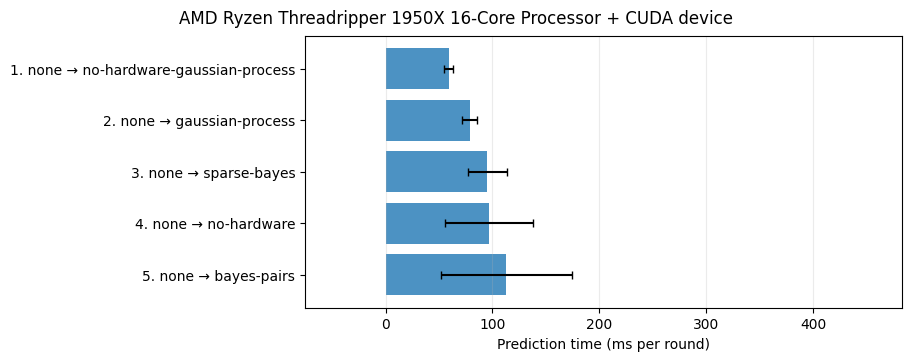

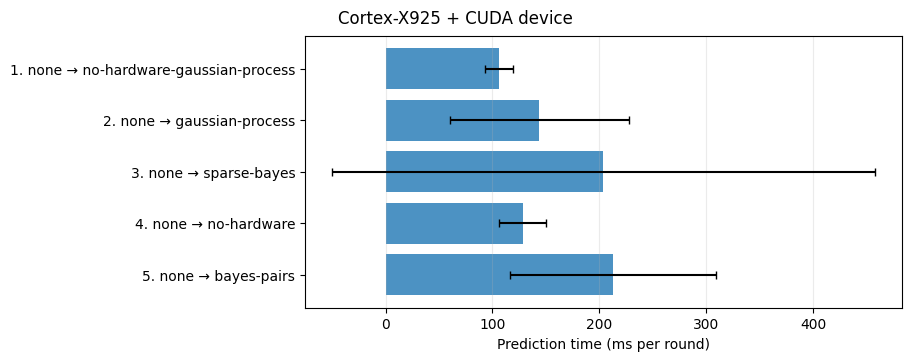

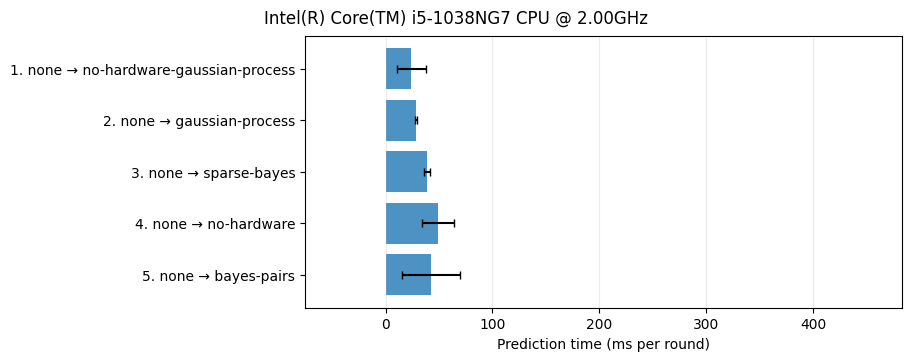

In [61]:
compare_hardware(prediction_seconds_top, "prediction_seconds", "ms", "Prediction time (ms per round)")

### Next sample

In [62]:
next_sample_seconds_top = rankings("next_sample_seconds", "ms", ascending=True, companions={
    "final_next_sample_seconds": "Final-round time (ms)", "accuracy": "Final prediction accuracy (%)",
})

#### AMD Ryzen 7 5800X 8-Core Processor

Eligible combinations: 420/420 ready · Range: 90.307692 to 18068.93 ms
Tie-breaker: final recommendation quality → final prediction accuracy → historical → local → application → workload (alphabetical); no tie at table cutoff


,Application,Workload,Historical,Local,Mean (ms),95% CI lower,95% CI upper,Seeds,Final-round time (ms),Final prediction accuracy (%)
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-gaussian-process,90.30769221,68.33390162,112.28148280,3,"90.6382 [16.0048, 165.272]","99.9823 [99.9417, 100.023]"
2,llama.cpp,"[[0, 128], [512, 0]]",none,smac-forest,108.10323041,93.80112840,122.40533241,3,"83.062 [65.9722, 100.152]","99.412 [99.3, 99.524]"
3,llama.cpp,"[[0, 128], [512, 0]]",none,gaussian-process,110.73810271,100.80002802,120.67617739,3,"69.2068 [55.6475, 82.7661]","99.9823 [99.9417, 100.023]"
4,llama.cpp,"[[0, 128], [512, 0]]",none,bayes-pairs,113.50774075,71.30462965,155.71085185,3,"100.426 [20.4743, 180.377]","100 [100, 100]"
5,llama.cpp,"[[0, 128], [512, 0]]",none,sparse-bayes,116.56201587,88.05077381,145.07325793,3,"145.673 [-27.9318, 319.277]","99.6336 [99.1285, 100.139]"
6,llama.cpp,"[[0, 128], [512, 0]]",no-hardware,corrected-no-hardware-gaussian-process,136.27492574,—,—,1,94.0842,99.9304
7,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware,142.09537433,64.31925849,219.87149018,3,"248.006 [-309.855, 805.868]","98.887 [97.1579, 100.616]"
8,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-catboost,164.16962886,88.21209451,240.12716322,3,"236.058 [-109.252, 581.368]","99.4499 [98.7012, 100.199]"
9,llama.cpp,"[[0, 128], [512, 0]]",no-hardware,corrected-sparse-bayes,165.14049334,—,—,1,171.483,99.9289
10,llama.cpp,"[[0, 128], [512, 0]]",no-hardware,corrected-gaussian-process,172.24294509,—,—,1,300.395,99.9304


#### AMD Ryzen 7 8845HS w/ Radeon 780M Graphics

Eligible combinations: 420/420 ready · Range: 21.891221 to 9671.5585 ms
Tie-breaker: final recommendation quality → final prediction accuracy → historical → local → application → workload (alphabetical); no tie at table cutoff


,Application,Workload,Historical,Local,Mean (ms),95% CI lower,95% CI upper,Seeds,Final-round time (ms),Final prediction accuracy (%)
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-gaussian-process,21.89122145,11.13641650,32.64602639,3,"22.946 [1.39975, 44.4923]","99.9596 [99.7859, 100.133]"
2,llama.cpp,"[[0, 128], [512, 0]]",none,gaussian-process,32.47108940,13.97539410,50.96678471,3,"30.4775 [7.9042, 53.0508]","99.9596 [99.7859, 100.133]"
3,llama.cpp,"[[0, 128], [512, 0]]",none,sparse-bayes,33.92795039,28.82453842,39.03136236,3,"37.5847 [30.4483, 44.7211]","81.9492 [28.2746, 135.624]"
4,llama.cpp,"[[0, 128], [512, 0]]",none,bayes-pairs,39.18752231,17.51578957,60.85925504,3,"42.4872 [7.26337, 77.711]","100 [99.9999, 100]"
5,llama.cpp,"[[0, 128], [512, 0]]",none,smac-forest,50.57680143,46.07519514,55.07840772,3,"43.7833 [18.1945, 69.372]","93.3991 [91.4966, 95.3017]"
6,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-gaussian-process,63.53685630,—,—,1,50.0176,99.9999
7,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-no-hardware-gaussian-process,66.40010431,—,—,1,50.0065,99.9999
8,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-catboost,68.87269522,56.45142389,81.29396655,3,"77.726 [4.56863, 150.883]","85.0131 [71.7407, 98.2856]"
9,llama.cpp,"[[0, 128], [512, 0]]",no-hardware,corrected-no-hardware-gaussian-process,70.80912091,—,—,1,72.0152,99.9999
10,llama.cpp,"[[0, 128], [512, 0]]",sparse-bayes,corrected-no-hardware-gaussian-process,71.30423939,—,—,1,56.7929,99.8358


... (11 outputs left out)

,Application,Workload,Historical,Local,Mean (ms),95% CI lower,95% CI upper,Seeds,Final-round time (ms),Final prediction accuracy (%)
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-gaussian-process,24.42386132,11.01852759,37.82919505,3,"23.7135 [15.0583, 32.3687]","99.9397 [99.6804, 100.199]"
2,llama.cpp,"[[0, 128], [512, 0]]",none,gaussian-process,27.47931371,20.15300241,34.80562501,3,"24.0142 [11.6122, 36.4162]","99.9397 [99.6804, 100.199]"
3,llama.cpp,"[[0, 128], [512, 0]]",none,sparse-bayes,37.87347755,19.04318241,56.70377269,3,"27.9957 [1.37451, 54.6168]","-33.4692 [-606.186, 539.247]"
4,llama.cpp,"[[0, 128], [512, 0]]",none,bayes-pairs,41.43962687,19.32274146,63.55651228,3,"42.3867 [29.8321, 54.9413]","99.9999 [99.9997, 100]"
5,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware,47.98899381,34.24801936,61.72996827,3,"35.4451 [24.6908, 46.1994]","99.9994 [99.9986, 100]"
6,llama.cpp,"[[0, 128], [512, 0]]",none,smac-forest,57.13547361,38.16190141,76.10904581,3,"83.6282 [16.3718, 150.885]","89.7389 [84.1315, 95.3463]"
7,llama.cpp,"[[0, 128], [512, 0]]",sparse-bayes,corrected-no-hardware-gaussian-process,64.06630570,—,—,1,48.5802,100
8,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-gaussian-process,65.97799170,—,—,1,68.3816,100
9,llama.cpp,"[[0, 128], [512, 0]]",no-hardware,corrected-no-hardware-gaussian-process,67.50285378,—,—,1,77.6663,99.8414
10,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-bayes-pairs,69.90974021,—,—,1,62.7824,99.9999


#### Average across observed hardware

Eligible combinations: 380/380 ready · Range: 54.525638 to 15063.278 ms
Range of all eligible per-hardware means: 21.891221 to 19640.954 ms
Tie-breaker: final recommendation quality → final prediction accuracy → historical → local → application → workload (alphabetical); no tie at table cutoff


,Application,Workload,Historical,Local,Mean (ms),95% CI lower,95% CI upper,Platforms,Final-round time (ms),Final prediction accuracy (%)
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-gaussian-process,54.52563753,18.38066457,90.67061049,6,"49.5618 [18.0649, 81.0587]","99.9622 [99.9183, 100.006]"
2,llama.cpp,"[[0, 128], [512, 0]]",none,gaussian-process,72.19143108,21.45353580,122.92932636,6,"63.6888 [12.1219, 115.256]","99.9622 [99.9183, 100.006]"
3,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware,89.31014701,50.62584850,127.99444553,6,"107.457 [25.5386, 189.375]","98.9928 [97.8152, 100.171]"
4,llama.cpp,"[[0, 128], [512, 0]]",none,sparse-bayes,90.57627012,15.98225471,165.17028552,6,"104.166 [-6.29101, 214.623]","73.4688 [18.0042, 128.933]"
5,llama.cpp,"[[0, 128], [512, 0]]",none,bayes-pairs,95.98288006,21.87441756,170.09134256,6,"87.0184 [28.1715, 145.865]","96.0839 [86.0175, 106.15]"
6,llama.cpp,"[[0, 128], [512, 0]]",no-hardware,corrected-no-hardware-gaussian-process,103.46733431,58.62261641,148.31205220,6,"100.555 [58.4196, 142.69]","99.9481 [99.8804, 100.016]"
7,llama.cpp,"[[0, 128], [512, 0]]",none,smac-forest,107.89217510,26.80712367,188.97722653,6,"86.944 [38.7548, 135.133]","96.6878 [92.2953, 101.08]"
8,llama.cpp,"[[0, 128], [512, 0]]",no-hardware,corrected-gaussian-process,130.41272022,68.65967511,192.16576533,6,"135.6 [45.8805, 225.319]","99.9481 [99.8804, 100.016]"
9,llama.cpp,"[[0, 128], [512, 0]]",sparse-bayes,corrected-no-hardware-gaussian-process,133.39361816,64.86775056,201.91948577,6,"130.473 [58.0762, 202.869]","99.9495 [99.8802, 100.019]"
10,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-gaussian-process,149.09631248,55.99131061,242.20131435,6,"194.186 [41.9701, 346.403]","99.9591 [99.8845, 100.034]"


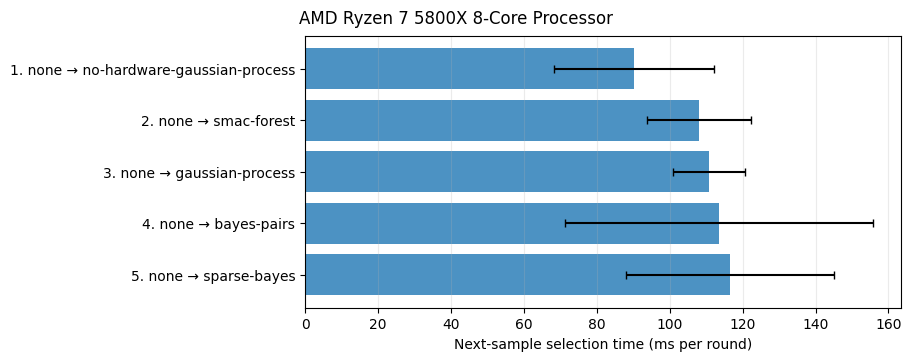

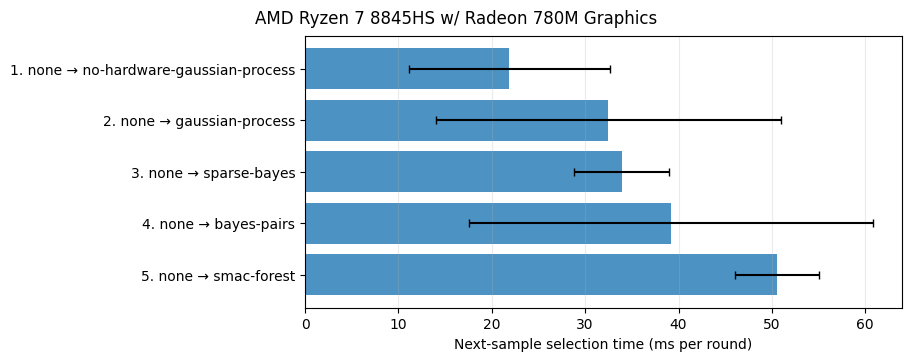

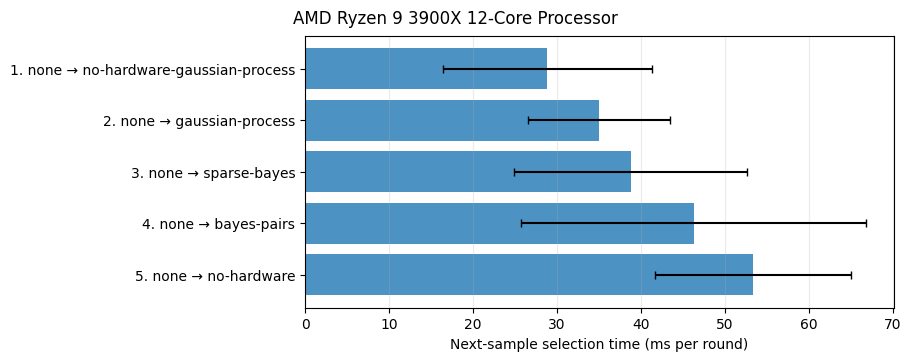

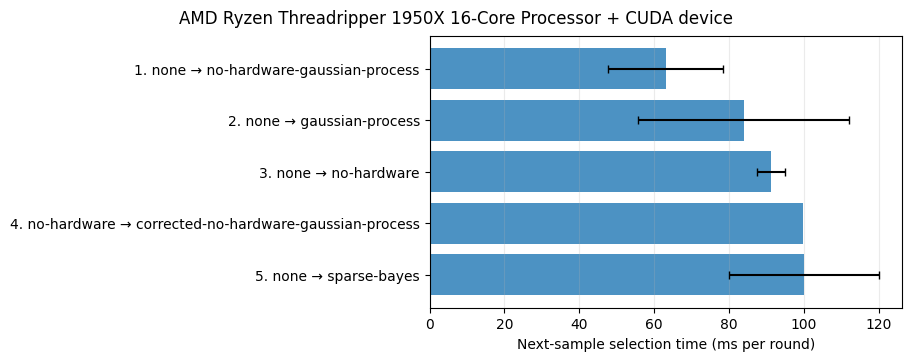

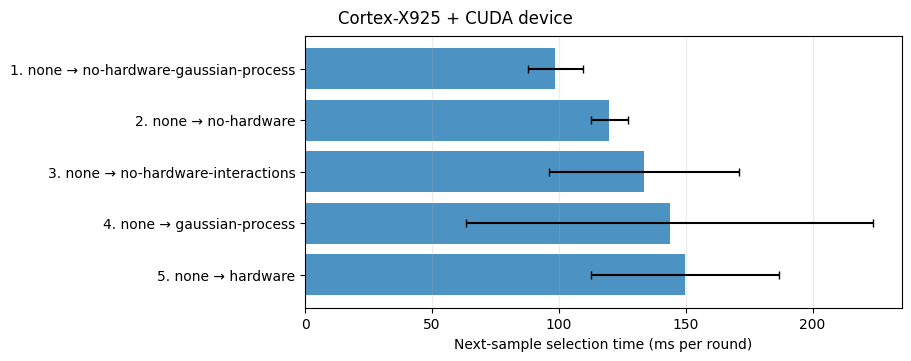

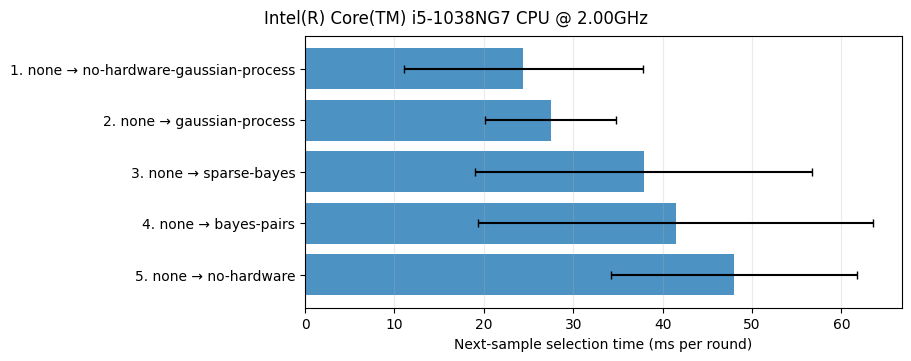

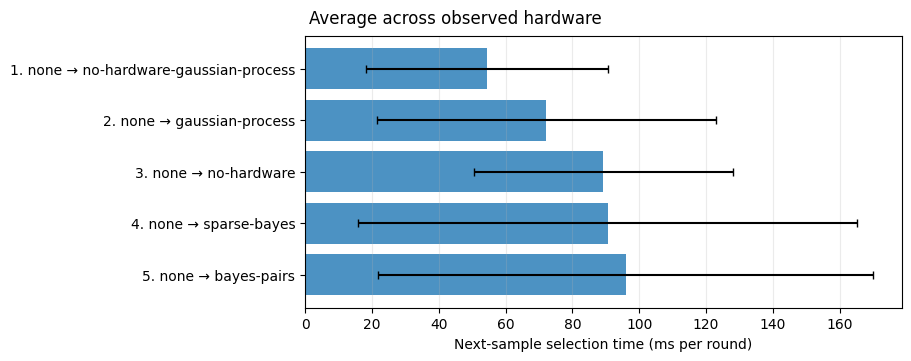

In [63]:
plot_bars(next_sample_seconds_top, "Next-sample selection time (ms per round)")

#### Cross-hardware breakdown

**Average across observed hardware**

,Application,Workload,Historical,Local,Mean (ms),95% CI lower,95% CI upper,Platforms
Average rank,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-gaussian-process,54.52563753,18.38066457,90.67061049,6
2,llama.cpp,"[[0, 128], [512, 0]]",none,gaussian-process,72.19143108,21.45353580,122.92932636,6
3,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware,89.31014701,50.62584850,127.99444553,6
4,llama.cpp,"[[0, 128], [512, 0]]",none,sparse-bayes,90.57627012,15.98225471,165.17028552,6
5,llama.cpp,"[[0, 128], [512, 0]]",none,bayes-pairs,95.98288006,21.87441756,170.09134256,6


**AMD Ryzen 7 5800X 8-Core Processor**

,Application,Workload,Historical,Local,Mean (ms),95% CI lower,95% CI upper,Seeds,Difference from average (ms)
Average rank,,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-gaussian-process,90.30769221,68.33390162,112.28148280,3,35.78205468
2,llama.cpp,"[[0, 128], [512, 0]]",none,gaussian-process,110.73810271,100.80002802,120.67617739,3,38.54667163
3,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware,142.09537433,64.31925849,219.87149018,3,52.78522732
4,llama.cpp,"[[0, 128], [512, 0]]",none,sparse-bayes,116.56201587,88.05077381,145.07325793,3,25.98574576
5,llama.cpp,"[[0, 128], [512, 0]]",none,bayes-pairs,113.50774075,71.30462965,155.71085185,3,17.52486069


**AMD Ryzen 7 8845HS w/ Radeon 780M Graphics**

,Application,Workload,Historical,Local,Mean (ms),95% CI lower,95% CI upper,Seeds,Difference from average (ms)
Average rank,,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-gaussian-process,21.89122145,11.13641650,32.64602639,3,-32.63441608
2,llama.cpp,"[[0, 128], [512, 0]]",none,gaussian-process,32.47108940,13.97539410,50.96678471,3,-39.72034168
3,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware,81.46441316,68.67810388,94.25072245,3,-7.84573385
4,llama.cpp,"[[0, 128], [512, 0]]",none,sparse-bayes,33.92795039,28.82453842,39.03136236,3,-56.64831973
5,llama.cpp,"[[0, 128], [512, 0]]",none,bayes-pairs,39.18752231,17.51578957,60.85925504,3,-56.79535775


... (4 outputs left out)

**Cortex-X925 + CUDA device**

,Application,Workload,Historical,Local,Mean (ms),95% CI lower,95% CI upper,Seeds,Difference from average (ms)
Average rank,,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-gaussian-process,98.64395751,87.88896020,109.39895482,3,44.11831998
2,llama.cpp,"[[0, 128], [512, 0]]",none,gaussian-process,143.64338943,63.36297736,223.92380151,3,71.45195835
3,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware,119.95219284,112.68756042,127.21682525,3,30.64204582
4,llama.cpp,"[[0, 128], [512, 0]]",none,sparse-bayes,216.38226858,-90.25804578,523.02258294,3,125.80599846
5,llama.cpp,"[[0, 128], [512, 0]]",none,bayes-pairs,220.91737906,75.30638830,366.52836981,3,124.93449900


**Intel(R) Core(TM) i5-1038NG7 CPU @ 2.00GHz**

,Application,Workload,Historical,Local,Mean (ms),95% CI lower,95% CI upper,Seeds,Difference from average (ms)
Average rank,,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-gaussian-process,24.42386132,11.01852759,37.82919505,3,-30.10177621
2,llama.cpp,"[[0, 128], [512, 0]]",none,gaussian-process,27.47931371,20.15300241,34.80562501,3,-44.71211737
3,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware,47.98899381,34.24801936,61.72996827,3,-41.32115320
4,llama.cpp,"[[0, 128], [512, 0]]",none,sparse-bayes,37.87347755,19.04318241,56.70377269,3,-52.70279256
5,llama.cpp,"[[0, 128], [512, 0]]",none,bayes-pairs,41.43962687,19.32274146,63.55651228,3,-54.54325319


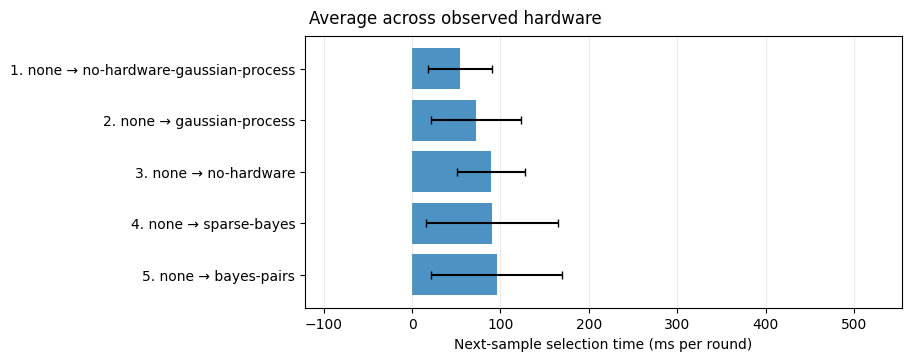

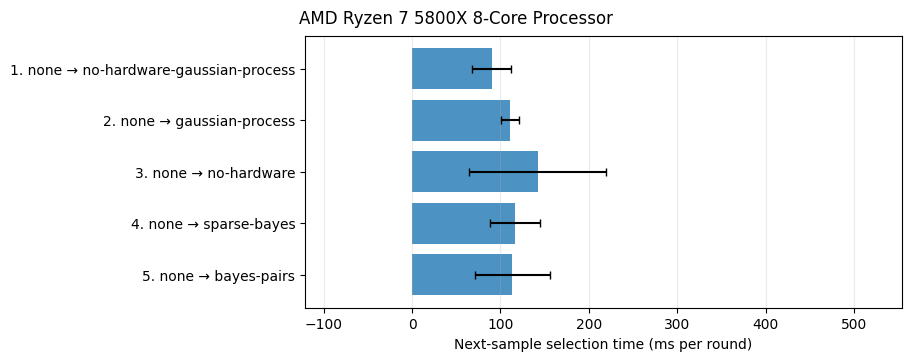

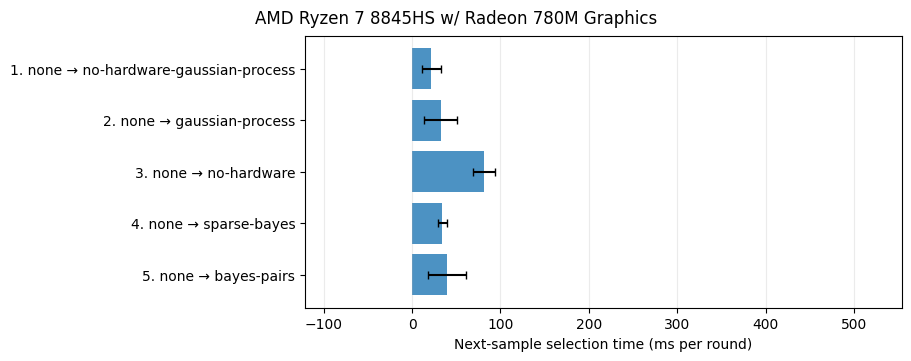

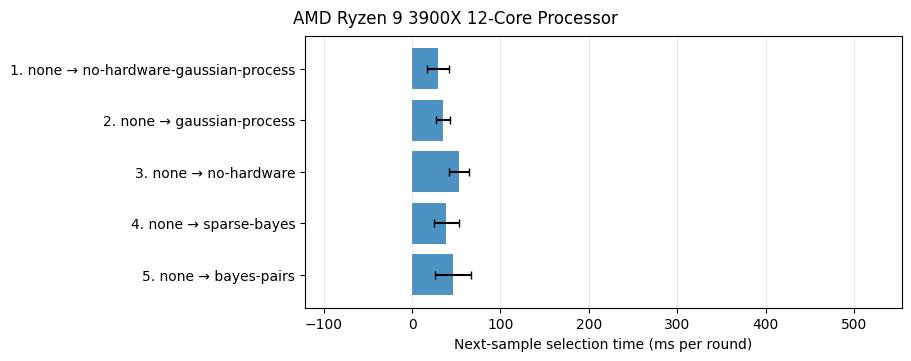

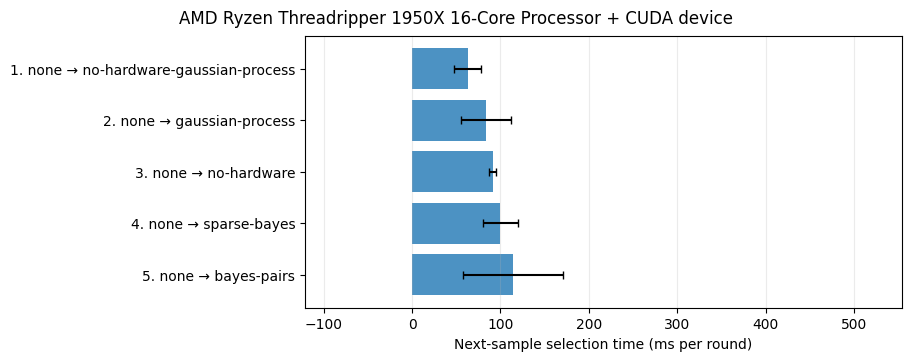

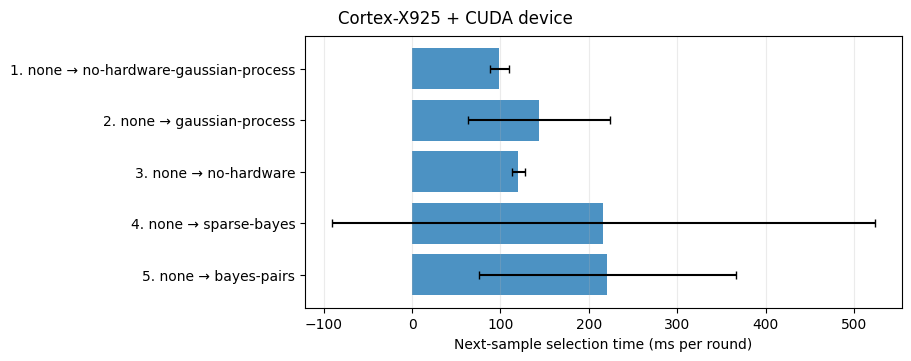

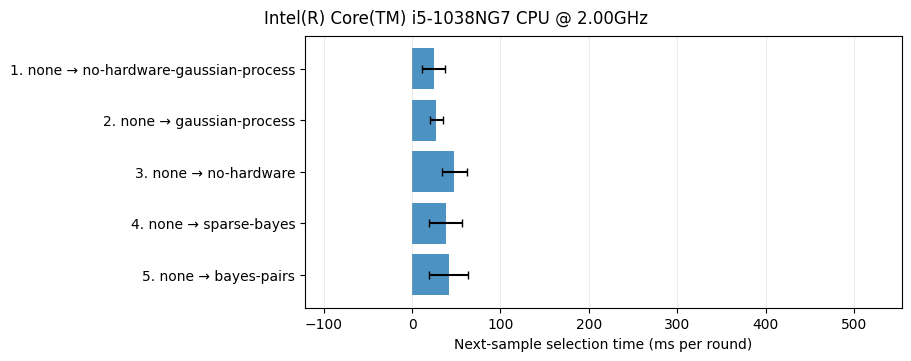

In [64]:
compare_hardware(next_sample_seconds_top, "next_sample_seconds", "ms", "Next-sample selection time (ms per round)")

### Refitting

In [65]:
refit_seconds_top = rankings("refit_seconds", "ms", ascending=True, companions={
    "final_refit_seconds": "Final-round time (ms)", "accuracy": "Final prediction accuracy (%)",
})

#### AMD Ryzen 7 5800X 8-Core Processor

Eligible combinations: 420/420 ready · Range: 82.946742 to 15897.372 ms
Tie-breaker: final recommendation quality → final prediction accuracy → historical → local → application → workload (alphabetical); no tie at table cutoff


,Application,Workload,Historical,Local,Mean (ms),95% CI lower,95% CI upper,Seeds,Final-round time (ms),Final prediction accuracy (%)
1,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-no-hardware,82.94674173,—,—,1,107.366,99.9988
2,llama.cpp,"[[0, 128], [512, 0]]",sparse-bayes,corrected-no-hardware,97.77428031,—,—,1,109.717,99.9938
3,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-hardware,115.90355260,—,—,1,115.073,99.9988
4,llama.cpp,"[[0, 128], [512, 0]]",none,bayes-pairs,119.15368783,76.71599324,161.59138242,3,"92.9772 [55.9681, 129.986]","100 [100, 100]"
5,llama.cpp,"[[0, 128], [512, 0]]",sparse-bayes,corrected-bayes-pairs,129.41145262,—,—,1,177.669,100
6,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-bayes-pairs,133.56469548,—,—,1,135.881,100
7,llama.cpp,"[[0, 128], [512, 0]]",gaussian-process,corrected-bayes-pairs,134.24698509,—,—,1,107.495,99.9999
8,llama.cpp,"[[0, 128], [512, 0]]",gaussian-process,corrected-no-hardware,134.77604940,—,—,1,140.508,98.1835
9,llama.cpp,"[[0, 128], [512, 0]]",smac-forest,corrected-no-hardware,136.33290713,—,—,1,116.947,99.6028
10,llama.cpp,"[[0, 128], [512, 0]]",sparse-bayes,corrected-sparse-bayes,141.15772074,—,—,1,179.772,99.5526


#### AMD Ryzen 7 8845HS w/ Radeon 780M Graphics

Eligible combinations: 420/420 ready · Range: 101.0279 to 11779.756 ms
Tie-breaker: final recommendation quality → final prediction accuracy → historical → local → application → workload (alphabetical); no tie at table cutoff


,Application,Workload,Historical,Local,Mean (ms),95% CI lower,95% CI upper,Seeds,Final-round time (ms),Final prediction accuracy (%)
1,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-no-hardware,101.02789826,—,—,1,130.77,99.9999
2,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware,101.49396003,64.53950514,138.44841492,3,"130.168 [-0.68232, 261.019]","97.0124 [90.2294, 103.795]"
3,llama.cpp,"[[0, 128], [512, 0]]",gaussian-process,corrected-no-hardware,120.36736835,—,—,1,132.56,99.1652
4,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-hardware,124.64898079,—,—,1,171.874,99.9999
5,llama.cpp,"[[0, 128], [512, 0]]",sparse-bayes,corrected-no-hardware,135.57729561,—,—,1,190.814,89.8339
6,llama.cpp,"[[0, 128], [512, 0]]",gaussian-process,corrected-hardware,139.80720856,—,—,1,133.174,99.1652
7,llama.cpp,"[[0, 128], [512, 0]]",none,hardware,145.62925617,76.81256194,214.44595040,3,"162.708 [-21.9435, 347.359]","97.0124 [90.2294, 103.795]"
8,llama.cpp,"[[0, 128], [512, 0]]",none,bayes-pairs,146.32575253,75.69711836,216.95438671,3,"151.918 [34.9959, 268.84]","100 [99.9999, 100]"
9,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-catboost,corrected-no-hardware,146.65844957,—,—,1,128.487,88.8955
10,llama.cpp,"[[0, 128], [512, 0]]",smac-forest,corrected-no-hardware,147.51097131,—,—,1,492.313,99.9984


... (11 outputs left out)

,Application,Workload,Historical,Local,Mean (ms),95% CI lower,95% CI upper,Seeds,Final-round time (ms),Final prediction accuracy (%)
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware,62.39933653,55.17913456,69.61953851,3,"48.5865 [37.768, 59.405]","99.9994 [99.9986, 100]"
2,llama.cpp,"[[0, 128], [512, 0]]",no-hardware,corrected-no-hardware,99.79465887,—,—,1,117.149,99.9981
3,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-no-hardware,126.74870166,—,—,1,104.649,99.9986
4,llama.cpp,"[[0, 128], [512, 0]]",sparse-bayes,corrected-no-hardware,130.98152895,—,—,1,139.905,99.9987
5,llama.cpp,"[[0, 128], [512, 0]]",gaussian-process,corrected-no-hardware,135.55342796,—,—,1,174.045,99.999
6,llama.cpp,"[[0, 128], [512, 0]]",none,hardware,144.90828640,109.45169544,180.36487737,3,"215.795 [152.853, 278.736]","99.9994 [99.9986, 100]"
7,llama.cpp,"[[0, 128], [512, 0]]",none,bayes-pairs,165.24406065,71.21076550,259.27735580,3,"172.785 [113.47, 232.1]","99.9999 [99.9997, 100]"
8,llama.cpp,"[[0, 128], [512, 0]]",bayes-pairs,corrected-no-hardware,173.00160795,—,—,1,236.277,99.9994
9,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-bayes-pairs,173.29003504,—,—,1,180.2,99.9999
10,llama.cpp,"[[0, 128], [512, 0]]",no-hardware,corrected-bayes-pairs,181.30217922,—,—,1,143.457,99.9999


#### Average across observed hardware

Eligible combinations: 380/380 ready · Range: 105.85714 to 16357.976 ms
Range of all eligible per-hardware means: 62.399337 to 26033.148 ms
Tie-breaker: final recommendation quality → final prediction accuracy → historical → local → application → workload (alphabetical); no tie at table cutoff


,Application,Workload,Historical,Local,Mean (ms),95% CI lower,95% CI upper,Platforms,Final-round time (ms),Final prediction accuracy (%)
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware,105.85714012,59.78885725,151.92542300,6,"132.866 [34.2703, 231.462]","98.9928 [97.8152, 100.171]"
2,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-no-hardware,116.47161838,80.81151895,152.13171782,6,"113.076 [87.9977, 138.154]","99.9849 [99.9486, 100.021]"
3,llama.cpp,"[[0, 128], [512, 0]]",sparse-bayes,corrected-no-hardware,137.64956465,109.22664495,166.07248435,6,"162.26 [77.5885, 246.931]","98.2936 [93.9443, 102.643]"
4,llama.cpp,"[[0, 128], [512, 0]]",gaussian-process,corrected-no-hardware,139.65782376,113.74311205,165.57253548,6,"192.291 [75.0006, 309.581]","98.1441 [96.0947, 100.194]"
5,llama.cpp,"[[0, 128], [512, 0]]",no-hardware,corrected-no-hardware,159.36676957,113.69285057,205.04068857,6,"162.858 [100.888, 224.829]","99.6011 [98.6919, 100.51]"
6,llama.cpp,"[[0, 128], [512, 0]]",none,bayes-pairs,160.71125977,113.22738858,208.19513096,6,"185.445 [95.3982, 275.492]","96.0839 [86.0175, 106.15]"
7,llama.cpp,"[[0, 128], [512, 0]]",none,hardware,173.42583359,102.35898557,244.49268162,6,"266.312 [39.7874, 492.837]","98.9928 [97.8152, 100.171]"
8,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-catboost,corrected-no-hardware,174.08946377,112.34968973,235.82923782,6,"177.541 [87.0767, 268.005]","98.0585 [93.3437, 102.773]"
9,llama.cpp,"[[0, 128], [512, 0]]",smac-forest,corrected-no-hardware,177.47563830,120.20616973,234.74510687,6,"202.453 [49.2693, 355.637]","98.0934 [95.1429, 101.044]"
10,llama.cpp,"[[0, 128], [512, 0]]",bayes-pairs,corrected-no-hardware,179.76783389,139.67841263,219.85725516,6,"200.274 [163.28, 237.268]","98.1263 [94.796, 101.457]"


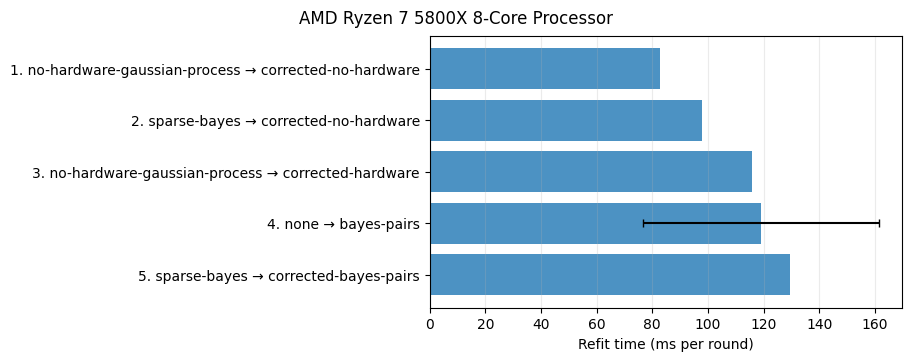

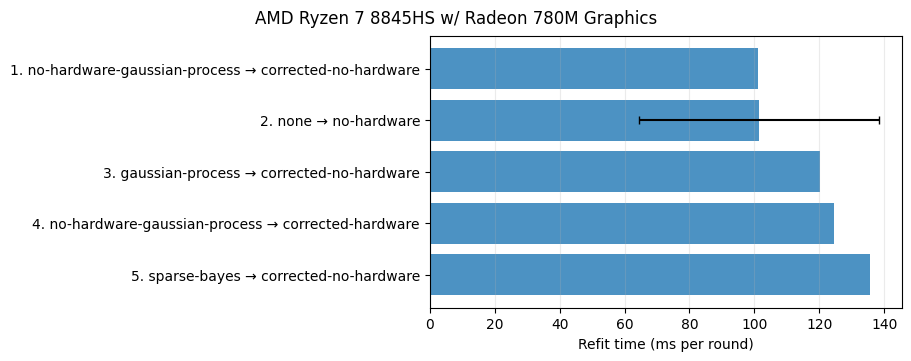

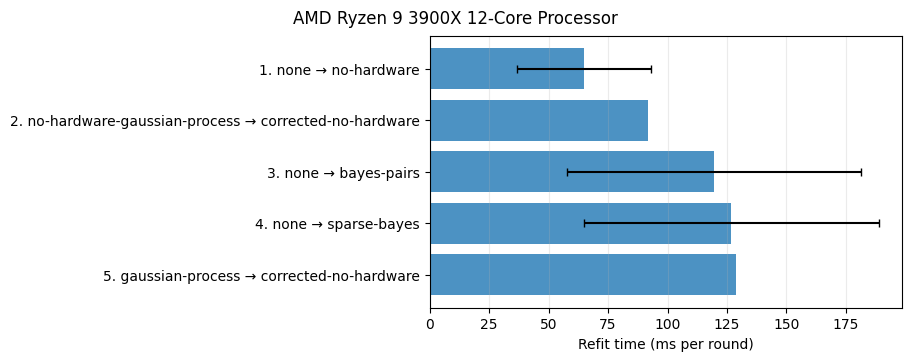

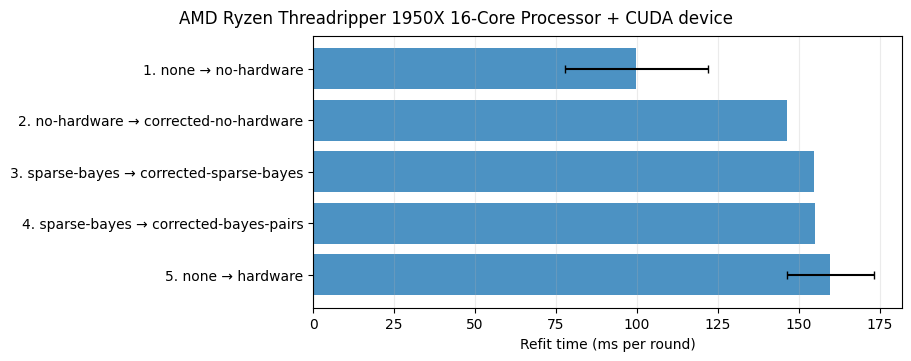

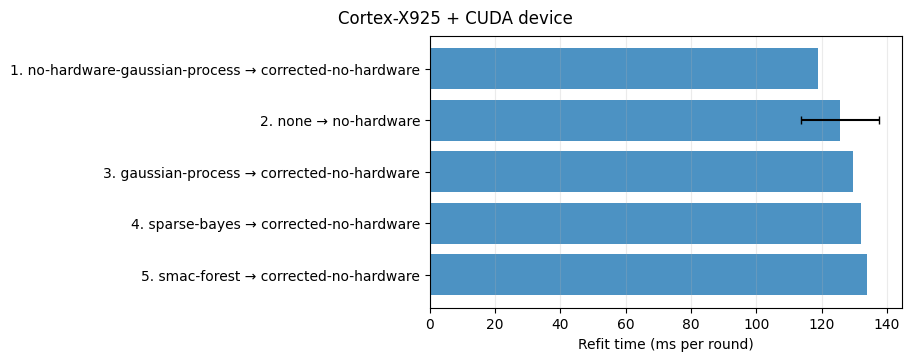

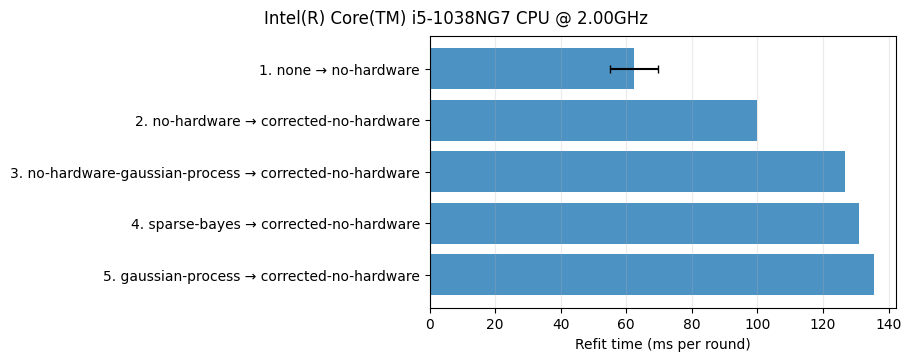

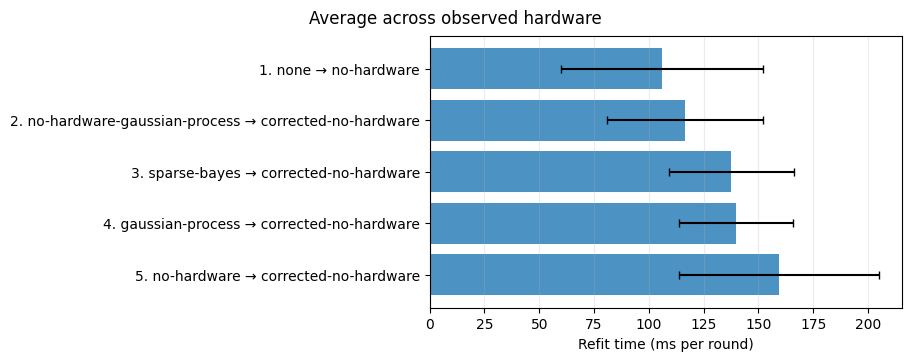

In [66]:
plot_bars(refit_seconds_top, "Refit time (ms per round)")

#### Cross-hardware breakdown

**Average across observed hardware**

,Application,Workload,Historical,Local,Mean (ms),95% CI lower,95% CI upper,Platforms
Average rank,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware,105.85714012,59.78885725,151.92542300,6
2,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-no-hardware,116.47161838,80.81151895,152.13171782,6
3,llama.cpp,"[[0, 128], [512, 0]]",sparse-bayes,corrected-no-hardware,137.64956465,109.22664495,166.07248435,6
4,llama.cpp,"[[0, 128], [512, 0]]",gaussian-process,corrected-no-hardware,139.65782376,113.74311205,165.57253548,6
5,llama.cpp,"[[0, 128], [512, 0]]",no-hardware,corrected-no-hardware,159.36676957,113.69285057,205.04068857,6


**AMD Ryzen 7 5800X 8-Core Processor**

,Application,Workload,Historical,Local,Mean (ms),95% CI lower,95% CI upper,Seeds,Difference from average (ms)
Average rank,,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware,180.82885919,45.39217213,316.26554625,3,74.97171907
2,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-no-hardware,82.94674173,—,—,1,-33.52487665
3,llama.cpp,"[[0, 128], [512, 0]]",sparse-bayes,corrected-no-hardware,97.77428031,—,—,1,-39.87528434
4,llama.cpp,"[[0, 128], [512, 0]]",gaussian-process,corrected-no-hardware,134.77604940,—,—,1,-4.88177436
5,llama.cpp,"[[0, 128], [512, 0]]",no-hardware,corrected-no-hardware,147.57924213,—,—,1,-11.78752744


**AMD Ryzen 7 8845HS w/ Radeon 780M Graphics**

,Application,Workload,Historical,Local,Mean (ms),95% CI lower,95% CI upper,Seeds,Difference from average (ms)
Average rank,,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware,101.49396003,64.53950514,138.44841492,3,-4.36318009
2,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-no-hardware,101.02789826,—,—,1,-15.44372013
3,llama.cpp,"[[0, 128], [512, 0]]",sparse-bayes,corrected-no-hardware,135.57729561,—,—,1,-2.07226903
4,llama.cpp,"[[0, 128], [512, 0]]",gaussian-process,corrected-no-hardware,120.36736835,—,—,1,-19.29045541
5,llama.cpp,"[[0, 128], [512, 0]]",no-hardware,corrected-no-hardware,156.76771695,—,—,1,-2.59905262


... (4 outputs left out)

**Cortex-X925 + CUDA device**

,Application,Workload,Historical,Local,Mean (ms),95% CI lower,95% CI upper,Seeds,Difference from average (ms)
Average rank,,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware,125.69581489,113.78026084,137.61136894,3,19.83867477
2,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-no-hardware,118.83319343,—,—,1,2.36157505
3,llama.cpp,"[[0, 128], [512, 0]]",sparse-bayes,corrected-no-hardware,131.99420935,—,—,1,-5.65535529
4,llama.cpp,"[[0, 128], [512, 0]]",gaussian-process,corrected-no-hardware,129.69629704,—,—,1,-9.96152672
5,llama.cpp,"[[0, 128], [512, 0]]",no-hardware,corrected-no-hardware,233.08312691,—,—,1,73.71635734


**Intel(R) Core(TM) i5-1038NG7 CPU @ 2.00GHz**

,Application,Workload,Historical,Local,Mean (ms),95% CI lower,95% CI upper,Seeds,Difference from average (ms)
Average rank,,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware,62.39933653,55.17913456,69.61953851,3,-43.45780359
2,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-no-hardware,126.74870166,—,—,1,10.27708327
3,llama.cpp,"[[0, 128], [512, 0]]",sparse-bayes,corrected-no-hardware,130.98152895,—,—,1,-6.66803570
4,llama.cpp,"[[0, 128], [512, 0]]",gaussian-process,corrected-no-hardware,135.55342796,—,—,1,-4.10439581
5,llama.cpp,"[[0, 128], [512, 0]]",no-hardware,corrected-no-hardware,99.79465887,—,—,1,-59.57211070


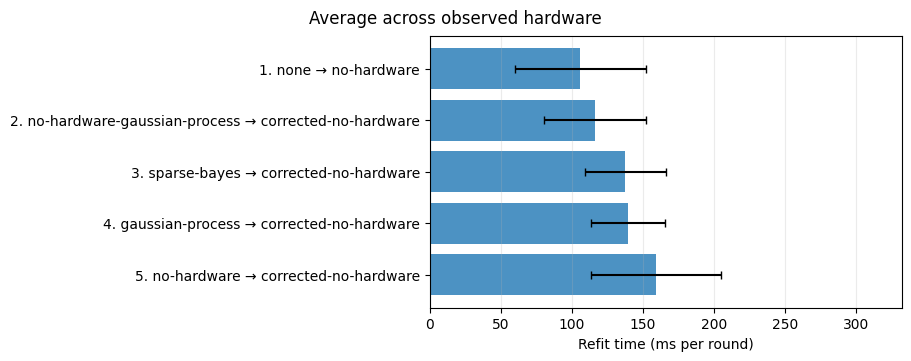

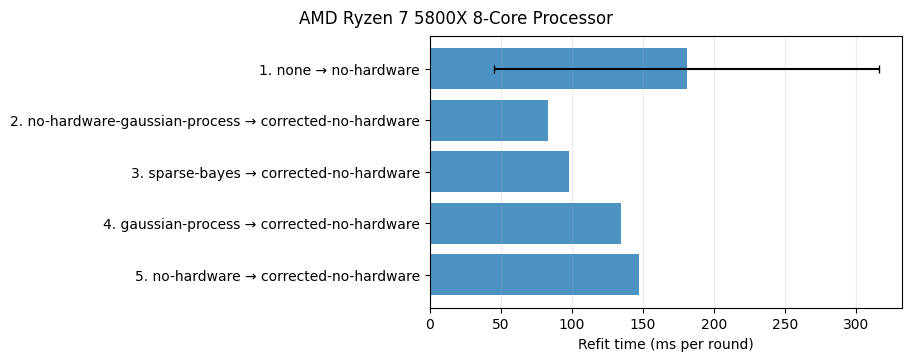

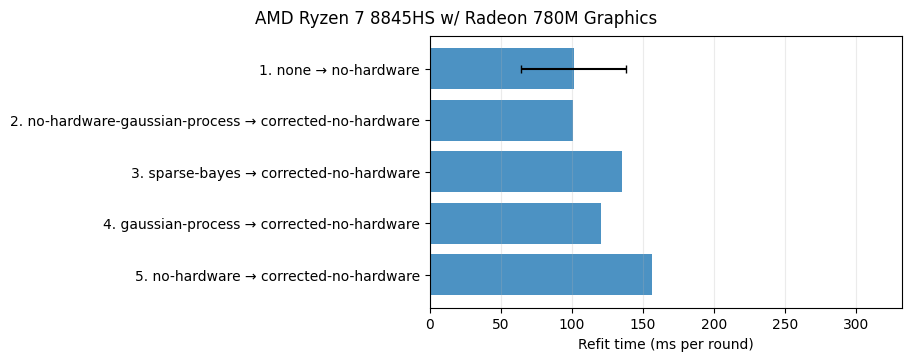

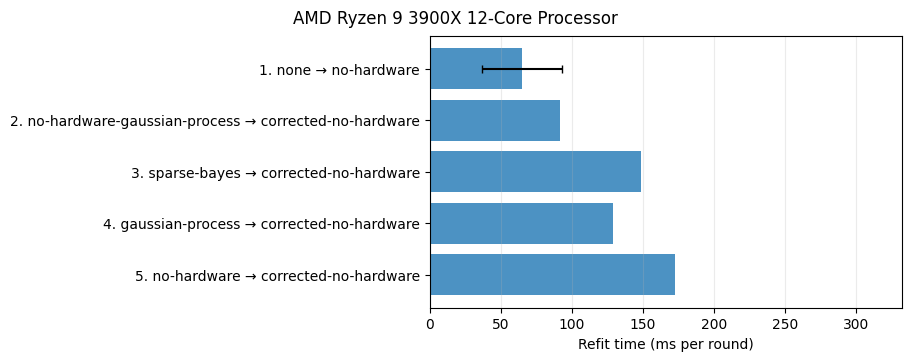

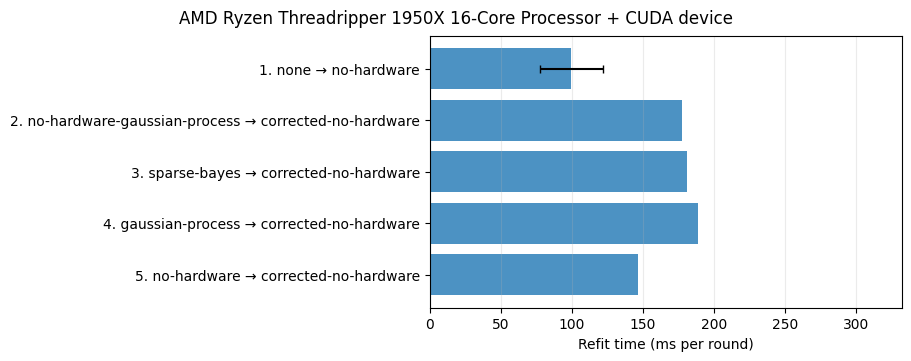

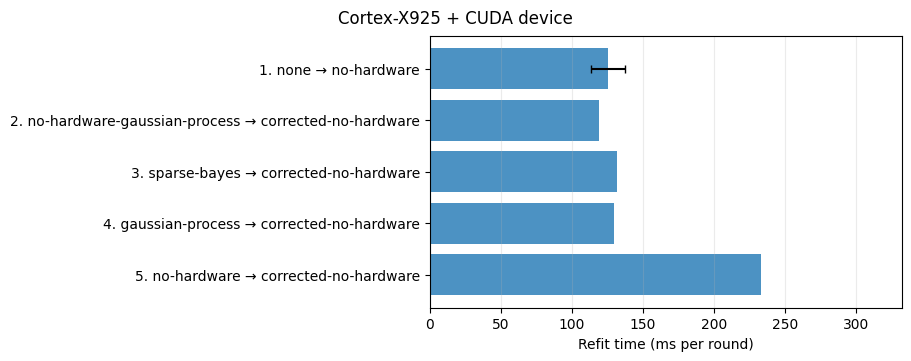

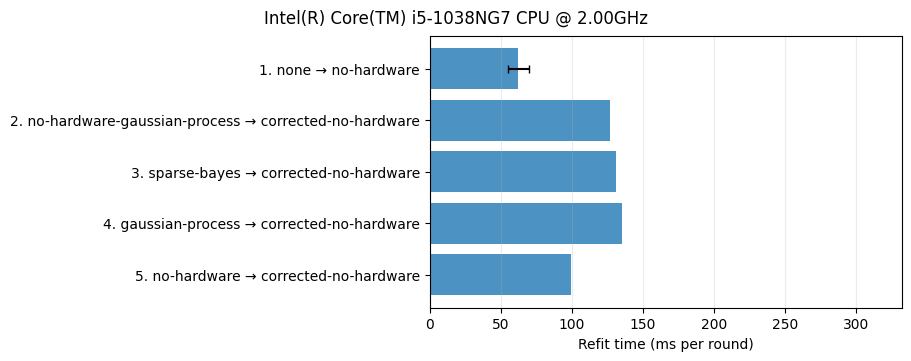

In [67]:
compare_hardware(refit_seconds_top, "refit_seconds", "ms", "Refit time (ms per round)")

## 7. Combined score

The score gives 40% to final recommendation quality (35% against the replay pool and 5% against sampled builds), 20% to final prediction accuracy, 20% to convergence, 10% to improvement, and 10% to timing. Final outcomes carry the most weight. Timings across the full session carry more weight than final-round timings.

For each component, let $x$ be its value for a session and let $L$ and $H$ be the minimum and maximum across eligible sessions on that hardware. Normalize to $z=(x-L)/(H-L)$ when higher is better, and $z=(H-x)/(H-L)$ when lower is better. Use $z=0.5$ if $H=L$. Convergence and all timings are lower-is-better.

$$
\begin{aligned}
S={}&35z_{\text{pool quality}} + 5z_{\text{sampled quality}} + 20z_{\text{accuracy}}\\
 &+7z_{\text{quality gain}} + 3z_{\text{accuracy gain}} + 20z_{\text{convergence}}\\
 &+3(z_{\text{prediction time}} + z_{\text{selection time}} + z_{\text{refit time}})\\
 &+\tfrac{1}{3}(z_{\text{final prediction time}} + z_{\text{final selection time}} + z_{\text{final refit time}}).
\end{aligned}
$$

Higher scores are better on this 0–100 scale. A combination is eligible on a platform only if all its completed sessions have every component. The table shows the mean of each component in its original units and the mean combined score. As in the other rankings, the hardware average gives each platform equal weight and requires eligibility on every platform. Scores are relative to the eligible sessions in this snapshot, so changes to the evaluation pool can change the normalization.

In [68]:
# Component: (table label, weight in score points, higher is better)
combined_components = {
    "pool_share": ("Final pool quality (%)", 35, True),
    "sampled_quality": ("Final sampled quality (%)", 5, True),
    "accuracy": ("Final accuracy (%)", 20, True),
    "pool_improvement": ("Pool quality gain (pp)", 7, True),
    "improvement": ("Accuracy gain (pp)", 3, True),
    "convergence": ("Convergence (round)", 20, False),
    "prediction_seconds": ("Prediction (ms/round)", 3, False),
    "next_sample_seconds": ("Selection (ms/round)", 3, False),
    "refit_seconds": ("Refit (ms/round)", 3, False),
    "final_prediction_seconds": ("Final prediction (ms)", 1 / 3, False),
    "final_next_sample_seconds": ("Final selection (ms)", 1 / 3, False),
    "final_refit_seconds": ("Final refit (ms)", 1 / 3, False),
}
metrics["sampled_quality"] = final_quality
components = pd.DataFrame({field: metrics[field] for field in combined_components})
complete_components = np.isfinite(components).all(axis=1)
eligible = complete_components.groupby(level=GROUP).transform("all")
eligible_components = components.loc[eligible]
by_platform = eligible_components.groupby(level="platform")
lower = by_platform.transform("min")
span = by_platform.transform("max") - lower
normalized = ((eligible_components - lower) / span.where(span.ne(0))).mask(span.eq(0), 0.5)

weights = {}
for field, (_, weight, higher_is_better) in combined_components.items():
    weights[field] = weight
    if not higher_is_better:
        normalized[field] = 1 - normalized[field]
metrics["combined"] = normalized.mul(pd.Series(weights)).sum(axis=1)
combined_top = rankings(
    "combined", "score points",
    companions={field: spec[0] for field, spec in combined_components.items()},
    companion_intervals=False,
)

#### AMD Ryzen 7 5800X 8-Core Processor

Eligible combinations: 420/420 ready · Range: 31.161377 to 92.810184 score points
Tie-breaker: final recommendation quality → final prediction accuracy → historical → local → application → workload (alphabetical); no tie at table cutoff


,Application,Workload,Historical,Local,Final pool quality (%),Final sampled quality (%),Final accuracy (%),Pool quality gain (pp),Accuracy gain (pp),Convergence (round),Prediction (ms/round),Selection (ms/round),Refit (ms/round),Final prediction (ms),Final selection (ms),Final refit (ms),Mean (score points),95% CI lower,95% CI upper,Seeds
1,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-hardware-interactions,99.51669596,100.00000000,99.99413894,0.00000000,0.00437640,1.00000000,685.76972057,677.16756992,361.93987431,1199.12619801,719.90519599,385.18196304,92.81018449,—,—,1
2,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-interactions,99.51669596,100.00000000,99.99413894,0.00000000,0.00437640,1.00000000,686.99003057,678.59548625,371.31765113,696.03702397,868.14899801,762.17319502,92.80755805,—,—,1
3,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-hardware-three-way,99.51669596,100.00000000,99.99413894,0.00000000,0.00437640,1.00000000,784.70298039,794.97178639,426.19566234,682.51491903,683.14227503,365.45724300,92.77106459,—,—,1
4,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-bayes-pairs,99.51669596,100.00000000,99.99999058,0.00000000,-0.00000646,1.00000000,810.67900213,805.04472583,375.65980439,765.16593603,990.34317100,449.91735800,92.76803911,—,—,1
5,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-gaussian-process,99.51669596,100.00000000,99.99999801,0.00000000,0.02164980,1.00000000,802.47540996,761.89071009,478.25465270,753.31537001,679.46276703,461.13076800,92.76294162,—,—,1
6,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-gaussian-process,99.51669596,100.00000000,99.99999801,0.00000000,0.02164980,1.00000000,1122.22478973,1106.68850839,687.18967279,998.68020497,975.51184497,596.93391901,92.60208425,—,—,1
7,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-support-vector,99.51669596,100.00000000,97.95566940,0.00000000,-0.02419659,1.00000000,849.39978395,869.63871796,547.68979594,718.44706504,766.14367997,520.11267398,92.32062724,—,—,1
8,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-smac-forest,99.51669596,100.00000000,97.56139180,0.00000000,-0.68899872,1.00000000,817.79522200,837.91448004,537.77747379,813.65025701,782.71051002,507.67546898,92.23118051,—,—,1
9,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-support-vector,99.51669596,100.00000000,97.95566940,0.00000000,-0.02419659,1.00000000,980.96283500,987.53528360,819.37822857,948.52029602,869.93861396,706.55481901,92.21939487,—,—,1
10,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-random-forest,99.51669596,100.00000000,96.76185286,0.00000000,-0.98782783,1.00000000,935.60305952,926.84138147,3051.88513009,1177.76316899,1110.03011599,4457.10022602,91.47960010,—,—,1


#### AMD Ryzen 7 8845HS w/ Radeon 780M Graphics

Eligible combinations: 420/420 ready · Range: 23.019283 to 93.538531 score points
Tie-breaker: final recommendation quality → final prediction accuracy → historical → local → application → workload (alphabetical); no tie at table cutoff


,Application,Workload,Historical,Local,Final pool quality (%),Final sampled quality (%),Final accuracy (%),Pool quality gain (pp),Accuracy gain (pp),Convergence (round),Prediction (ms/round),Selection (ms/round),Refit (ms/round),Final prediction (ms),Final selection (ms),Final refit (ms),Mean (score points),95% CI lower,95% CI upper,Seeds
1,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-support-vector,corrected-no-hardware-gaussian-process,100.00000000,100.00000000,99.99997344,19.19191560,0.10236987,2.00000000,366.37098226,341.88430970,391.39581000,307.21664400,451.59210399,472.28815797,93.53853059,—,—,1
2,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-support-vector,corrected-gaussian-process,100.00000000,100.00000000,99.99997344,19.19191560,0.10236987,2.00000000,413.29090255,371.83762456,490.88950522,461.37916396,316.17015897,439.87650902,93.49015752,—,—,1
3,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-random-forest,corrected-hardware,100.00000000,100.00000000,99.99962155,16.09337698,0.00141620,2.00000000,336.73991386,341.37606270,328.30963565,305.93331304,304.90734702,361.68681801,93.33649149,—,—,1
4,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-random-forest,corrected-no-hardware,100.00000000,100.00000000,99.99962155,16.09337698,0.00141620,2.00000000,389.29448009,434.73495040,382.47141100,382.20591401,291.65255098,311.75532198,93.27706784,—,—,1
5,llama.cpp,"[[0, 128], [512, 0]]",support-vector,corrected-gaussian-process,100.00000000,100.00000000,99.89855099,27.18602617,-0.01788035,3.00000000,388.35571383,401.76926643,466.61018469,313.03309998,403.88932597,371.12772703,93.17952396,—,—,1
6,llama.cpp,"[[0, 128], [512, 0]]",support-vector,corrected-no-hardware-gaussian-process,100.00000000,100.00000000,99.89855099,27.18602617,-0.01788035,3.00000000,454.17806800,476.54064634,535.00931761,416.06125102,496.44958699,555.31212204,93.10789352,—,—,1
7,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-hardware,100.00000000,100.00000000,99.99819300,0.00000000,-0.00106735,1.00000000,292.44110109,288.20134191,277.28431035,283.92227401,287.27655602,331.23679197,93.07732059,—,—,1
8,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-bayes-pairs,100.00000000,100.00000000,99.99997378,0.00000000,-0.00000652,1.00000000,284.79874919,289.99171321,322.39469513,226.88149899,226.94980301,254.35970997,93.07293225,—,—,1
9,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-random-forest,corrected-no-hardware-random-forest,100.00000000,100.00000000,92.67828431,32.46316980,6.70610139,2.00000000,522.11303612,497.43214795,3016.41357269,484.03190699,498.35451401,3068.22631601,93.02787795,—,—,1
10,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware,100.00000000,100.00000000,99.99819300,0.00000000,-0.00106735,1.00000000,360.45899122,374.58514631,326.75331721,404.06501299,305.32574002,273.91055395,93.01473291,—,—,1


... (11 outputs left out)

,Application,Workload,Historical,Local,Final pool quality (%),Final sampled quality (%),Final accuracy (%),Pool quality gain (pp),Accuracy gain (pp),Convergence (round),Prediction (ms/round),Selection (ms/round),Refit (ms/round),Final prediction (ms),Final selection (ms),Final refit (ms),Mean (score points),95% CI lower,95% CI upper,Seeds
1,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-smac-forest,100.00000000,100.00000000,89.36245937,14.17269522,-1.68805191,2.00000000,367.06056269,425.42396040,627.10167448,288.29975799,289.63628999,549.15169301,94.11997823,—,—,1
2,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-gaussian-process,100.00000000,100.00000000,99.91083231,0.00000000,0.01286469,1.00000000,351.88177065,305.22361279,483.70863722,447.64001702,365.54798402,511.65644702,93.94620398,—,—,1
3,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware,100.00000000,100.00000000,99.99775097,0.00000000,-0.00010524,1.00000000,404.57152544,393.28610426,399.59401783,520.75610601,381.22543000,433.80436400,93.93835996,—,—,1
4,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-hardware,100.00000000,100.00000000,99.99775097,0.00000000,-0.00010524,1.00000000,411.44892599,420.73740426,400.98564483,358.32432000,377.57493503,411.98206105,93.93440796,—,—,1
5,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-bayes-pairs,100.00000000,100.00000000,99.99993347,0.00000000,-0.00005158,1.00000000,400.52321017,393.56791044,485.02906596,434.99487301,349.35552097,527.94221498,93.92967211,—,—,1
6,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-gaussian-process,100.00000000,100.00000000,99.91083231,0.00000000,0.01286469,1.00000000,434.43355230,427.59108305,615.29092430,653.50029501,495.52957801,806.91496300,93.89565567,—,—,1
7,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-hardware-interactions,100.00000000,100.00000000,99.99834248,0.00000000,0.00029978,1.00000000,472.93483300,486.33607061,575.52302413,534.71432900,465.83262197,597.50264505,93.89220430,—,—,1
8,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-interactions,100.00000000,100.00000000,99.99834248,0.00000000,0.00029978,1.00000000,546.01503682,588.93079387,594.64269639,566.63038203,1592.92892198,911.08530300,93.85260596,—,—,1
9,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-small-mlp,100.00000000,100.00000000,99.69124688,0.00000000,0.29645015,1.00000000,374.36252483,371.88535295,1222.20508639,286.33624903,297.57191596,1124.29325096,93.83687493,—,—,1
10,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-hardware-three-way,100.00000000,100.00000000,99.99834248,0.00000000,0.00029978,1.00000000,634.77851901,722.10467979,764.62774522,628.50260799,502.51831603,601.30002699,93.80919610,—,—,1


#### Average across observed hardware

Eligible combinations: 380/380 ready · Range: 43.985665 to 89.875104 score points
Range of all eligible per-hardware means: 9.6295716 to 94.119978 score points
Tie-breaker: final recommendation quality → final prediction accuracy → historical → local → application → workload (alphabetical); no tie at table cutoff


,Application,Workload,Historical,Local,Final pool quality (%),Final sampled quality (%),Final accuracy (%),Pool quality gain (pp),Accuracy gain (pp),Convergence (round),Prediction (ms/round),Selection (ms/round),Refit (ms/round),Final prediction (ms),Final selection (ms),Final refit (ms),Mean (score points),95% CI lower,95% CI upper,Platforms
1,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-support-vector,99.05196258,99.90370335,98.52667765,0.34798284,-0.06576028,1.16666667,647.91120106,670.67869662,721.16329887,587.02125934,809.84408367,916.02084232,89.87510397,85.36983325,94.38037469,6
2,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-support-vector,99.05196258,99.90370335,98.52667765,0.34798284,-0.06576028,1.16666667,695.53229376,721.10874580,957.52617449,627.14069367,758.55037849,1016.74766402,89.81684550,85.30779100,94.32590001,6
3,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-kernel-ridge,98.95913528,99.65688910,94.26163324,0.28487938,-4.05462719,2.66666667,693.72856668,700.93678768,751.66614646,630.01045684,645.24153635,1126.24478015,87.82528293,81.72592509,93.92464076,6
4,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-kernel-ridge,98.95913528,99.65688910,94.26163324,0.28487938,-4.05462719,2.66666667,832.45358781,807.96784132,1075.76578677,629.77083416,675.50080886,913.59765350,87.73597118,81.62388223,93.84806014,6
5,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-gaussian-process,99.91944933,100.00000000,99.96243700,1.28422468,0.00007094,7.66666667,539.71926223,520.13973097,494.88137391,566.31050049,494.64419201,527.48593702,86.59076592,77.81387256,95.36765927,6
6,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-gaussian-process,99.91944933,100.00000000,99.96243700,1.28422468,0.00007094,7.66666667,659.39949009,664.62677986,617.28547394,866.10070383,577.56163666,773.67866418,86.51760860,77.75665351,95.27856369,6
7,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-interactions,corrected-bayes-pairs,99.73371664,100.00000000,99.99995162,9.88763631,-0.00003544,8.66666667,428.28785445,427.44580864,405.93956340,391.12455649,526.47529401,428.78365182,86.48789694,81.40398502,91.57180885,6
8,llama.cpp,"[[0, 128], [512, 0]]",support-vector,corrected-bayes-pairs,99.82199390,100.00000000,99.99995820,8.04142811,-0.00003891,8.83333333,858.47585915,863.62504520,458.04553329,734.51875598,767.43338950,406.11990500,85.44069277,82.37651224,88.50487329,6
9,llama.cpp,"[[0, 128], [512, 0]]",bayes-pairs,corrected-no-hardware-gaussian-process,98.31782842,100.00000000,99.99998197,3.80922749,0.09444626,6.33333333,432.67135022,426.14912499,330.26685260,464.43225533,426.26973633,405.42772148,85.42950462,82.38392886,88.47508038,6
10,llama.cpp,"[[0, 128], [512, 0]]",bayes-pairs,corrected-gaussian-process,98.31782842,100.00000000,99.99998197,3.80922749,0.09444626,6.33333333,459.17929229,446.81041597,362.87421540,529.59649100,622.39861184,543.26684235,85.40936729,82.36087262,88.45786196,6


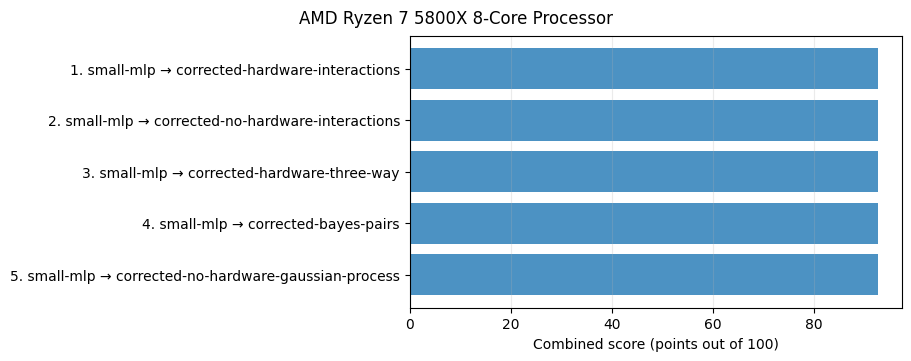

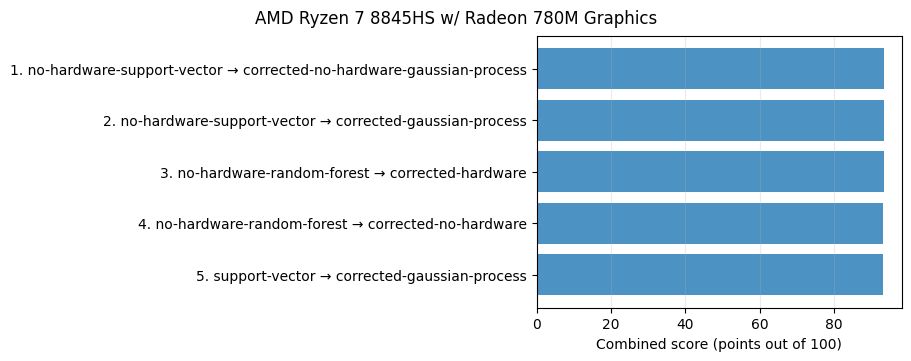

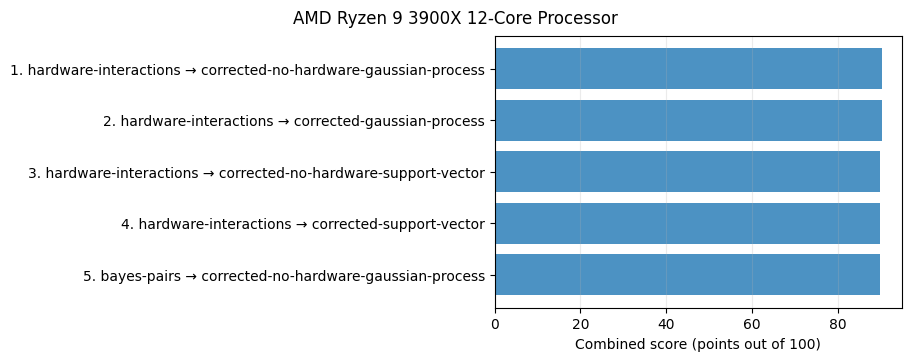

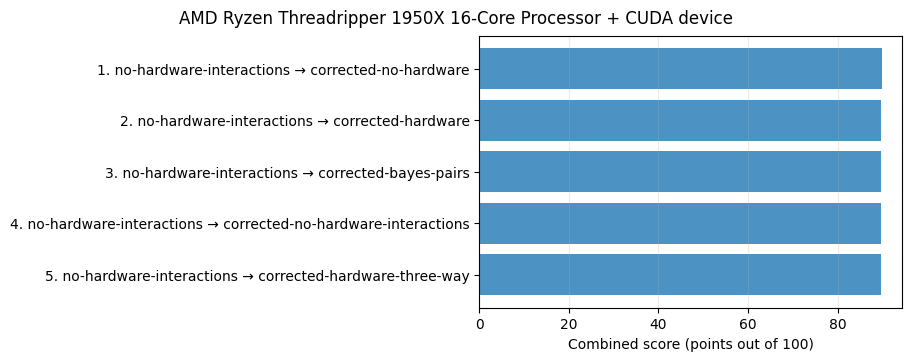

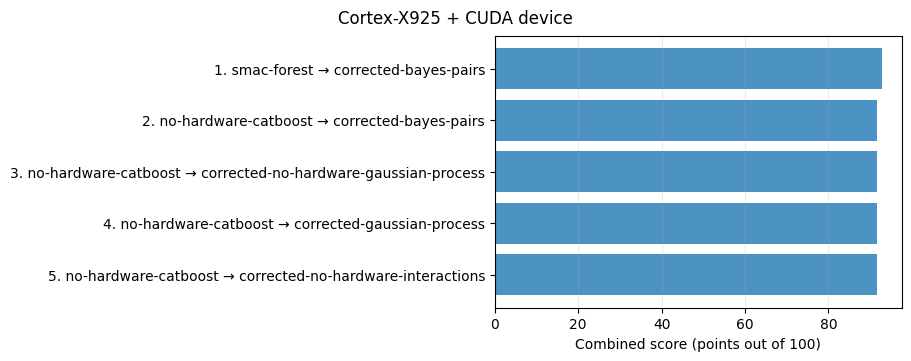

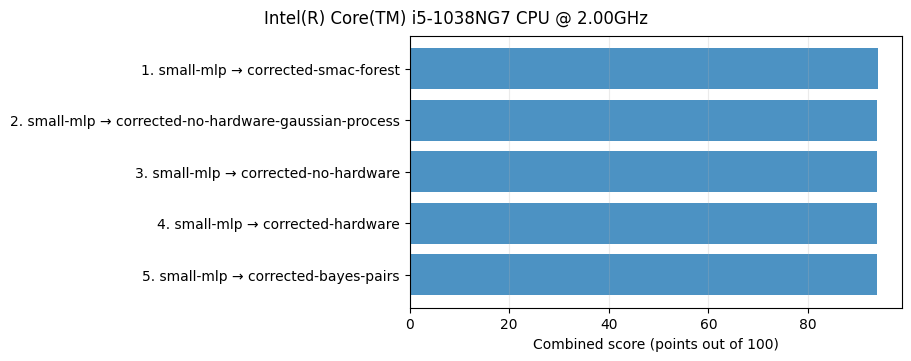

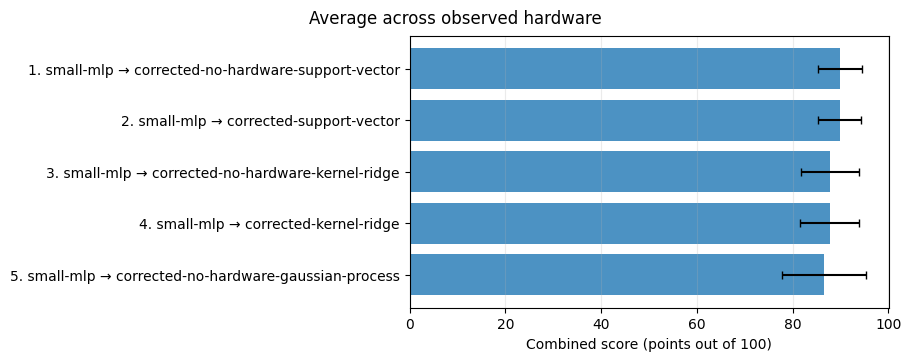

In [69]:
plot_bars(combined_top, "Combined score (points out of 100)")

### Cross-hardware breakdown

**Average across observed hardware**

,Application,Workload,Historical,Local,Mean (score points),95% CI lower,95% CI upper,Platforms
Average rank,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-support-vector,89.87510397,85.36983325,94.38037469,6
2,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-support-vector,89.81684550,85.30779100,94.32590001,6
3,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-kernel-ridge,87.82528293,81.72592509,93.92464076,6
4,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-kernel-ridge,87.73597118,81.62388223,93.84806014,6
5,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-gaussian-process,86.59076592,77.81387256,95.36765927,6


**AMD Ryzen 7 5800X 8-Core Processor**

,Application,Workload,Historical,Local,Mean (score points),95% CI lower,95% CI upper,Seeds,Difference from average (score points)
Average rank,,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-support-vector,92.32062724,—,—,1,2.44552327
2,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-support-vector,92.21939487,—,—,1,2.40254936
3,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-kernel-ridge,91.42860395,—,—,1,3.60332103
4,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-kernel-ridge,91.17072389,—,—,1,3.43475271
5,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-gaussian-process,92.76294162,—,—,1,6.17217571


**AMD Ryzen 7 8845HS w/ Radeon 780M Graphics**

,Application,Workload,Historical,Local,Mean (score points),95% CI lower,95% CI upper,Seeds,Difference from average (score points)
Average rank,,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-support-vector,92.72944474,—,—,1,2.85434077
2,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-support-vector,92.66734902,—,—,1,2.85050352
3,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-kernel-ridge,91.70187390,—,—,1,3.87659098
4,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-kernel-ridge,91.63875135,—,—,1,3.90278017
5,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-gaussian-process,92.99736989,—,—,1,6.40660397


... (4 outputs left out)

**Cortex-X925 + CUDA device**

,Application,Workload,Historical,Local,Mean (score points),95% CI lower,95% CI upper,Seeds,Difference from average (score points)
Average rank,,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-support-vector,89.49138356,—,—,1,-0.38372042
2,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-support-vector,89.40315751,—,—,1,-0.41368799
3,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-kernel-ridge,89.40721408,—,—,1,1.58193115
4,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-kernel-ridge,89.33417835,—,—,1,1.59820717
5,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-gaussian-process,73.20564490,—,—,1,-13.38512101


**Intel(R) Core(TM) i5-1038NG7 CPU @ 2.00GHz**

,Application,Workload,Historical,Local,Mean (score points),95% CI lower,95% CI upper,Seeds,Difference from average (score points)
Average rank,,,,,,,,,
1,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-support-vector,93.79769631,—,—,1,3.92259234
2,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-support-vector,93.76129246,—,—,1,3.94444696
3,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-kernel-ridge,89.37195128,—,—,1,1.54666836
4,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-kernel-ridge,89.29889553,—,—,1,1.56292435
5,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-gaussian-process,93.94620398,—,—,1,7.35543807


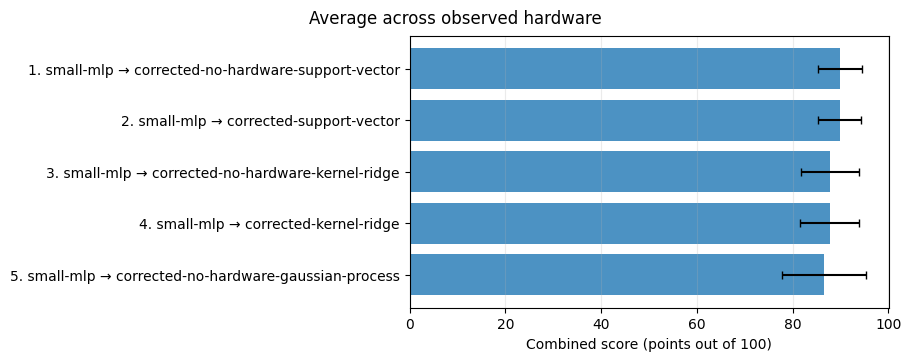

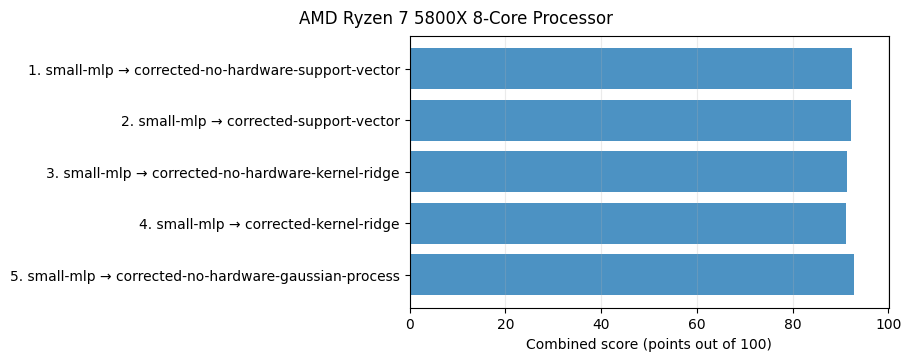

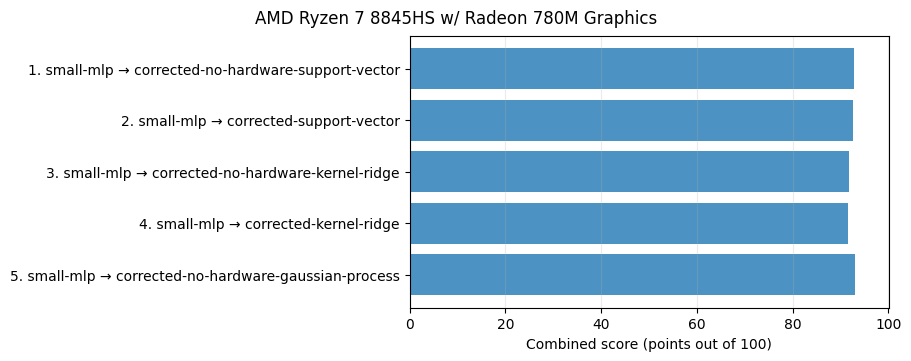

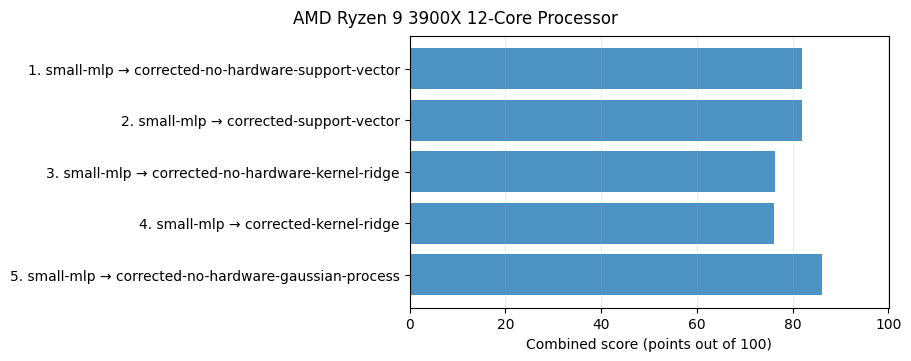

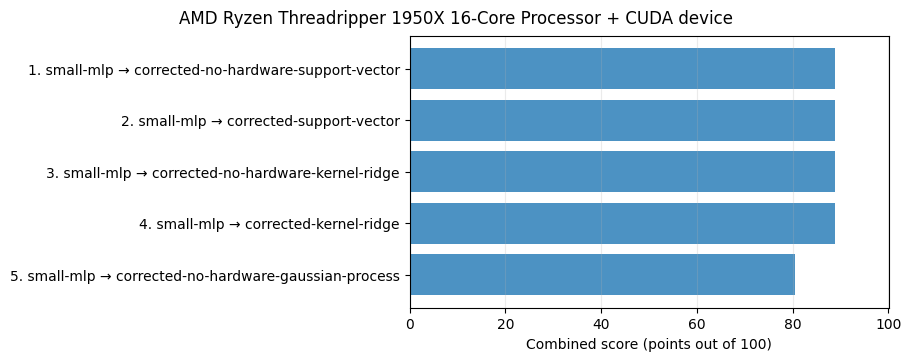

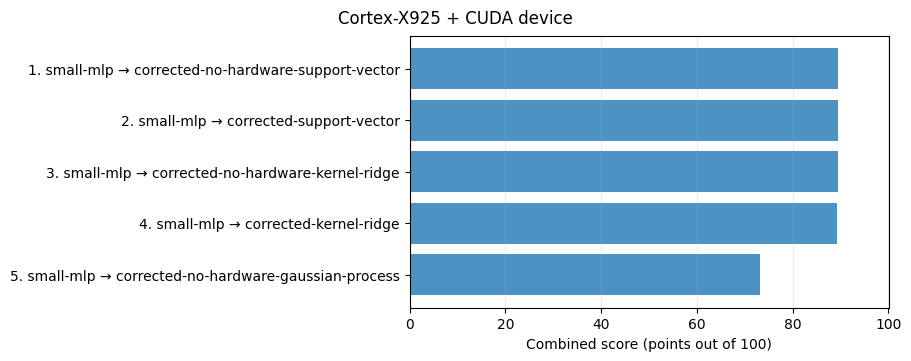

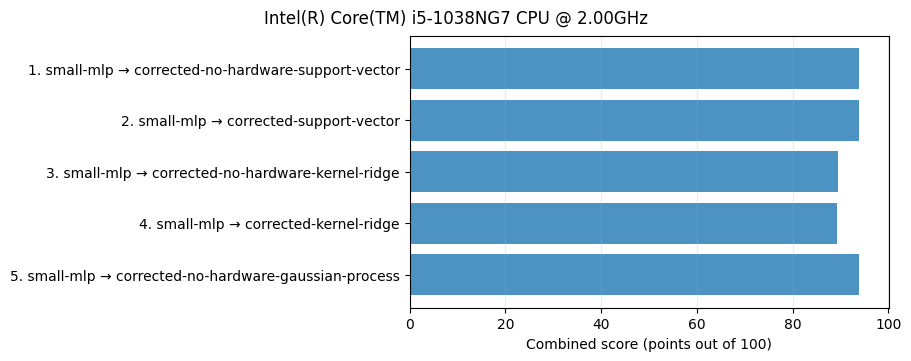

In [70]:
compare_hardware(combined_top, "combined", "score points", "Combined score (points out of 100)")

## 8. Top combinations across metrics

This table includes every combination that places in the top $x$ for at least one hardware-averaged metric, where $x$ is the larger of `TABLE_TOP_N` and `PLOT_TOP_N`. A combination is identified by its application, workload, historical model, and local model.

Each metric shows the combination's rank in the full hardware-averaged ranking and its mean in the original units. An em dash means the combination was ineligible for that metric across all platforms. Rows are ordered by their best rank across metrics.

In [71]:
if HARDWARE is not None:
    print("Set HARDWARE = None to show the summary across all platforms.")
else:
    average_scope = "Average across observed hardware"
    summary_limit = max(TABLE_TOP_N, PLOT_TOP_N)
    metric_rankings = {
        "Final accuracy (%)": final_top,
        "Accuracy gain (pp)": improvement_top,
        "Final recommendation quality (%)": pool_final_top,
        "Recommendation quality gain (pp)": pool_gain_top,
        "Convergence (round)": convergence_top,
        "Prediction (ms/round)": prediction_seconds_top,
        "Next sample (ms/round)": next_sample_seconds_top,
        "Refit (ms/round)": refit_seconds_top,
        "Combined score (points)": combined_top,
    }
    metric_results = {}
    for label, ranked in metric_rankings.items():
        average = ranked[average_scope].set_index(COMBO)
        metric_results[label] = pd.DataFrame({
            "Rank": pd.array(range(1, len(average) + 1), dtype="Int64"),
            "Mean": average["mean"],
        }, index=average.index)

    selected = pd.concat([result.head(summary_limit).index.to_frame(index=False)
                          for result in metric_results.values()]).drop_duplicates()
    if selected.empty:
        print("No combinations selected for the hardware-averaged summary.")
    else:
        selected_index = pd.MultiIndex.from_frame(selected)
        summary = pd.concat({label: result.reindex(selected_index)
                             for label, result in metric_results.items()}, axis=1)
        best_rank = summary.xs("Rank", level=1, axis=1).min(axis=1)
        summary = summary.loc[best_rank.sort_values(kind="stable").index]
        summary.index.names = ["Application", "Workload", "Historical", "Local"]
        print(f"{len(summary)} unique combinations from the top {summary_limit} per metric")
        display(summary.style.format(precision=8, na_rep="—"))

59 unique combinations from the top 10 per metric
